# Datafest 2026, reto preliminar: modelo de propensión a la conversión

**Notebook de solución completa, de los datos crudos al archivo de entrega.**

Este notebook resuelve el reto preliminar del Datafest 2026 siguiendo el flujo del Documento Metodológico del Modelo de Cobranzas de Mora Tardía Tramos 3 y 4, adaptado a un problema de propensión comercial. Cada etapa deja figuras en formato vectorial (SVG y PDF) en la carpeta figuras, tablas y modelos en la carpeta artefactos, y el archivo de envío en la carpeta entrega.

Estructura del notebook:

1. Identificación del problema bancario y encuadre.
2. Configuración del entorno.
3. Carga de datos y auditoría de calidad.
4. Embudo 1: población objetivo, target, horizonte y particiones.
5. Análisis exploratorio de datos.
6. Pruebas de fuga de datos.
7. Ingeniería de variables con hipótesis de negocio.
8. Embudo 2: selección de variables.
9. Modelado: zoológico de modelos.
10. Ajuste bayesiano de hiperparámetros con Optuna.
11. Ablaciones.
12. Explicabilidad con SHAP.
13. Validación: Gini, KS, tablas de eficiencia y desempeño temporal.
14. Calibración, score de 0 a 1000, niveles y prioridad.
15. Entrenamiento final y envío.
16. Artefactos, supuestos y siguientes pasos.

## 1. Identificación del problema bancario

**Qué pide el reto.** Cada fila es un cliente observado en un mes. El objetivo vale 1 cuando el cliente realiza su primera conversión en ese mes, y la nota del diccionario de datos indica que un cliente con objetivo 1 no vuelve a aparecer en meses posteriores. Se entrena con enero a noviembre de 2026 y se predice diciembre de 2026. La métrica es el coeficiente de Gini, que equivale a dos veces el AUC menos uno, por lo que solo importa el orden de los clientes.

**Familia del problema.** Según el catálogo de problemas de banca del equipo, este caso pertenece a la familia de negocio y marketing, en la categoría de propensión a compra o venta cruzada: estimar qué clientes tienen mayor probabilidad de contratar o activar un producto para priorizar el contacto comercial. Por su estructura, además, es un modelo de supervivencia en tiempo discreto: cada mes el cliente está en riesgo de convertir, y cuando convierte sale de la población. La probabilidad mensual que estima el modelo es, por tanto, una tasa de riesgo mensual (hazard).

**Correspondencia con el documento metodológico.** El documento resuelve un problema de cobranzas, pero su embudo es el mismo que aplicamos aquí. La tabla de correspondencia se construye en la celda siguiente.

In [1]:
import pandas as pd
correspondencia = pd.DataFrame([
    ('Unidad de observación', 'Cliente por cosecha mensual, visión cliente', 'Cliente por mes'),
    ('Población objetivo', 'Clientes con mora de 61 a 120 días', 'Clientes aún no convertidos presentes en el mes'),
    ('Punto de observación', 'Fin de mes, variables al día 27', 'Mes AAAAMM'),
    ('Evento y ventana', 'Pago que reduce la mora un tramo en 30 días', 'Primera conversión dentro del mes'),
    ('Particiones', 'Train 202401 a 202505, OOT 202506 a 202508', 'Desarrollo 202601 a 202608, OOT 202609 a 202611, competencia 202612'),
    ('Modelo', 'LightGBM con ajuste bayesiano', 'LightGBM con Optuna, comparado contra otros modelos'),
    ('Selección de variables', 'Calidad, SHAP, correlación, negocio, parsimonia', 'El mismo embudo'),
    ('Validación', 'Gini, KS, tablas de eficiencia, desempeño temporal', 'Las mismas pruebas'),
    ('Salida de negocio', 'Probabilidad calibrada, score 0 a 1000, niveles, prioridad por deuda', 'Probabilidad, score 0 a 1000, niveles, prioridad por saldo'),
], columns=['concepto', 'documento_cobranzas_t3_t4', 'reto_datafest_2026']).set_index('concepto')
correspondencia

,documento_cobranzas_t3_t4,reto_datafest_2026
concepto,,
Unidad de observación,"Cliente por cosecha mensual, visión cliente",Cliente por mes
Población objetivo,Clientes con mora de 61 a 120 días,Clientes aún no convertidos presentes en el mes
Punto de observación,"Fin de mes, variables al día 27",Mes AAAAMM
Evento y ventana,Pago que reduce la mora un tramo en 30 días,Primera conversión dentro del mes
Particiones,"Train 202401 a 202505, OOT 202506 a 202508","Desarrollo 202601 a 202608, OOT 202609 a 20261..."
Modelo,LightGBM con ajuste bayesiano,"LightGBM con Optuna, comparado contra otros mo..."
Selección de variables,"Calidad, SHAP, correlación, negocio, parsimonia",El mismo embudo
Validación,"Gini, KS, tablas de eficiencia, desempeño temp...",Las mismas pruebas
Salida de negocio,"Probabilidad calibrada, score 0 a 1000, nivele...","Probabilidad, score 0 a 1000, niveles, priorid..."


**Las siete preguntas del encuadre.**

1. Decisión de negocio: a qué clientes contactar en diciembre con una oferta comercial, dado un presupuesto limitado de contactos.
2. Unidad de observación: cliente por mes.
3. Población objetivo: clientes presentes en el mes que aún no han convertido; diciembre es la población de aplicación.
4. Evento y ventana: primera conversión dentro del mes de observación.
5. Punto de observación: el mes AAAAMM; toda variable debe estar disponible al inicio de ese mes.
6. Comparación de referencia: una regla experta que ordena por banda de riesgo y número de productos, y la selección aleatoria.
7. Medida de éxito: Gini en la muestra fuera de tiempo como métrica técnica, y captura de conversiones por porcentaje de clientes contactados como métrica de negocio.

## 2. Configuración del entorno

Se usa el entorno conda datafest. Todas las funciones auxiliares se definen dentro del notebook, sin módulos externos, para que el flujo sea autocontenido y reproducible. La semilla se fija en 42 para todos los procesos aleatorios.

Decisiones de visualización: las figuras se guardan en SVG y PDF porque son formatos vectoriales, escalan sin pérdida en la presentación y conservan el texto editable. Se usa una paleta categórica validada para daltonismo (azul, naranja y aqua en ese orden fijo), una rampa secuencial de un solo tono para magnitudes y una escala divergente con punto medio gris para correlaciones.

In [2]:
import os, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn, lightgbm as lgb, xgboost as xgb, catboost as cb, optuna, shap, joblib, optbinning
from optbinning import OptimalBinning, BinningProcess
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import KFold, GroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.isotonic import IsotonicRegression
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

SEMILLA = 42
np.random.seed(SEMILLA)
N_TRIALS = int(os.environ.get('N_TRIALS', 40))

RAIZ = Path.cwd().parent
DATOS = RAIZ.parent / '2026_Datafest Coding Test-20260929T230039Z-1-001' / 'Datafest Coding Test'
FIG, ART, ENT = RAIZ / 'figuras', RAIZ / 'artefactos', RAIZ / 'entrega'
for carpeta in (FIG, ART, ENT):
    carpeta.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948')
TINTA, TINTA2, GRILLA = '#0b0b0b', '#52514e', '#e4e3df'
mpl.rcParams.update({
    'svg.fonttype': 'none', 'pdf.fonttype': 42, 'figure.dpi': 110, 'font.size': 9.5,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': TINTA2,
    'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'lines.linewidth': 2, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'savefig.facecolor': 'white'})
CMAP_SEC = mpl.colors.LinearSegmentedColormap.from_list('azules', ['#f3f7fc', '#a9c9f0', AZUL, '#0e3b73'])
CMAP_DIV = mpl.colors.LinearSegmentedColormap.from_list('divergente', [NARANJA, '#f4f3ef', AZUL])
PCT = mpl.ticker.PercentFormatter(1, decimals=0)

def guardar(fig, nombre):
    """Guarda la figura en SVG y PDF (formatos vectoriales) y la muestra."""
    fig.savefig(FIG / f'{nombre}.svg', bbox_inches='tight')
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def psi(referencia, actual, bins=10):
    """Índice de estabilidad poblacional con cortes por cuantiles de la referencia."""
    ref, act = np.asarray(referencia, float), np.asarray(actual, float)
    if len(np.unique(ref)) <= 20:
        valores = np.union1d(np.unique(ref), np.unique(act))
        e = np.array([(ref == v).mean() for v in valores])
        a = np.array([(act == v).mean() for v in valores])
    else:
        cortes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
        cortes[0], cortes[-1] = -np.inf, np.inf
        e = np.histogram(ref, cortes)[0] / len(ref)
        a = np.histogram(act, cortes)[0] / len(act)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

def tabla_eficiencia(y, p, n=10):
    """Tabla de eficiencia por deciles: decil 1 es el de mayor probabilidad."""
    d = pd.DataFrame({'y': np.asarray(y, float), 'p': np.asarray(p, float)})
    d['decil'] = pd.qcut(d.p.rank(method='first', ascending=False), n, labels=range(1, n + 1)).astype(int)
    t = d.groupby('decil').agg(clientes=('y', 'size'), conversiones=('y', 'sum'), tasa_observada=('y', 'mean'),
                               prob_media=('p', 'mean'), prob_min=('p', 'min'), prob_max=('p', 'max'))
    t['captura_acumulada'] = t.conversiones.cumsum() / t.conversiones.sum()
    t['tasa_acumulada'] = t.conversiones.cumsum() / t.clientes.cumsum()
    t['lift'] = t.tasa_observada / d.y.mean()
    return t

versiones = pd.Series({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                       'duckdb': duckdb.__version__, 'scikit_learn': sklearn.__version__, 'lightgbm': lgb.__version__,
                       'xgboost': xgb.__version__, 'catboost': cb.__version__, 'optuna': optuna.__version__,
                       'shap': shap.__version__, 'optbinning': optbinning.__version__}, name='version')
versiones.to_csv(ART / '00_versiones.csv')
versiones.to_frame()

/home/germain/radioconda/envs/datafest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,version
python,3.11.16
pandas,2.3.3
numpy,2.4.6
duckdb,1.5.5
scikit_learn,1.9.0
lightgbm,4.7.0
xgboost,3.2.0
catboost,1.2.10
optuna,4.9.0
shap,0.51.0


## 3. Carga de datos y auditoría de calidad

Se leen los cuatro archivos de la carpeta del reto: train.csv, test.csv, sample_submission.csv y metaData.csv. Se usa pandas para la manipulación y DuckDB para las consultas de auditoría, porque las reglas de negocio del panel se expresan de forma más clara y verificable en SQL. Con 120 mil filas no hace falta un motor distribuido.

La auditoría responde a la sección 3.5.1 del documento: tipos, nulos, duplicados, rangos y coherencia entre archivos.

In [3]:
tr_raw = pd.read_csv(DATOS / 'train.csv')
te_raw = pd.read_csv(DATOS / 'test.csv')
ss_raw = pd.read_csv(DATOS / 'sample_submission.csv')
meta = pd.read_csv(DATOS / 'metaData.csv')
con = duckdb.connect()
con.register('train', tr_raw)
con.register('test', te_raw)
print(f'train {tr_raw.shape}, test {te_raw.shape}, sample_submission {ss_raw.shape}, metaData {meta.shape}')
meta

train (110100, 25), test (9900, 24), sample_submission (9900, 2), metaData (26, 4)


,column_name,description,type,notes
0,id_cliente,Identificador único del cliente,int,Un cliente puede aparecer en varios meses y si...
1,mes,Mes calendario en formato AAAAMM,int,El split temporal se realiza por ventana mensu...
2,edad,Edad del cliente,int,Variable numérica
3,ingresos,Ingresos anuales,float,Variable numérica
4,ratio_deuda_ingresos,Ratio de deuda sobre ingresos,float,Variable numérica
5,antiguedad_cuenta_meses,Antigüedad de la cuenta del cliente en meses,int,Variable numérica
6,numero_productos,Número de productos bancarios activos del cliente,int,Variable numérica
7,saldo_promedio,Saldo promedio de la cuenta,float,Variable numérica
8,dias_ultima_transaccion,Días desde la última transacción,int,Variable numérica
9,ocupacion,Categoría laboral del cliente,string,Variable categórica


In [4]:
calidad = pd.DataFrame({
    'tipo_pandas': tr_raw.dtypes.astype(str),
    'nulos_train': tr_raw.isna().sum(),
    'nulos_test': te_raw.reindex(columns=tr_raw.columns).isna().sum().where(tr_raw.columns != 'objetivo'),
    'unicos_train': tr_raw.nunique(),
    'unicos_test': te_raw.reindex(columns=tr_raw.columns).nunique(),
}).join(meta.set_index('column_name')[['type']].rename(columns={'type': 'tipo_metadata'}))
calidad.to_csv(ART / '03_calidad_columnas.csv')
calidad

,tipo_pandas,nulos_train,nulos_test,unicos_train,unicos_test,tipo_metadata
id_cliente,int64,0,0.0,24628,9900,int
mes,int64,0,0.0,11,1,int
edad,int64,0,0.0,50,50,int
ingresos,float64,0,0.0,24232,9739,float
ratio_deuda_ingresos,float64,0,0.0,24582,9884,float
antiguedad_cuenta_meses,int64,0,0.0,179,179,int
numero_productos,int64,0,0.0,5,5,int
saldo_promedio,float64,0,0.0,22985,9233,float
dias_ultima_transaccion,int64,0,0.0,364,364,int
ocupacion,object,0,0.0,5,5,string


In [5]:
controles = {
    'duplicados id_cliente y mes en train': con.sql('select count(*) from (select id_cliente, mes from train group by 1, 2 having count(*) > 1)').fetchone()[0],
    'duplicados id_cliente en test': con.sql('select count(*) from (select id_cliente from test group by 1 having count(*) > 1)').fetchone()[0],
    'meses distintos en test': te_raw.mes.nunique(),
    'mes de test': int(te_raw.mes.iloc[0]),
    'columnas de test iguales a train sin objetivo': list(te_raw.columns) == [c for c in tr_raw.columns if c != 'objetivo'],
    'orden de sample_submission igual a test': bool((ss_raw.id_cliente.values == te_raw.id_cliente.values).all()),
    'columnas de sample_submission': list(ss_raw.columns),
    'objetivo binario': sorted(tr_raw.objetivo.unique().tolist()),
    'edad mínima y máxima': (int(tr_raw.edad.min()), int(tr_raw.edad.max())),
    'ratio deuda ingresos dentro de 0 y 1': bool(tr_raw.ratio_deuda_ingresos.between(0, 1).all()),
    'día preferido de pago mínimo y máximo': (int(tr_raw.dia_preferido_pago.min()), int(tr_raw.dia_preferido_pago.max())),
    'ingresos y saldo positivos': bool((tr_raw.ingresos > 0).all() and (tr_raw.saldo_promedio > 0).all()),
    'nulos totales en train y test': int(tr_raw.isna().sum().sum() + te_raw.isna().sum().sum()),
}
pd.Series(controles, name='resultado').to_frame()

,resultado
duplicados id_cliente y mes en train,0
duplicados id_cliente en test,0
meses distintos en test,1
mes de test,202612
columnas de test iguales a train sin objetivo,True
orden de sample_submission igual a test,True
columnas de sample_submission,"[id_cliente, prediccion]"
objetivo binario,"[0, 1]"
edad mínima y máxima,"(22, 71)"
ratio deuda ingresos dentro de 0 y 1,True


**Lectura.** Los datos llegan limpios: no hay nulos, ni duplicados de cliente y mes, ni valores fuera de rango, y los tipos coinciden con metaData.csv. El test contiene un único mes (202612) con las mismas columnas que train salvo objetivo, y sample_submission conserva el orden de test, de modo que el envío debe respetar ese orden. Como no hay nulos, la regla de imputación del documento (9999 para los días desde un evento y 0 para el resto) no se necesita, aunque quedaría lista si el banco entregara datos con faltantes.

## 4. Embudo 1: población objetivo, target, horizonte y particiones

El documento metodológico define primero sobre quién se aplica el modelo y cómo se construye el indicador objetivo, y solo después modela. Aquí el target ya viene dado, pero hay que verificar qué representa. Se comprueban tres reglas con SQL:

1. Ningún cliente aparece después del mes en que convirtió.
2. Ningún cliente convierte dos veces.
3. Ningún cliente de diciembre convirtió antes en el entrenamiento.

Si las tres se cumplen, la población de cada mes es la población en riesgo de un modelo de supervivencia discreto, y diciembre es una población de clientes aún no convertidos, coherente con el entrenamiento.

In [6]:
reglas = con.sql('''
    with conv as (select id_cliente, min(mes) as mes_conv, sum(objetivo) as n_conv
                  from train where objetivo = 1 group by 1)
    select
        (select count(*) from train t join conv c using (id_cliente) where t.mes > c.mes_conv) as filas_posteriores_a_conversion,
        (select count(*) from conv where n_conv > 1) as clientes_con_dos_conversiones,
        (select count(*) from test t join conv c using (id_cliente)) as clientes_test_ya_convertidos,
        (select count(distinct id_cliente) from train) as clientes_train,
        (select count(*) from test where id_cliente in (select id_cliente from train)) as clientes_test_vistos_en_train
''').df().T.rename(columns={0: 'valor'})
reglas

,valor
filas_posteriores_a_conversion,0
clientes_con_dos_conversiones,0
clientes_test_ya_convertidos,0
clientes_train,24628
clientes_test_vistos_en_train,8061


In [7]:
CATEGORICAS = ['ocupacion', 'region', 'canal_adquisicion', 'banda_riesgo', 'dispositivo_principal']
BOOLEANAS = ['tiene_tarjeta_credito', 'activo_movil', 'es_nuevo_cliente', 'tiene_prestamo', 'tiene_seguro']
NUMERICAS = ['edad', 'ingresos', 'ratio_deuda_ingresos', 'antiguedad_cuenta_meses', 'numero_productos',
             'saldo_promedio', 'dias_ultima_transaccion', 'antiguedad_direccion_meses',
             'visitas_web_ultimos_90_dias', 'distancia_sucursal_km', 'dia_preferido_pago']
SOSPECHOSA = 'dias_ultima_interaccion'
TARGET = 'objetivo'
BASE = NUMERICAS + CATEGORICAS + BOOLEANAS

# Panel maestro: train y competencia juntos, ordenados por cliente y mes.
panel = pd.concat([tr_raw.assign(muestra='train'), te_raw.assign(muestra='competencia', objetivo=np.nan)],
                  ignore_index=True).sort_values(['id_cliente', 'mes']).reset_index(drop=True)
for c in BOOLEANAS:
    panel[c] = panel[c].astype(int)
# Las categorías se fijan con los valores de train para que la codificación sea idéntica en todas las muestras.
TIPOS_CAT = {c: pd.CategoricalDtype(sorted(tr_raw[c].unique())) for c in CATEGORICAS}
for c in CATEGORICAS:
    panel[c] = panel[c].astype(TIPOS_CAT[c])
# Historial del cliente calculado solo con meses anteriores (se audita en la sección de fuga).
panel['meses_previos_panel'] = panel.groupby('id_cliente').cumcount()
panel['cliente_conocido'] = (panel.meses_previos_panel > 0).astype(int)
panel['primer_mes'] = panel.groupby('id_cliente').mes.transform('min')

# Variables estáticas: se verifica cuáles cambian dentro de un mismo cliente.
variacion = pd.Series({c: float((panel.groupby('id_cliente')[c].nunique() > 1).mean())
                       for c in BASE + [SOSPECHOSA]}, name='porcentaje_clientes_con_cambios')
variacion.sort_values(ascending=False).to_frame().head(6)

,porcentaje_clientes_con_cambios
dias_ultima_interaccion,0.633581
edad,0.000000
ratio_deuda_ingresos,0.000000
antiguedad_cuenta_meses,0.000000
numero_productos,0.000000
ingresos,0.000000


**Lectura.** Las tres reglas se cumplen: no hay filas posteriores a una conversión, no hay dobles conversiones y ningún cliente de diciembre convirtió antes. El panel tiene 24 628 clientes y 8061 de los 9900 clientes de diciembre (81 por ciento) ya aparecieron en el entrenamiento, siempre con objetivo 0. Además, todas las variables son fijas por cliente salvo dias_ultima_interaccion, que cambia en el 63 por ciento de los clientes. De aquí salen dos riesgos que guían todo el diseño: el modelo puede memorizar clientes, y cualquier diferencia de un cliente entre meses proviene solo de esa variable.

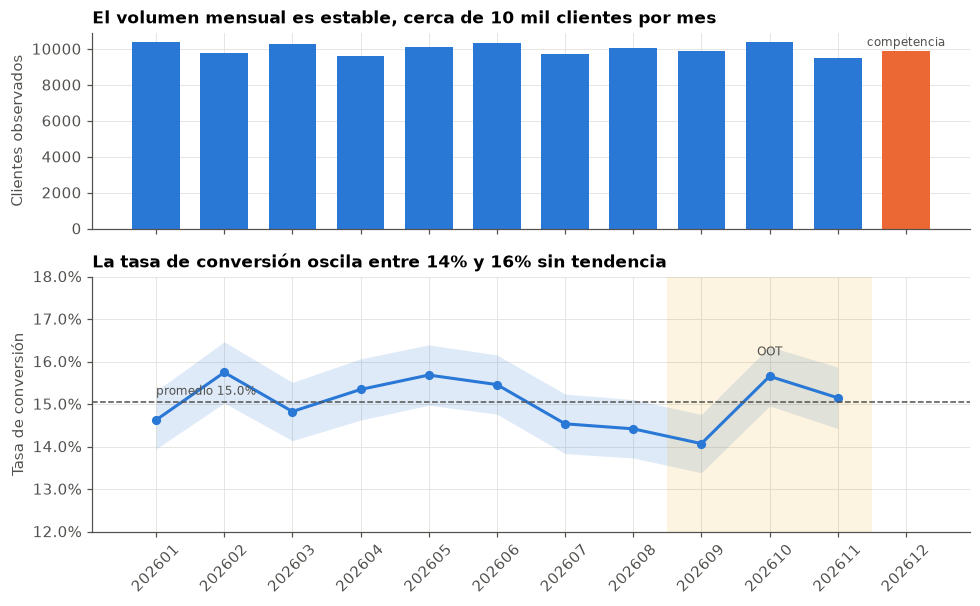

mes,202601,202602,202603,202604,202605,202606,202607,202608,202609,202610,202611
n,10400.00000,9800.000000,10300.000000,9600.000000,10100.000000,10350.000000,9700.000000,10050.000000,9900.000000,10400.000000,9500.000000
tasa,0.14625,0.157449,0.148252,0.153438,0.156832,0.154589,0.145361,0.144179,0.140707,0.156538,0.151474


In [8]:
es_train = panel.muestra.eq('train')
mensual = panel[es_train].groupby('mes').agg(n=(TARGET, 'size'), tasa=(TARGET, 'mean'))
n_dic = int((panel.muestra == 'competencia').sum())
x = np.arange(12)
etiquetas = [str(m) for m in mensual.index] + ['202612']
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={'height_ratios': [1, 1.3]})
a1.bar(x[:11], mensual.n, color=AZUL, width=0.7)
a1.bar(11, n_dic, color=NARANJA, width=0.7)
a1.text(11, n_dic * 1.01, 'competencia', ha='center', va='bottom', fontsize=8, color=TINTA2)
a1.set_ylabel('Clientes observados')
a1.set_title('El volumen mensual es estable, cerca de 10 mil clientes por mes')
se = np.sqrt(mensual.tasa * (1 - mensual.tasa) / mensual.n)
a2.fill_between(x[:11], mensual.tasa - 1.96 * se, mensual.tasa + 1.96 * se, color=AZUL, alpha=0.15, lw=0)
a2.plot(x[:11], mensual.tasa, color=AZUL, marker='o', ms=5)
tasa_global = panel.loc[es_train, TARGET].mean()
a2.axhline(tasa_global, color=TINTA2, ls='--', lw=1)
a2.text(0, tasa_global + 0.001, f'promedio {tasa_global:.1%}', fontsize=8, color=TINTA2, va='bottom')
a2.axvspan(7.5, 10.5, color=AMARILLO, alpha=0.12, lw=0)
a2.text(9, mensual.tasa.max() + 0.004, 'OOT', ha='center', fontsize=8, color=TINTA2)
a2.set_ylim(0.12, 0.18)
a2.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
a2.set_ylabel('Tasa de conversión')
a2.set_title('La tasa de conversión oscila entre 14% y 16% sin tendencia')
a2.set_xticks(x)
a2.set_xticklabels(etiquetas, rotation=45)
fig.tight_layout()
guardar(fig, '01_volumen_y_tasa_mensual')
mensual.T

**Lectura.** La tasa mensual se mueve entre 14,1 por ciento (septiembre) y 15,7 por ciento (febrero), dentro de los intervalos de confianza y sin tendencia; el volumen también es estable. No hay meses atípicos que excluir, a diferencia del documento, que retiró periodos con campañas puntuales de cobranza. Se pueden usar todos los meses para entrenar.

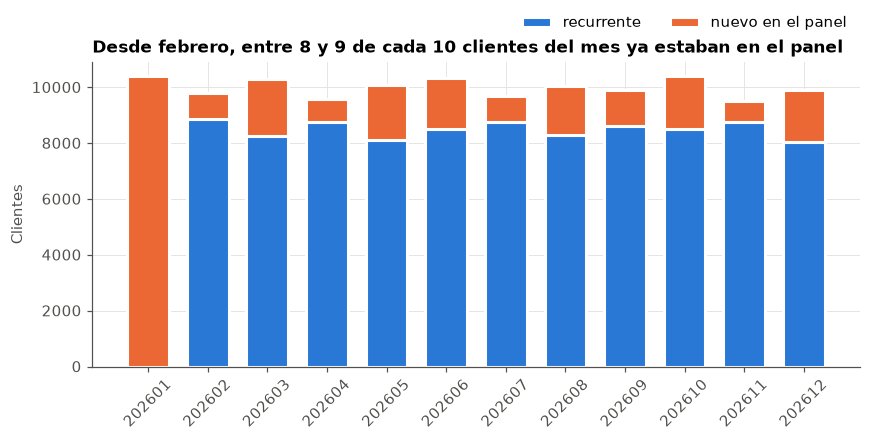

mes,202601,202602,202603,202604,202605,202606,202607,202608,202609,202610,202611,202612
tipo,,,,,,,,,,,,
nuevo en el panel,10400.0,921.00000,2043.00000,827.000000,1973.000000,1834.000000,950.000000,1760.000000,1299.000000,1893.000000,728.000000,1839.000000
recurrente,0.0,8879.00000,8257.00000,8773.000000,8127.000000,8516.000000,8750.000000,8290.000000,8601.000000,8507.000000,8772.000000,8061.000000
porcentaje_nuevos,1.0,0.09398,0.19835,0.086146,0.195347,0.177198,0.097938,0.175124,0.131212,0.182019,0.076632,0.185758


In [9]:
composicion = panel.assign(tipo=np.where(panel.mes == panel.primer_mes, 'nuevo en el panel', 'recurrente'))
composicion = composicion.groupby(['mes', 'tipo']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x, composicion['recurrente'], color=AZUL, width=0.7, edgecolor='white', linewidth=2, label='recurrente')
ax.bar(x, composicion['nuevo en el panel'], bottom=composicion['recurrente'], color=NARANJA, width=0.7,
       edgecolor='white', linewidth=2, label='nuevo en el panel')
ax.set_xticks(x)
ax.set_xticklabels(composicion.index.astype(str), rotation=45)
ax.set_ylabel('Clientes')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.06), ncol=2)
ax.set_title('Desde febrero, entre 8 y 9 de cada 10 clientes del mes ya estaban en el panel')
guardar(fig, '02_composicion_nuevos_recurrentes')
composicion.assign(porcentaje_nuevos=lambda d: d['nuevo en el panel'] / d.sum(axis=1)).T

**Lectura.** Enero está censurado por la izquierda: todos sus clientes figuran como nuevos porque el panel empieza ahí, no porque lo sean. Desde febrero entra entre 8 y 20 por ciento de clientes nuevos cada mes; en diciembre, 19 por ciento. Esta censura explica por qué más adelante se descarta la variable de permanencia en el panel.

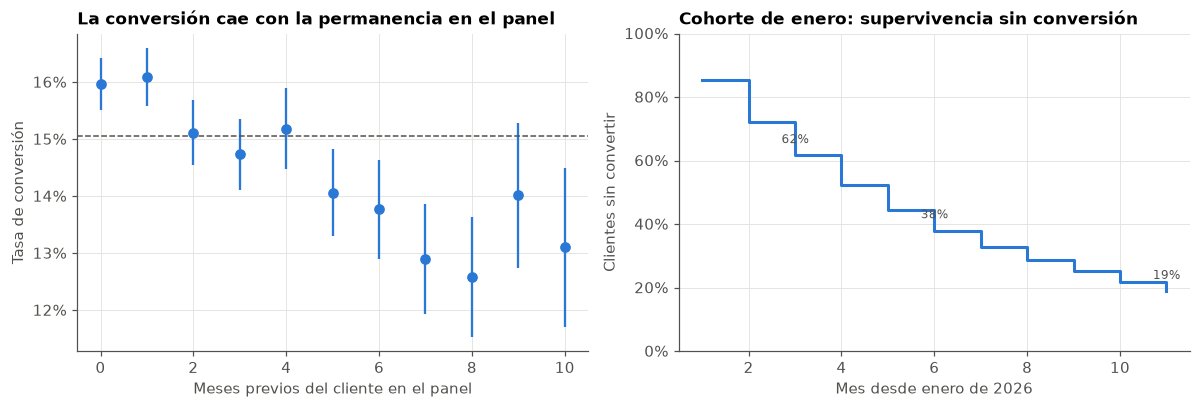

meses_previos_panel,0,1,2,3,4,5,6,7,8,9,10
mean,0.1597,0.1609,0.1512,0.1473,0.1518,0.1406,0.1377,0.1289,0.1259,0.1402,0.1310
size,24628.0000,20110.0000,15593.0000,12489.0000,9760.0000,7864.0000,6101.0000,4630.0000,3805.0000,2861.0000,2259.0000
se,0.0023,0.0026,0.0029,0.0032,0.0036,0.0039,0.0044,0.0049,0.0054,0.0065,0.0071


In [10]:
por_k = panel[es_train].groupby('meses_previos_panel')[TARGET].agg(['mean', 'size'])
por_k['se'] = np.sqrt(por_k['mean'] * (1 - por_k['mean']) / por_k['size'])
# Curva de supervivencia de la cohorte de enero (estimador de Kaplan Meier en tiempo discreto).
cohorte = panel[es_train & (panel.primer_mes == 202601)]
riesgo = cohorte.groupby('mes')[TARGET].agg(['sum', 'size'])
riesgo['hazard'] = riesgo['sum'] / riesgo['size']
riesgo['supervivencia'] = (1 - riesgo['hazard']).cumprod()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.errorbar(por_k.index, por_k['mean'], yerr=1.96 * por_k['se'], fmt='o', color=AZUL, ms=6, capsize=0, lw=1.5)
a1.axhline(tasa_global, color=TINTA2, ls='--', lw=1)
a1.yaxis.set_major_formatter(PCT)
a1.set_xlabel('Meses previos del cliente en el panel')
a1.set_ylabel('Tasa de conversión')
a1.set_title('La conversión cae con la permanencia en el panel')
a2.step(np.arange(1, 12), riesgo['supervivencia'], where='post', color=AZUL)
a2.set_ylim(0, 1)
a2.yaxis.set_major_formatter(PCT)
a2.set_xlabel('Mes desde enero de 2026')
a2.set_ylabel('Clientes sin convertir')
a2.set_title('Cohorte de enero: supervivencia sin conversión')
for i in (3, 6, 11):
    a2.annotate(f"{riesgo['supervivencia'].iloc[i - 1]:.0%}", (i, riesgo['supervivencia'].iloc[i - 1]),
                textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8, color=TINTA2)
fig.tight_layout()
guardar(fig, '03_conversion_por_permanencia_y_supervivencia')
por_k.round(4).T

**Lectura.** La tasa baja de 16 por ciento en los primeros meses a cerca de 13 por ciento tras siete u ocho meses en el panel: los clientes más propensos convierten pronto y salen, y quedan los menos propensos (selección por supervivencia). En la cohorte de enero, la mitad convierte entre el cuarto y el quinto mes, y solo 19 por ciento sigue sin convertir al cierre de noviembre. Para el negocio, un cliente que lleva muchos meses sin convertir es, en promedio, menos receptivo.

### 4.1 Particiones de la muestra

Se replica la lógica del documento metodológico, que separa una muestra de entrenamiento, una de prueba y una fuera de tiempo (OOT):

* **Desarrollo, enero a agosto de 2026.** Se divide por cliente en entrenamiento (80 por ciento de los clientes) y prueba (20 por ciento). La división es agrupada por cliente porque un mismo cliente aparece varias veces con las mismas variables; si sus filas se repartieran entre entrenamiento y prueba, el modelo sería evaluado sobre clientes que ya vio.
* **OOT, septiembre a noviembre de 2026.** Tres meses posteriores, como en el documento (junio a agosto de 2025). Es la muestra que mejor imita la aplicación real del modelo sobre un mes futuro y es la referencia principal de desempeño.
* **Competencia, diciembre de 2026.** Sin target; se predice con el modelo final reentrenado con enero a noviembre.

El ajuste de hiperparámetros se hace solo con la muestra de entrenamiento mediante validación temporal, de modo que prueba y OOT quedan intactas para medir.

In [11]:
m_dev = es_train & (panel.mes <= 202608)
m_oot = es_train & (panel.mes >= 202609)
m_dic = panel.muestra.eq('competencia')
rng = np.random.default_rng(SEMILLA)
clientes_dev = np.sort(panel.loc[m_dev, 'id_cliente'].unique())
clientes_prueba = rng.choice(clientes_dev, size=int(0.2 * len(clientes_dev)), replace=False)
m_tst = m_dev & panel.id_cliente.isin(clientes_prueba)
m_trn = m_dev & ~panel.id_cliente.isin(clientes_prueba)
m_todo = es_train
MUESTRAS = {'entrenamiento': m_trn, 'prueba': m_tst, 'oot': m_oot}
assert not set(panel.loc[m_trn, 'id_cliente']) & set(panel.loc[m_tst, 'id_cliente'])

def resumen_muestra(nombre, mascara, meses):
    d = panel.loc[mascara]
    conv = d[TARGET].sum() if d[TARGET].notna().any() else np.nan
    return {'muestra': nombre, 'meses': meses, 'conversiones': conv, 'no_conversiones': len(d) - conv if conv == conv else np.nan,
            'tasa': d[TARGET].mean(), 'filas': len(d), 'clientes': d.id_cliente.nunique()}

ventanas = pd.DataFrame([
    resumen_muestra('Entrenamiento', m_trn, '202601 a 202608'),
    resumen_muestra('Prueba', m_tst, '202601 a 202608'),
    resumen_muestra('OOT', m_oot, '202609 a 202611'),
    resumen_muestra('Competencia', m_dic, '202612'),
])
embudo_poblacion = pd.DataFrame([
    ('Base inicial train', len(tr_raw)),
    ('Duplicados cliente y mes', len(tr_raw) - controles['duplicados id_cliente y mes en train']),
    ('Filas posteriores a la conversión', len(tr_raw) - int(reglas.loc['filas_posteriores_a_conversion', 'valor'])),
    ('Base final de desarrollo y OOT', int(es_train.sum())),
], columns=['paso', 'filas_restantes'])
ventanas.to_csv(ART / '04_ventanas_muestras.csv', index=False)
embudo_poblacion.to_csv(ART / '04_embudo_poblacion.csv', index=False)
display(embudo_poblacion)
ventanas

,paso,filas_restantes
0,Base inicial train,110100
1,Duplicados cliente y mes,110100
2,Filas posteriores a la conversión,110100
3,Base final de desarrollo y OOT,110100


,muestra,meses,conversiones,no_conversiones,tasa,filas,clientes
0,Entrenamiento,202601 a 202608,9702.0,54433.0,0.151275,64135,16567
1,Prueba,202601 a 202608,2405.0,13760.0,0.148778,16165,4141
2,OOT,202609 a 202611,4460.0,25340.0,0.149664,29800,12521
3,Competencia,202612,NaN,NaN,NaN,9900,9900


**Lectura.** El entrenamiento tiene 64 135 filas de 16 567 clientes; la prueba, 16 165 filas de 4141 clientes; y la OOT, 29 800 filas. Las tasas son casi idénticas (15,1, 14,9 y 15,0 por ciento), así que las diferencias de Gini entre muestras no se deben a cambios de prevalencia. No se aplicaron filtros de exclusión porque las tres reglas del panel se cumplen.

## 5. Análisis exploratorio de datos

El análisis exploratorio se hace sobre la muestra de desarrollo (enero a agosto) para que ninguna decisión de modelado se inspire en la OOT, que debe quedar como juez independiente. La única excepción es el análisis de estabilidad temporal, que por definición compara desarrollo, OOT y diciembre usando solo las variables explicativas, nunca el target de la OOT.

El orden sigue el documento: estadísticos descriptivos (3.5.1), relación de cada variable con el target, pruebas estadísticas, correlaciones, estabilidad temporal por variable (3.5.2) e interacciones.

### 5.1 Estadísticos descriptivos

In [12]:
dev = panel[m_dev]
def descriptivo(df, columnas):
    d = df[columnas].describe(percentiles=[0.25, 0.5, 0.75]).T
    d = d.rename(columns={'25%': 'q1', '50%': 'q2_mediana', '75%': 'q3', 'count': 'count'})
    d['missings'] = df[columnas].isna().sum()
    d['fill_rate'] = 1 - d['missings'] / len(df)
    d['asimetria'] = df[columnas].skew()
    return d

tabla_descriptiva = descriptivo(dev, NUMERICAS + BOOLEANAS + [SOSPECHOSA])
tabla_descriptiva.to_csv(ART / '05_tabla_descriptiva.csv')
tabla_descriptiva.round(3)

,count,mean,std,min,q1,q2_mediana,q3,max,missings,fill_rate,asimetria
edad,80300.0,46.366,14.332,22.000,34.000,46.000,59.000,71.000,0,1.0,0.013
ingresos,80300.0,65165.820,21790.674,18000.000,50125.509,64848.491,79752.701,145700.073,0,1.0,0.087
ratio_deuda_ingresos,80300.0,0.329,0.167,0.020,0.201,0.310,0.437,0.950,0,1.0,0.542
antiguedad_cuenta_meses,80300.0,89.076,51.578,1.000,44.000,89.000,133.000,179.000,0,1.0,0.020
numero_productos,80300.0,1.940,1.082,1.000,1.000,2.000,3.000,5.000,0,1.0,1.067
saldo_promedio,80300.0,26362.017,16081.894,300.000,14513.902,25767.603,37408.752,90000.000,0,1.0,0.305
dias_ultima_transaccion,80300.0,189.050,105.089,1.000,99.000,192.000,281.000,364.000,0,1.0,-0.078
antiguedad_direccion_meses,80300.0,119.797,68.794,1.000,60.000,120.000,179.000,239.000,0,1.0,0.003
visitas_web_ultimos_90_dias,80300.0,8.011,2.812,0.000,6.000,8.000,10.000,21.000,0,1.0,0.332
distancia_sucursal_km,80300.0,10.159,9.191,0.213,4.318,7.476,12.752,80.000,0,1.0,2.757


In [13]:
frecuencias = pd.concat({c: dev[c].value_counts(normalize=True) for c in CATEGORICAS}).rename('participacion').to_frame()
frecuencias.to_csv(ART / '05_frecuencias_categoricas.csv')
frecuencias.round(3).T

ocupacion                                           region                              canal_adquisicion                                   banda_riesgo              \
               clerical manual professional manager self_employed   west  north  south   east central               web mobile branch call_center partner          low medium high   
participacion       0.3  0.277        0.227   0.102         0.093   0.25  0.219  0.202  0.179   0.151              0.33  0.263  0.155       0.148   0.104        0.478  0.322  0.2   

              dispositivo_principal                      
                            android   ios    web   otro  
participacion                  0.42  0.32  0.203  0.057

**Lectura.** No hay nulos ni valores imposibles. Ingresos, saldo y ratio de deuda tienen asimetría moderada, y la distancia a la sucursal tiene cola larga (asimetría de 2,8). Como el modelo principal es de árboles, invariante a transformaciones monótonas, no se aplica escalado ni transformación de potencia al LightGBM; el escalado se usa solo dentro de los modelos lineales y de distancia. La banda de riesgo es baja en el 48 por ciento de los clientes, media en el 32 y alta en el 20.

### 5.2 Distribución de las variables numéricas según el target

Se comparan las densidades de cada variable entre clientes que convierten y que no convierten. Si las curvas se superponen, la variable por sí sola discrimina poco.

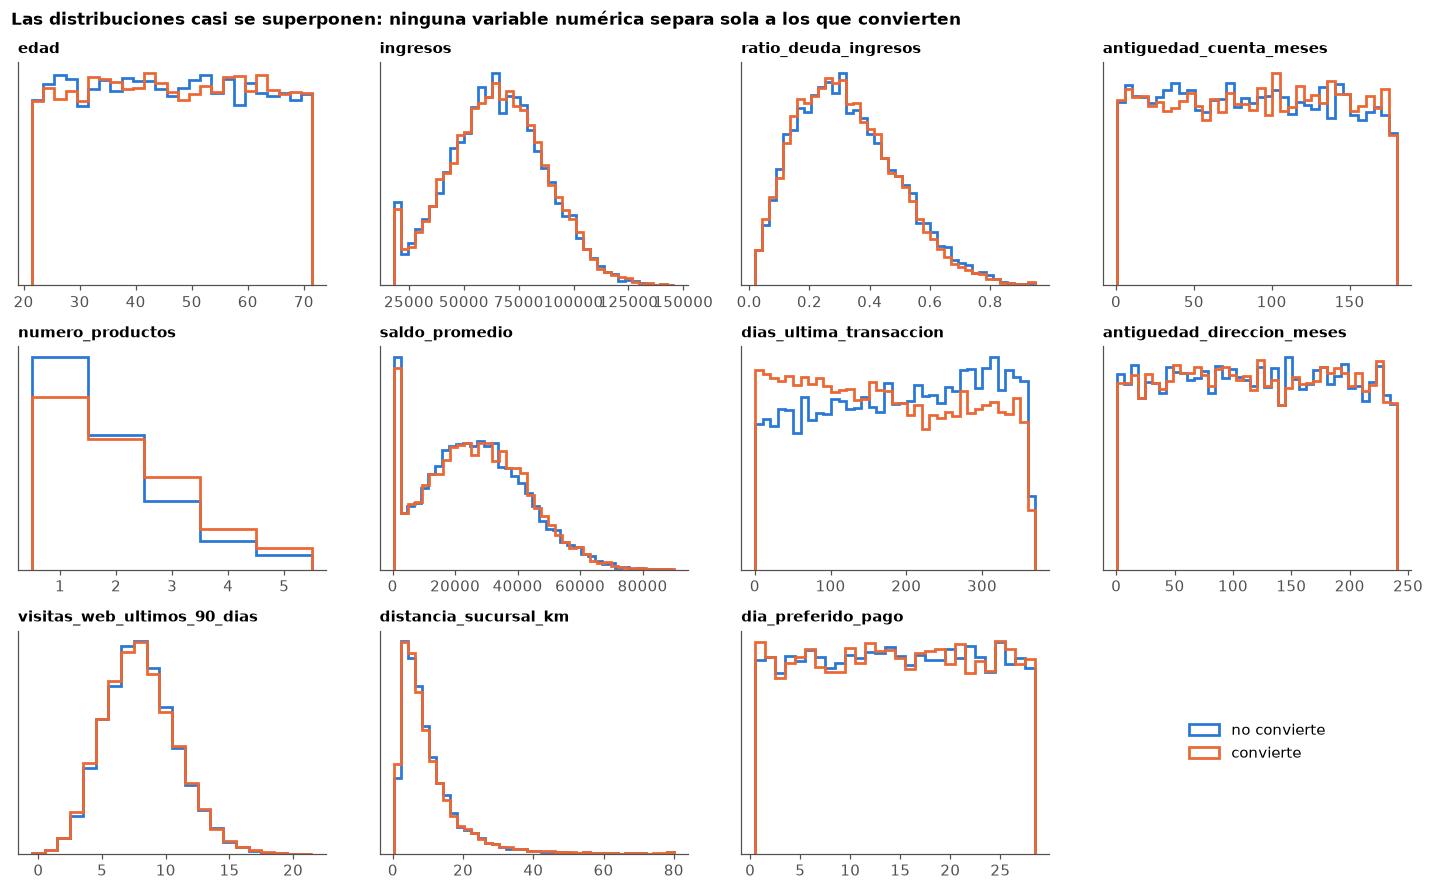

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8.2))
for ax, c in zip(axes.flat, NUMERICAS):
    if pd.api.types.is_integer_dtype(dev[c]):
        ancho = max(1, int(np.ceil((dev[c].max() - dev[c].min() + 1) / 40)))
        bins = np.arange(dev[c].min() - 0.5, dev[c].max() + ancho + 0.5, ancho)
    else:
        bins = 40
    for valor, color, nombre in ((0, AZUL, 'no convierte'), (1, NARANJA, 'convierte')):
        ax.hist(dev.loc[dev[TARGET] == valor, c], bins=bins, density=True, histtype='step', lw=1.8, color=color, label=nombre)
    ax.set_title(c, fontsize=9.5)
    ax.set_yticks([])
    ax.grid(False)
axes.flat[-1].axis('off')
axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), loc='center', fontsize=10)
fig.suptitle('Las distribuciones casi se superponen: ninguna variable numérica separa sola a los que convierten',
             x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout()
guardar(fig, '04_distribuciones_numericas_por_target')

**Lectura.** Las curvas de quienes convierten y quienes no casi se superponen en todas las variables. Solo se ven diferencias en número de productos (los que convierten tienen más) y en días desde la última transacción (los que convierten transaccionaron más recientemente). Es un problema de señal débil: el techo razonable de Gini es moderado, y conviene desconfiar de cualquier variable que prometa mucho más.

### 5.3 Tasa de conversión por decil de cada variable numérica

Es el análisis bivariante del documento (sección 3.6.2). Una variable útil y fácil de explicar muestra una tasa que sube o baja de forma monótona entre deciles. La línea discontinua es la tasa promedio.

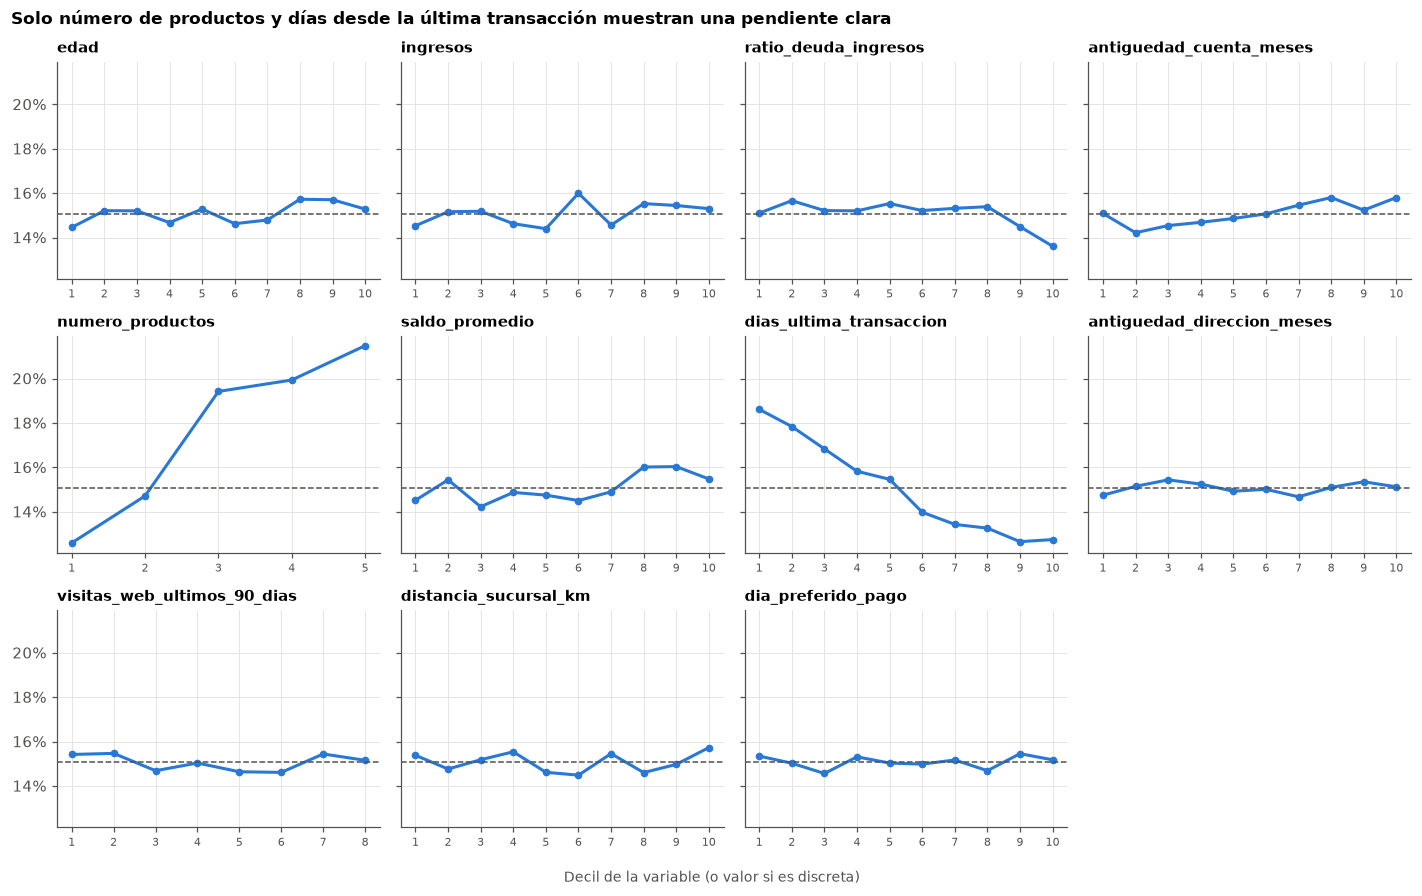

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8.2), sharey=True)
tasa_dev = dev[TARGET].mean()
for ax, c in zip(axes.flat, NUMERICAS):
    grupos = pd.qcut(dev[c], 10, duplicates='drop') if dev[c].nunique() > 10 else dev[c]
    t = dev.groupby(grupos, observed=True)[TARGET].agg(['mean', 'size'])
    ax.plot(np.arange(len(t)), t['mean'], color=AZUL, marker='o', ms=4)
    ax.axhline(tasa_dev, color=TINTA2, ls='--', lw=1)
    ax.set_title(c, fontsize=9.5)
    ax.set_xticks(np.arange(len(t)))
    ax.set_xticklabels([str(i + 1) if dev[c].nunique() > 10 else str(v) for i, v in enumerate(t.index)], fontsize=7)
    ax.yaxis.set_major_formatter(PCT)
axes.flat[-1].axis('off')
fig.suptitle('Solo número de productos y días desde la última transacción muestran una pendiente clara',
             x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.supxlabel('Decil de la variable (o valor si es discreta)', fontsize=9, color=TINTA2)
fig.tight_layout()
guardar(fig, '05_tasa_por_decil_numericas')

**Lectura.** La tasa sube de 13 por ciento con un producto a 21 por ciento con cinco, y baja de 19 por ciento en el decil de transacción más reciente a 13 por ciento en el más antiguo; ambas relaciones son monótonas y fáciles de explicar. El ratio de deuda actúa solo en el último decil, donde la tasa cae a 14 por ciento. Las demás variables oscilan alrededor del promedio sin patrón.

### 5.4 Tasa de conversión por categoría

Se muestra la tasa de cada categoría con su intervalo de confianza del 95 por ciento. Si los intervalos se cruzan con la línea promedio, la diferencia no es concluyente.

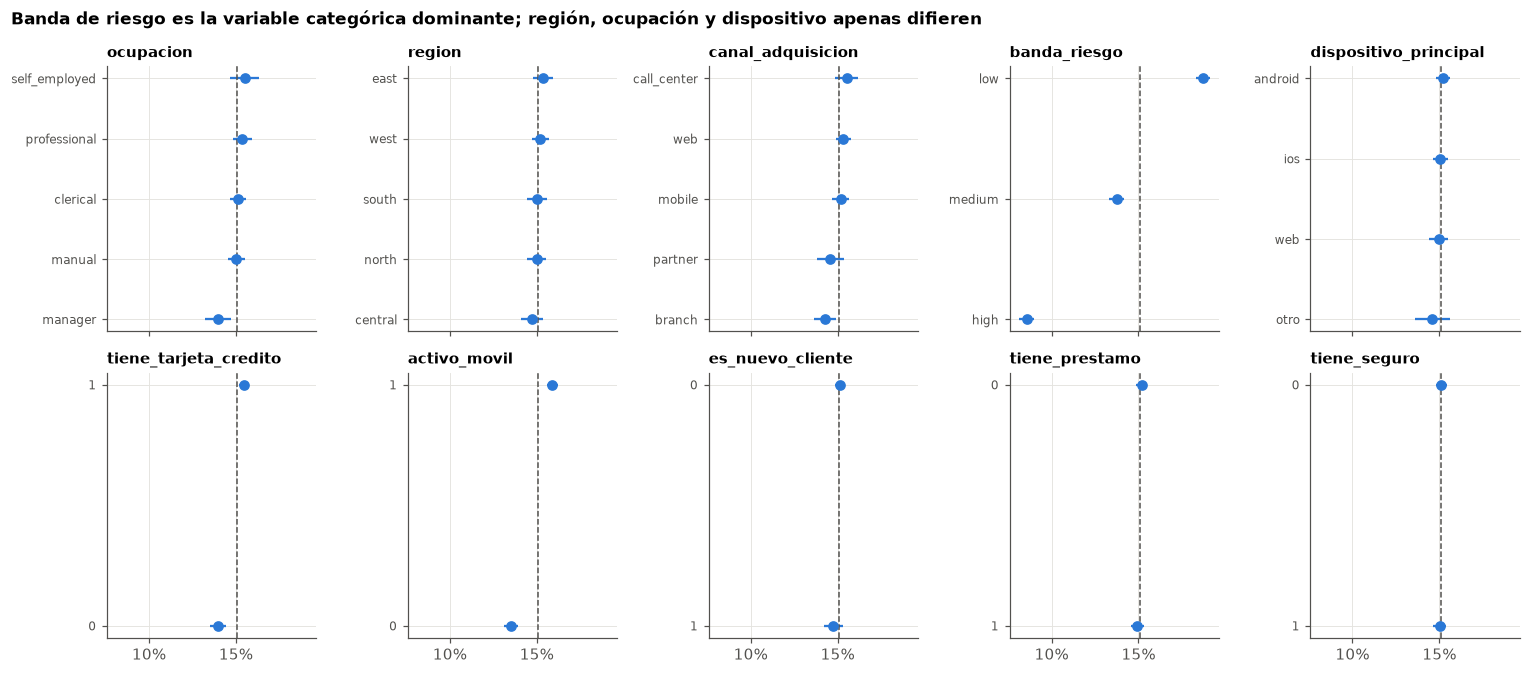

In [16]:
variables_cat = CATEGORICAS + BOOLEANAS
fig, axes = plt.subplots(2, 5, figsize=(14, 6.2), sharex=True)
for ax, c in zip(axes.flat, variables_cat):
    t = dev.groupby(c, observed=True)[TARGET].agg(['mean', 'size'])
    t['se'] = np.sqrt(t['mean'] * (1 - t['mean']) / t['size'])
    t = t.sort_values('mean')
    y = np.arange(len(t))
    ax.errorbar(t['mean'], y, xerr=1.96 * t['se'], fmt='o', color=AZUL, ms=6, lw=1.5, capsize=0)
    ax.axvline(tasa_dev, color=TINTA2, ls='--', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index.astype(str), fontsize=8)
    ax.set_title(c, fontsize=9.5)
    ax.xaxis.set_major_formatter(PCT)
fig.suptitle('Banda de riesgo es la variable categórica dominante; región, ocupación y dispositivo apenas difieren',
             x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout()
guardar(fig, '06_tasa_por_categoria')

**Lectura.** La banda de riesgo separa con claridad: riesgo bajo convierte cerca de 19 por ciento, medio 14 por ciento y alto 9 por ciento. Móvil activo y tenencia de tarjeta aportan algo de señal. En región, ocupación, dispositivo, préstamo, seguro y cliente nuevo los intervalos cruzan el promedio, así que su aporte individual no es concluyente.

### 5.5 Pruebas estadísticas y valor de información

Para cada variable se calcula:

* **Gini univariante**: capacidad de ordenar de la variable sola, con signo.
* **Valor de información (IV)** con agrupación óptima monótona de optbinning, el estándar de credit scoring. Umbrales habituales: menos de 0,02 sin poder, de 0,02 a 0,1 débil, de 0,1 a 0,3 medio.
* **Prueba de Mann Whitney** para numéricas, porque no supone normalidad, y **estadístico de Kolmogorov Smirnov** entre las dos distribuciones.
* **Prueba ji cuadrado y V de Cramér** para categóricas y booleanas, como medida de tamaño de efecto.

Con más de 50 mil filas casi todo resulta estadísticamente significativo, por eso se privilegian los tamaños de efecto (IV, Gini, V de Cramér) sobre el valor p.

In [17]:
filas = []
y_dev = dev[TARGET].astype(int)
for c in NUMERICAS + CATEGORICAS + BOOLEANAS + [SOSPECHOSA]:
    es_cat = c in CATEGORICAS
    ob = OptimalBinning(name=c, dtype='categorical' if es_cat else 'numerical', monotonic_trend=None if es_cat else 'auto_asc_desc')
    ob.fit(dev[c].astype(str).values if es_cat else dev[c].values, y_dev.values)
    iv = float(ob.binning_table.build().loc['Totals', 'IV'])
    if es_cat or c in BOOLEANAS:
        tabla = pd.crosstab(dev[c], y_dev)
        chi2, p, _, _ = stats.chi2_contingency(tabla)
        v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
        codificada = dev[c].map(dev.groupby(c, observed=True)[TARGET].mean()).astype(float)
        filas.append({'variable': c, 'tipo': 'categórica' if es_cat else 'booleana', 'gini_univariante': gini(y_dev, codificada),
                      'iv': iv, 'prueba': 'ji cuadrado', 'p_valor': p, 'efecto': v, 'medida_efecto': 'V de Cramér'})
    else:
        a, b = dev.loc[y_dev == 1, c], dev.loc[y_dev == 0, c]
        p = stats.mannwhitneyu(a, b).pvalue
        filas.append({'variable': c, 'tipo': 'numérica', 'gini_univariante': gini(y_dev, dev[c]), 'iv': iv,
                      'prueba': 'Mann Whitney', 'p_valor': p, 'efecto': stats.ks_2samp(a, b).statistic, 'medida_efecto': 'KS'})
pruebas = pd.DataFrame(filas).sort_values('iv', ascending=False).reset_index(drop=True)
pruebas['poder_iv'] = pd.cut(pruebas.iv, [-1, 0.02, 0.1, 0.3, 10], labels=['sin poder', 'débil', 'medio', 'fuerte'])
pruebas.to_csv(ART / '05_pruebas_estadisticas_iv.csv', index=False)
pruebas.round(4)

,variable,tipo,gini_univariante,iv,prueba,p_valor,efecto,medida_efecto,poder_iv
0,banda_riesgo,categórica,0.1612,0.1036,ji cuadrado,0.0000,0.1094,V de Cramér,medio
1,numero_productos,numérica,0.1187,0.0503,Mann Whitney,0.0000,0.0954,KS,débil
2,dias_ultima_transaccion,numérica,-0.0923,0.0278,Mann Whitney,0.0000,0.0747,KS,débil
3,dias_ultima_interaccion,numérica,-0.0655,0.0143,Mann Whitney,0.0000,0.0526,KS,sin poder
4,activo_movil,booleana,0.0420,0.0080,ji cuadrado,0.0000,0.0317,V de Cramér,sin poder
5,ratio_deuda_ingresos,numérica,-0.0160,0.0027,Mann Whitney,0.0050,0.0171,KS,sin poder
6,tiene_tarjeta_credito,booleana,0.0224,0.0027,ji cuadrado,0.0000,0.0183,V de Cramér,sin poder
7,saldo_promedio,numérica,0.0167,0.0025,Mann Whitney,0.0034,0.0218,KS,sin poder
8,antiguedad_cuenta_meses,numérica,0.0174,0.0015,Mann Whitney,0.0023,0.0176,KS,sin poder
9,canal_adquisicion,categórica,0.0170,0.0011,ji cuadrado,0.0247,0.0118,V de Cramér,sin poder


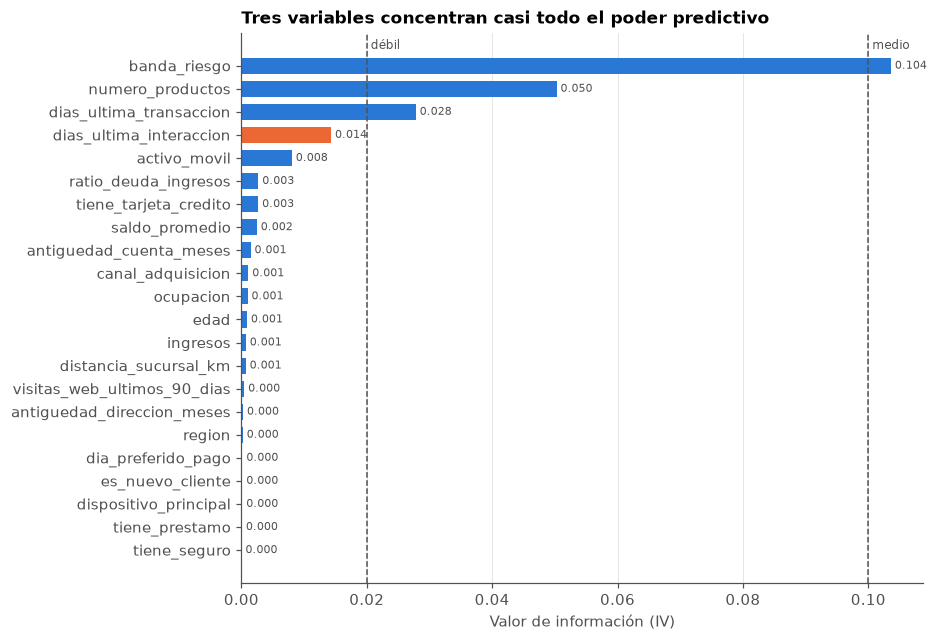

In [18]:
fig, ax = plt.subplots(figsize=(8, 6.5))
orden = pruebas.sort_values('iv')
colores = [NARANJA if v == SOSPECHOSA else AZUL for v in orden.variable]
ax.barh(orden.variable, orden.iv, color=colores, height=0.7)
for umbral, texto in ((0.02, 'débil'), (0.1, 'medio')):
    ax.axvline(umbral, color=TINTA2, ls='--', lw=1)
    ax.text(umbral, len(orden) - 0.4, f' {texto}', fontsize=8, color=TINTA2, va='bottom')
for i, v in enumerate(orden.iv):
    ax.text(v, i, f' {v:.3f}', va='center', fontsize=7.5, color=TINTA2)
ax.set_xlabel('Valor de información (IV)')
ax.grid(axis='y', visible=False)
ax.set_title('Tres variables concentran casi todo el poder predictivo')
guardar(fig, '07_ranking_valor_informacion')

**Lectura.** Solo la banda de riesgo alcanza poder medio (IV de 0,104); número de productos (0,050) y días desde la última transacción (0,028) son débiles, y el resto queda por debajo de 0,02. La variable sospechosa dias_ultima_interaccion, en naranja, aparece cuarta, pero su IV proviene de copiar a la transacción, como se demuestra en la sección de fuga. Los valores p confirman la lectura: región, dispositivo, préstamo y seguro ni siquiera son significativos con más de 80 mil filas.

### 5.6 Correlación entre variables

Se usa la correlación de Spearman porque captura relaciones monótonas no lineales y es robusta a colas largas como las de ingresos y saldo. El documento usa Pearson para el filtro de redundancia, que se aplica más adelante en el embudo de selección; aquí la matriz sirve para entender la estructura.

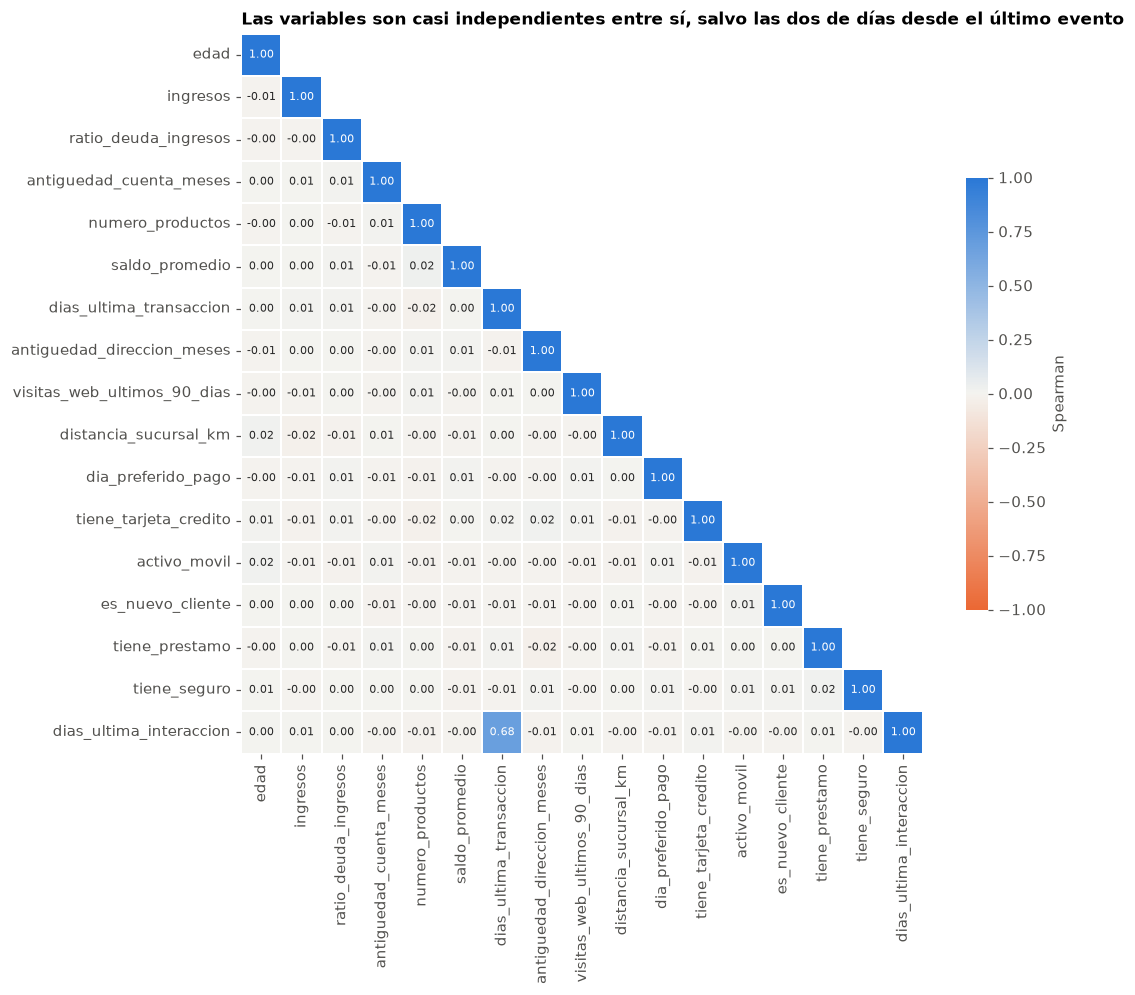

,level_0,level_1,spearman
90,dias_ultima_transaccion,dias_ultima_interaccion,0.684369
58,numero_productos,saldo_promedio,0.024725
97,antiguedad_direccion_meses,tiene_prestamo,-0.024451
11,edad,activo_movil,0.021719
64,numero_productos,tiene_tarjeta_credito,-0.021291


In [19]:
cols_corr = NUMERICAS + BOOLEANAS + [SOSPECHOSA]
corr = dev[cols_corr].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8.5))
mascara_sup = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara_sup, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'fontsize': 7}, linewidths=1, linecolor='white', cbar_kws={'shrink': 0.6, 'label': 'Spearman'}, ax=ax)
ax.grid(False)
ax.set_title('Las variables son casi independientes entre sí, salvo las dos de días desde el último evento')
guardar(fig, '08_correlacion_spearman')
pares = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack().rename('spearman').reset_index()
pares.reindex(pares.spearman.abs().sort_values(ascending=False).index).head(5)

**Lectura.** Las variables son prácticamente independientes: ninguna correlación supera 0,03 en valor absoluto, salvo la de dias_ultima_transaccion con dias_ultima_interaccion (0,68). Una correlación tan alta entre dos variables que deberían medir eventos distintos es la primera pista de que una copia a la otra. No hay multicolinealidad que afecte a los modelos lineales.

### 5.7 Estabilidad temporal por variable

Es el análisis temporal a nivel variable del documento (sección 3.5.2). Se calcula la desviación porcentual de la media mensual de cada variable respecto de su media en desarrollo, y el índice de estabilidad poblacional (PSI) de desarrollo contra OOT y contra diciembre. Umbrales usuales del PSI: menos de 0,1 estable, de 0,1 a 0,25 vigilancia, más de 0,25 cambio relevante.

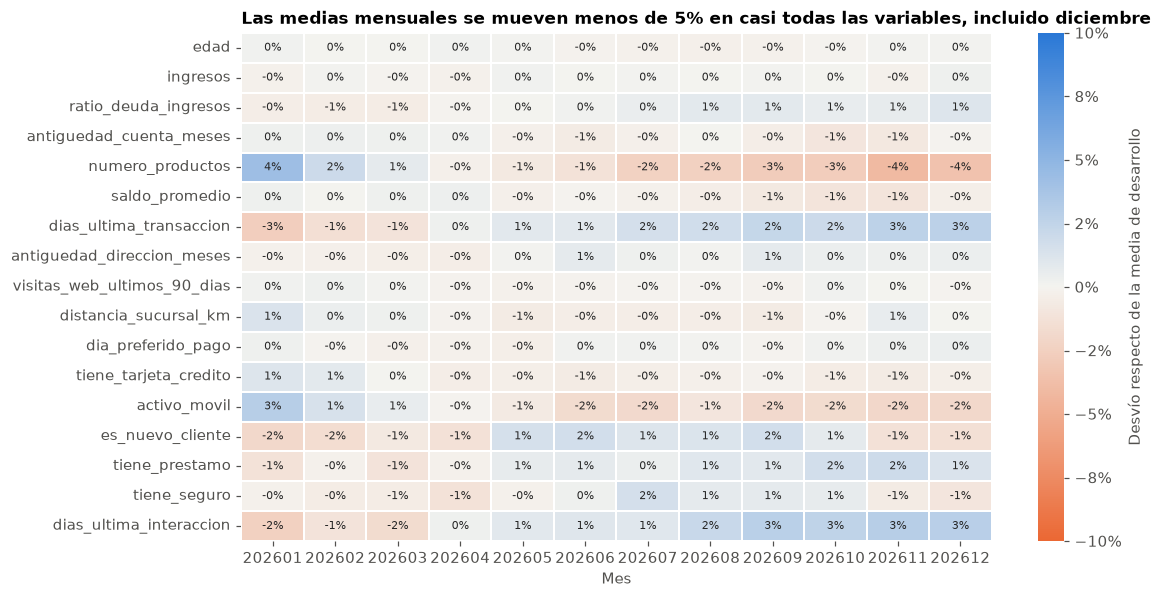

In [20]:
media_dev = panel.loc[m_dev, NUMERICAS + BOOLEANAS + [SOSPECHOSA]].mean()
desvio = (panel.groupby('mes')[NUMERICAS + BOOLEANAS + [SOSPECHOSA]].mean() / media_dev - 1)
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(desvio.T, cmap=CMAP_DIV, center=0, vmin=-0.1, vmax=0.1, annot=True, fmt='.0%', annot_kws={'fontsize': 7},
            linewidths=1, linecolor='white', cbar_kws={'label': 'Desvío respecto de la media de desarrollo', 'format': PCT}, ax=ax)
ax.grid(False)
ax.set_xlabel('Mes')
ax.set_title('Las medias mensuales se mueven menos de 5% en casi todas las variables, incluido diciembre')
guardar(fig, '09_estabilidad_medias_mensuales')

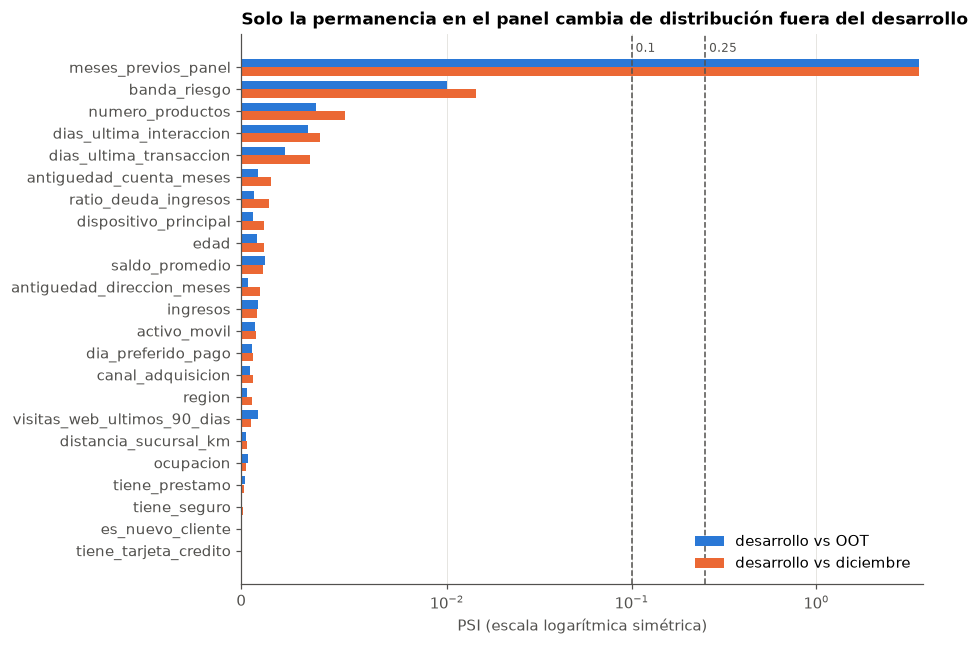

,variable,psi_dev_vs_oot,psi_dev_vs_diciembre
0,meses_previos_panel,3.6103,3.6087
1,banda_riesgo,0.0100,0.0144
2,numero_productos,0.0037,0.0051
3,dias_ultima_interaccion,0.0033,0.0038
4,dias_ultima_transaccion,0.0021,0.0033
5,antiguedad_cuenta_meses,0.0008,0.0014
6,ratio_deuda_ingresos,0.0006,0.0013
7,dispositivo_principal,0.0006,0.0011
8,edad,0.0008,0.0011
9,saldo_promedio,0.0012,0.0010


In [21]:
filas = []
for c in BASE + [SOSPECHOSA, 'meses_previos_panel']:
    ref = panel.loc[m_dev, c]
    conv_num = (lambda s: s.cat.codes) if c in CATEGORICAS else (lambda s: s)
    filas.append({'variable': c, 'psi_dev_vs_oot': psi(conv_num(ref), conv_num(panel.loc[m_oot, c])),
                  'psi_dev_vs_diciembre': psi(conv_num(ref), conv_num(panel.loc[m_dic, c]))})
tabla_psi = pd.DataFrame(filas).sort_values('psi_dev_vs_diciembre', ascending=False).reset_index(drop=True)
tabla_psi.to_csv(ART / '05_psi_variables.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
orden = tabla_psi.sort_values('psi_dev_vs_diciembre')
y = np.arange(len(orden))
ax.barh(y + 0.2, orden.psi_dev_vs_oot, height=0.38, color=AZUL, label='desarrollo vs OOT')
ax.barh(y - 0.2, orden.psi_dev_vs_diciembre, height=0.38, color=NARANJA, label='desarrollo vs diciembre')
ax.set_yticks(y)
ax.set_yticklabels(orden.variable)
ax.set_xscale('symlog', linthresh=0.01)
for umbral in (0.1, 0.25):
    ax.axvline(umbral, color=TINTA2, ls='--', lw=1)
    ax.text(umbral, len(orden) - 0.3, f' {umbral}', fontsize=8, color=TINTA2)
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
ax.set_xlabel('PSI (escala logarítmica simétrica)')
ax.set_title('Solo la permanencia en el panel cambia de distribución fuera del desarrollo')
guardar(fig, '10_psi_por_variable')
tabla_psi.round(4)

**Lectura.** Todas las variables originales tienen un PSI menor que 0,02 contra OOT y contra diciembre. Hay una deriva suave y explicable: número de productos pasa de 4 por ciento sobre su media en enero a 4 por ciento debajo en diciembre, y móvil activo baja de forma parecida, porque los clientes más vinculados convierten y salen del panel. La única variable inestable es meses_previos_panel, con un PSI de 3,6, por la censura de enero. dias_ultima_interaccion parece estable con este control marginal y, aun así, es la variable más problemática, como se verá en la sección de fuga.

### 5.8 Interacciones entre variables

Los modelos de árboles capturan interacciones automáticamente, pero conviene verlas para explicarlas al negocio y para decidir si una regresión logística necesita variables cruzadas.

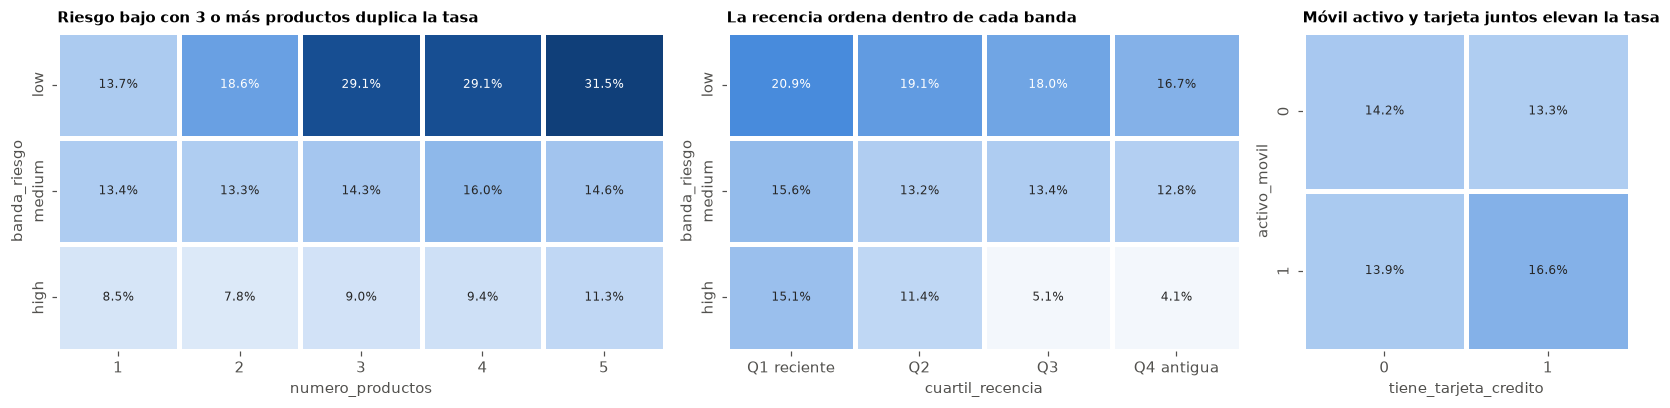

In [22]:
dev_int = dev.assign(cuartil_recencia=pd.qcut(dev.dias_ultima_transaccion, 4, labels=['Q1 reciente', 'Q2', 'Q3', 'Q4 antigua']))
tablas = [
    ('banda_riesgo', 'numero_productos', 'Riesgo bajo con 3 o más productos duplica la tasa'),
    ('banda_riesgo', 'cuartil_recencia', 'La recencia ordena dentro de cada banda'),
    ('activo_movil', 'tiene_tarjeta_credito', 'Móvil activo y tarjeta juntos elevan la tasa'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1.3, 1.1, 0.7]})
for ax, (f, c, titulo) in zip(axes, tablas):
    t = dev_int.pivot_table(index=f, columns=c, values=TARGET, aggfunc='mean', observed=True)
    if f == 'banda_riesgo':
        t = t.loc[['low', 'medium', 'high']]
    sns.heatmap(t, cmap=CMAP_SEC, vmin=0.05, vmax=0.32, annot=True, fmt='.1%', annot_kws={'fontsize': 8},
                linewidths=2, linecolor='white', cbar=False, ax=ax)
    ax.grid(False)
    ax.set_title(titulo, fontsize=10)
fig.tight_layout()
guardar(fig, '11_interacciones_tasa')

**Lectura.** Las interacciones son fuertes y tienen lectura de negocio. En riesgo bajo, pasar de uno a tres o más productos lleva la tasa de 14 a cerca de 30 por ciento, mientras que en riesgo medio y alto la vinculación casi no cambia nada. La recencia ordena en las tres bandas, sobre todo en riesgo alto (de 15 a 4 por ciento). Móvil activo solo eleva la tasa cuando el cliente también tiene tarjeta (16,6 por ciento frente a cerca de 14). Estas interacciones favorecen a los modelos de árboles y, en la logística, justifican variables cruzadas explícitas.

## 6. Pruebas de fuga de datos

Esta es la sección más importante del notebook. Un modelo con fuga muestra métricas espectaculares en desarrollo y fracasa en producción, y en una competencia eso significa una posición alta en la tabla pública y una caída en la privada. Se ejecutan siete pruebas, cada una con una hipótesis concreta de cómo podría filtrarse información:

1. Auditoría univariante: ninguna variable debe ordenar sospechosamente bien por sí sola.
2. Variables construidas con información futura: se demuestra cuánto inflan el Gini y por qué deben excluirse.
3. Esquema de validación: validación aleatoria, agrupada por cliente y temporal.
4. Deriva conjunta de dias_ultima_interaccion.
5. Validación adversarial entre desarrollo y diciembre.
6. Prueba de viaje en el tiempo de las variables de historial.
7. Ajuste de transformaciones solo con entrenamiento.

Se usa un LightGBM de referencia con parámetros conservadores para todas las pruebas, de modo que las diferencias se deban a los datos y no al modelo.

In [23]:
PARAMS_REF = dict(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=200, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, n_jobs=8, random_state=SEMILLA)

def ajustar_lgb(columnas, mascara, params=PARAMS_REF, datos=None):
    datos = panel if datos is None else datos
    modelo = lgb.LGBMClassifier(**params)
    modelo.fit(datos.loc[mascara, columnas], datos.loc[mascara, TARGET].astype(int))
    return modelo

def predecir(modelo, columnas, mascara, datos=None):
    datos = panel if datos is None else datos
    return modelo.predict_proba(datos.loc[mascara, columnas])[:, 1]

def gini_en(modelo, columnas, mascara, datos=None):
    datos = panel if datos is None else datos
    return gini(datos.loc[mascara, TARGET].astype(int), predecir(modelo, columnas, mascara, datos))

registro_fuga = []

### 6.1 Auditoría univariante

Si una variable aislada tiene un Gini absoluto mayor que 0,4 (AUC mayor que 0,7) en un problema de propensión, lo más probable es que contenga el resultado. También se incluyen los identificadores para comprobar que no codifican el orden de llegada o el target.

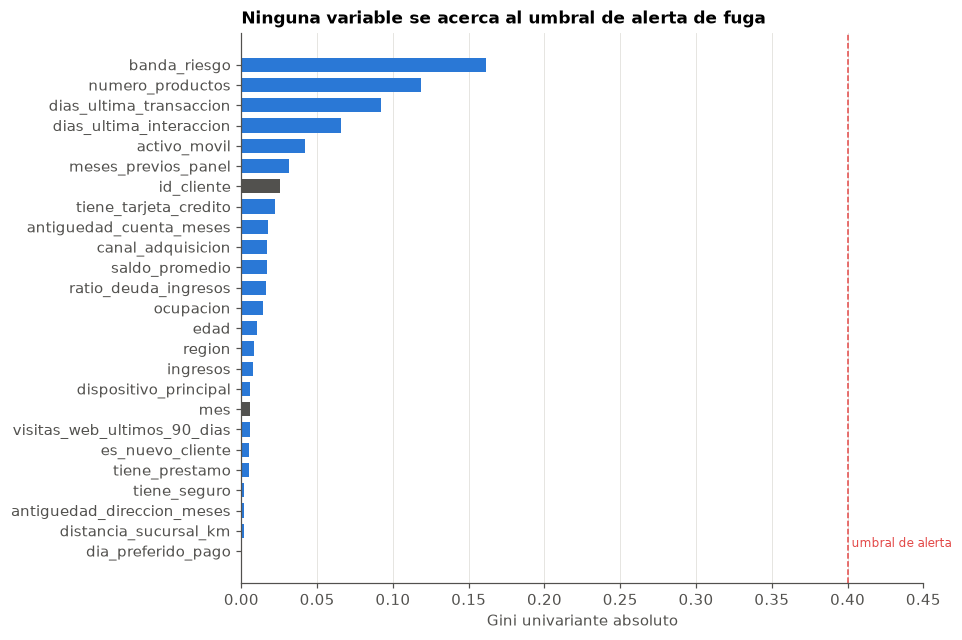

,variable,gini_univariante,gini_absoluto,alerta_fuga
0,banda_riesgo,0.1612,0.1612,False
1,numero_productos,0.1187,0.1187,False
2,dias_ultima_transaccion,-0.0923,0.0923,False
3,dias_ultima_interaccion,-0.0655,0.0655,False
4,activo_movil,0.0420,0.0420,False
5,meses_previos_panel,-0.0315,0.0315,False
6,id_cliente,0.0252,0.0252,False
7,tiene_tarjeta_credito,0.0224,0.0224,False


In [24]:
filas = []
for c in ['id_cliente', 'mes'] + BASE + [SOSPECHOSA, 'meses_previos_panel']:
    v = dev[c].cat.codes if c in CATEGORICAS else dev[c]
    if c in CATEGORICAS:
        v = dev[c].map(dev.groupby(c, observed=True)[TARGET].mean()).astype(float)
    filas.append({'variable': c, 'gini_univariante': gini(y_dev, v)})
auditoria = pd.DataFrame(filas)
auditoria['gini_absoluto'] = auditoria.gini_univariante.abs()
auditoria['alerta_fuga'] = auditoria.gini_absoluto > 0.4
auditoria = auditoria.sort_values('gini_absoluto', ascending=False).reset_index(drop=True)
auditoria.to_csv(ART / '06_auditoria_univariante.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
orden = auditoria.sort_values('gini_absoluto')
colores = [TINTA2 if v in ('id_cliente', 'mes') else AZUL for v in orden.variable]
ax.barh(orden.variable, orden.gini_absoluto, color=colores, height=0.7)
ax.axvline(0.4, color=ROJO, ls='--', lw=1)
ax.text(0.4, 0.2, ' umbral de alerta', color=ROJO, fontsize=8)
ax.set_xlim(0, 0.45)
ax.set_xlabel('Gini univariante absoluto')
ax.grid(axis='y', visible=False)
ax.set_title('Ninguna variable se acerca al umbral de alerta de fuga')
guardar(fig, '12_auditoria_univariante_fuga')
registro_fuga.append({'prueba': '1. Auditoría univariante', 'resultado': f"Gini máximo {auditoria.gini_absoluto.max():.3f} ({auditoria.variable[0]})",
                      'decision': 'Sin alertas; id_cliente y mes se excluyen por ser identificadores'})
auditoria.round(4).head(8)

**Lectura.** El Gini univariante máximo es 0,161 (banda de riesgo), muy lejos del umbral de alerta de 0,4. Los identificadores id_cliente (0,025) y mes tienen una señal casi nula y se excluyen por definición: un identificador no generaliza a clientes o meses nuevos.

### 6.2 Variables construidas con información futura

En un panel donde el cliente desaparece al convertir, es muy fácil construir sin querer variables que miran el futuro. Se simulan tres variables tentadoras que un analista podría crear agrupando por cliente sobre todo el train:

* **es_ultima_aparicion**: si el mes es el último en que aparece el cliente. Toda conversión es la última aparición del cliente por la regla del panel.
* **apariciones_totales**: número total de meses en que aparece el cliente, contando meses futuros.
* **meses_restantes**: meses que faltan hasta su última aparición.

Ninguna existe al momento de predecir diciembre, porque requieren saber si el cliente seguirá apareciendo. Se mide el Gini en OOT que obtendría un modelo con cada una.

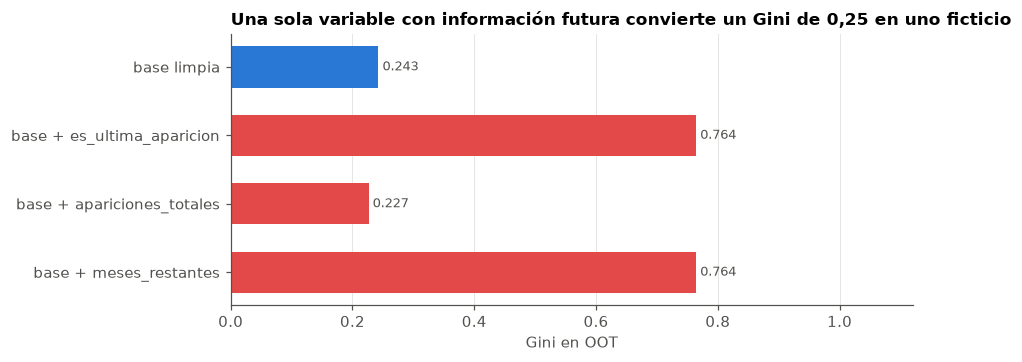

,variante,gini_oot
0,base limpia,0.2427
1,base + es_ultima_aparicion,0.7645
2,base + apariciones_totales,0.2266
3,base + meses_restantes,0.7645


In [25]:
fuga = panel[es_train].copy()
ultimo_mes = fuga.groupby('id_cliente').mes.transform('max')
fuga['es_ultima_aparicion'] = (fuga.mes == ultimo_mes).astype(int)
fuga['apariciones_totales'] = fuga.groupby('id_cliente').mes.transform('size')
fuga['meses_restantes'] = fuga.groupby('id_cliente').cumcount(ascending=False)
mtr, moot = m_trn[es_train], m_oot[es_train]
filas = []
for nombre, extra in (('base limpia', []), ('base + es_ultima_aparicion', ['es_ultima_aparicion']),
                      ('base + apariciones_totales', ['apariciones_totales']), ('base + meses_restantes', ['meses_restantes'])):
    m = ajustar_lgb(BASE + extra, mtr, datos=fuga)
    filas.append({'variante': nombre, 'gini_oot': gini_en(m, BASE + extra, moot, datos=fuga)})
tabla_futuro = pd.DataFrame(filas)
tabla_futuro.to_csv(ART / '06_variables_futuro.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
colores = [AZUL] + [ROJO] * 3
ax.barh(tabla_futuro.variante[::-1], tabla_futuro.gini_oot[::-1], color=colores[::-1], height=0.6)
for i, v in enumerate(tabla_futuro.gini_oot[::-1]):
    ax.text(v, i, f' {v:.3f}', va='center', fontsize=8.5, color=TINTA2)
ax.set_xlim(0, 1.12)
ax.set_xlabel('Gini en OOT')
ax.grid(axis='y', visible=False)
ax.set_title('Una sola variable con información futura convierte un Gini de 0,25 en uno ficticio')
guardar(fig, '13_fuga_variables_futuro')
registro_fuga.append({'prueba': '2. Variables con información futura',
                      'resultado': f"Gini OOT pasa de {tabla_futuro.gini_oot[0]:.3f} a {tabla_futuro.gini_oot.max():.3f}",
                      'decision': 'Prohibidas: solo se usan variables calculadas con meses anteriores'})
tabla_futuro.round(4)

**Lectura.** Basta una variable construida con el futuro para inflar el Gini OOT de 0,243 a 0,764. es_ultima_aparicion y meses_restantes son la misma trampa: por la regla del panel, toda conversión es la última aparición del cliente. apariciones_totales incluso baja el Gini (0,227) porque su relación con el target cambia entre desarrollo y OOT; es la otra cara de la fuga, que además de inflar desestabiliza. En diciembre ninguna de las tres puede calcularse sin conocer el futuro, así que el modelo solo usa variables disponibles al inicio del mes.

### 6.3 Esquema de validación

Las variables de cada cliente son idénticas en todos sus meses. Esto crea dos riesgos con una validación cruzada aleatoria: el modelo puede memorizar clientes, y la estimación deja de representar lo que pasará en diciembre. Se comparan tres esquemas sobre desarrollo con dos modelos, uno conservador y uno muy flexible que memoriza con facilidad, y se contrastan con el Gini real en OOT.

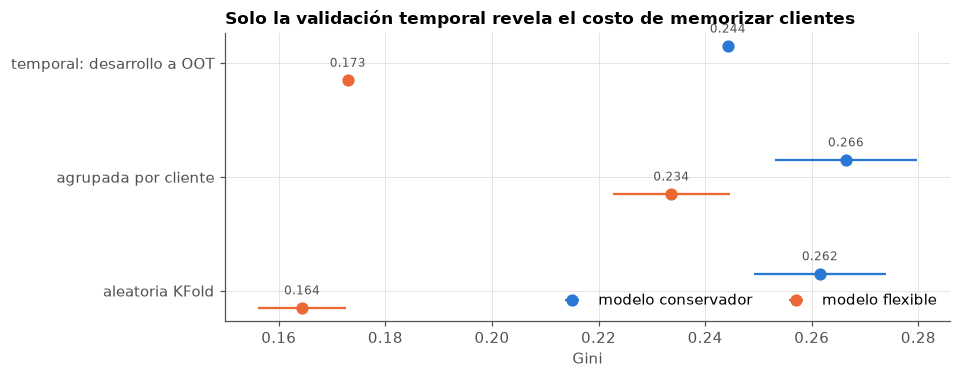

,modelo,esquema,gini_estimado,desvio
0,conservador,aleatoria KFold,0.2615,0.0123
1,conservador,agrupada por cliente,0.2664,0.0133
2,conservador,temporal: desarrollo a OOT,0.2443,NaN
3,flexible,aleatoria KFold,0.1644,0.0083
4,flexible,agrupada por cliente,0.2337,0.0109
5,flexible,temporal: desarrollo a OOT,0.1730,NaN


In [26]:
PARAMS_FLEX = dict(PARAMS_REF, num_leaves=127, min_child_samples=5, n_estimators=800, learning_rate=0.05)
Xd, yd, gd = dev[BASE], dev[TARGET].astype(int), dev.id_cliente
filas = []
for nombre_modelo, params in (('conservador', PARAMS_REF), ('flexible', PARAMS_FLEX)):
    for esquema, cv in (('aleatoria KFold', KFold(5, shuffle=True, random_state=SEMILLA)), ('agrupada por cliente', GroupKFold(5))):
        ginis = []
        for i_a, i_b in cv.split(Xd, yd, gd):
            m = lgb.LGBMClassifier(**params).fit(Xd.iloc[i_a], yd.iloc[i_a])
            ginis.append(gini(yd.iloc[i_b], m.predict_proba(Xd.iloc[i_b])[:, 1]))
        filas.append({'modelo': nombre_modelo, 'esquema': esquema, 'gini_estimado': np.mean(ginis), 'desvio': np.std(ginis)})
    m = ajustar_lgb(BASE, m_dev, params)
    filas.append({'modelo': nombre_modelo, 'esquema': 'temporal: desarrollo a OOT', 'gini_estimado': gini_en(m, BASE, m_oot), 'desvio': np.nan})
tabla_cv = pd.DataFrame(filas)
tabla_cv.to_csv(ART / '06_esquemas_validacion.csv', index=False)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
esquemas = tabla_cv.esquema.unique()
for j, (nombre_modelo, color) in enumerate((('conservador', AZUL), ('flexible', NARANJA))):
    t = tabla_cv[tabla_cv.modelo == nombre_modelo].set_index('esquema').loc[esquemas]
    yy = np.arange(len(esquemas)) + (0.15 if j == 0 else -0.15)
    ax.errorbar(t.gini_estimado, yy, xerr=t.desvio.fillna(0), fmt='o', color=color, ms=7, lw=1.5, label=f'modelo {nombre_modelo}')
    for v, yv in zip(t.gini_estimado, yy):
        ax.text(v, yv + 0.12, f'{v:.3f}', ha='center', fontsize=8, color=TINTA2)
ax.set_yticks(np.arange(len(esquemas)))
ax.set_yticklabels(esquemas)
ax.set_xlabel('Gini')
ax.legend(loc='lower right', ncol=2)
ax.set_title('Solo la validación temporal revela el costo de memorizar clientes')
guardar(fig, '14_esquemas_validacion')
registro_fuga.append({'prueba': '3. Esquema de validación', 'resultado': 'La validación aleatoria se desvía del Gini OOT con el modelo flexible',
                      'decision': 'Partición agrupada por cliente, validación temporal para el ajuste y OOT como juez'})
tabla_cv.round(4)

**Lectura.** Con el modelo conservador, las validaciones aleatoria (0,262) y agrupada por cliente (0,266) sobreestiman el Gini temporal (0,244) en unas dos centésimas. Con el modelo flexible el resultado es más revelador: la validación agrupada promete 0,234 y en OOT se obtiene 0,173. En un mes futuro, 8 de cada 10 clientes ya fueron vistos, siempre con objetivo 0, y un modelo que memoriza los hunde en el ranking aunque vayan a convertir. Decisiones: ajuste con validación temporal, hojas grandes que impiden memorizar (Optuna termina eligiendo al menos 510 filas por hoja) y la OOT como juez final.

### 6.4 Deriva conjunta de dias_ultima_interaccion

En la exploración se detectó que dias_ultima_interaccion es la única variable que cambia dentro de un mismo cliente. Se analiza con cuidado porque su comportamiento no coincide entre el entrenamiento y diciembre.

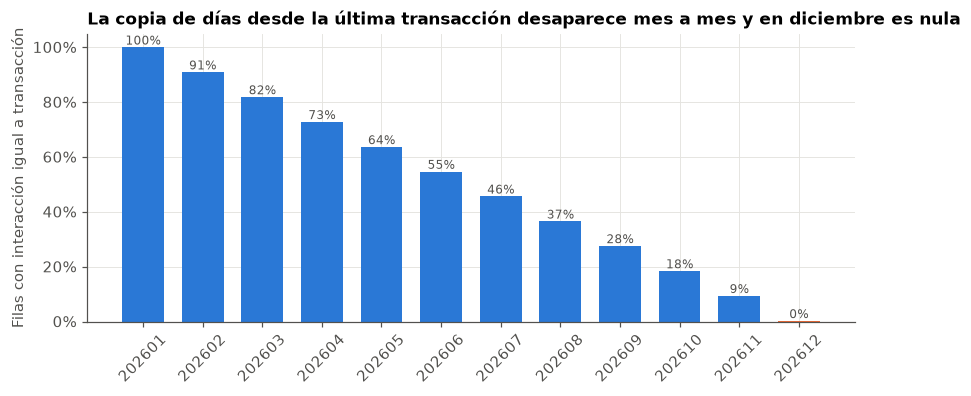

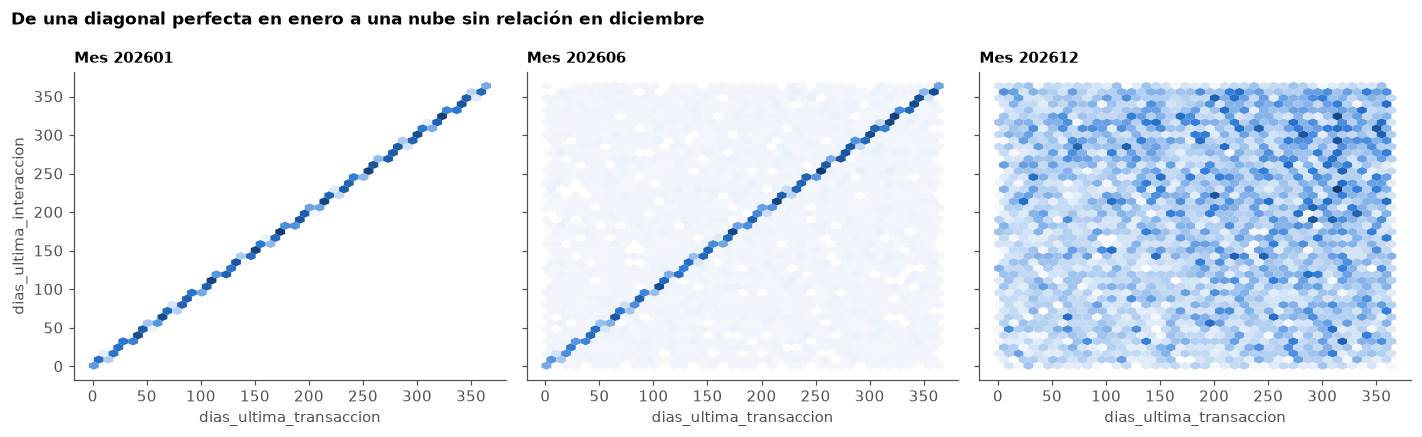

,gini_interaccion,gini_transaccion,filas
interacción igual a transacción,0.0931,0.0931,54931
interacción distinta,0.0053,0.0904,25369


In [27]:
panel['interaccion_igual_transaccion'] = (panel[SOSPECHOSA] == panel.dias_ultima_transaccion).astype(int)
igualdad = panel.groupby('mes').interaccion_igual_transaccion.mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x[:11], igualdad.values[:11], color=AZUL, width=0.7)
ax.bar(11, igualdad.values[11], color=NARANJA, width=0.7)
for i, v in enumerate(igualdad.values):
    ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=8, color=TINTA2)
ax.set_xticks(x)
ax.set_xticklabels(igualdad.index.astype(str), rotation=45)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel('Filas con interacción igual a transacción')
ax.set_title('La copia de días desde la última transacción desaparece mes a mes y en diciembre es nula')
guardar(fig, '15_igualdad_interaccion_transaccion')

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, mes in zip(axes, (202601, 202606, 202612)):
    d = panel[panel.mes == mes]
    ax.hexbin(d.dias_ultima_transaccion, d[SOSPECHOSA], gridsize=40, cmap=CMAP_SEC, mincnt=1, linewidths=0)
    ax.set_title(f'Mes {mes}', fontsize=10)
    ax.set_xlabel('dias_ultima_transaccion')
    ax.grid(False)
axes[0].set_ylabel(SOSPECHOSA)
fig.suptitle('De una diagonal perfecta en enero a una nube sin relación en diciembre', x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout()
guardar(fig, '16_dispersion_interaccion_vs_transaccion')

d_cambio = dev[dev[SOSPECHOSA] != dev.dias_ultima_transaccion]
d_igual = dev[dev[SOSPECHOSA] == dev.dias_ultima_transaccion]
pd.DataFrame({
    'gini_interaccion': [gini(d_igual[TARGET], -d_igual[SOSPECHOSA]), gini(d_cambio[TARGET], -d_cambio[SOSPECHOSA])],
    'gini_transaccion': [gini(d_igual[TARGET], -d_igual.dias_ultima_transaccion), gini(d_cambio[TARGET], -d_cambio.dias_ultima_transaccion)],
    'filas': [len(d_igual), len(d_cambio)]}, index=['interacción igual a transacción', 'interacción distinta']).round(4)

**Lectura.** En enero dias_ultima_interaccion es idéntica a dias_ultima_transaccion en el 100 por ciento de las filas; la igualdad cae unos 9 puntos por mes hasta el 9 por ciento en noviembre y prácticamente 0 en diciembre, lo esperable por azar (1 en 364). Las dispersiones lo confirman: diagonal perfecta en enero, mezcla en junio y nube sin estructura en diciembre. Cuando la variable conserva la copia tiene el mismo Gini que la transacción (0,093); cuando fue reemplazada, su Gini es 0,005.

La variable parece un dato que se copia de dias_ultima_transaccion y que, mes a mes, una fracción creciente de clientes ve reemplazado por un valor sin relación con el target. Cuando difiere de la transacción su Gini es prácticamente cero. Su distribución marginal es la misma en todos los meses (PSI cercano a cero), por lo que un control de estabilidad clásico no la detecta: la deriva es conjunta, no marginal. Se confirma con dos pruebas:

* **Validación adversarial**: un clasificador intenta distinguir filas de OOT de filas de diciembre. Con la variable marginal sola no debería poder; con la relación entre las dos variables sí.
* **Prueba de estrés**: se entrena un modelo con la variable y se evalúa en OOT tal como viene, y en una OOT donde la variable se reemplaza por una permutación aleatoria, que es exactamente la situación de diciembre.

In [28]:
adv = pd.concat([panel.loc[m_oot].assign(es_dic=0), panel.loc[m_dic].assign(es_dic=1)])
adv['diferencia_trx_interaccion'] = adv.dias_ultima_transaccion - adv[SOSPECHOSA]
filas = []
for nombre, cols in (('solo dias_ultima_interaccion', [SOSPECHOSA]),
                     ('transacción e interacción', ['dias_ultima_transaccion', SOSPECHOSA]),
                     ('transacción, interacción y su diferencia', ['dias_ultima_transaccion', SOSPECHOSA, 'diferencia_trx_interaccion'])):
    aucs = []
    for i_a, i_b in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(adv, adv.es_dic):
        m = lgb.LGBMClassifier(n_estimators=200, num_leaves=15, verbose=-1, n_jobs=8).fit(adv.iloc[i_a][cols], adv.iloc[i_a].es_dic)
        aucs.append(roc_auc_score(adv.iloc[i_b].es_dic, m.predict_proba(adv.iloc[i_b][cols])[:, 1]))
    filas.append({'prueba': f'adversarial OOT vs diciembre: {nombre}', 'valor': np.mean(aucs), 'metrica': 'AUC adversarial'})

m_con = ajustar_lgb(BASE + [SOSPECHOSA], m_trn)
m_sin = ajustar_lgb(BASE, m_trn)
oot_estres = panel.copy()
oot_estres.loc[m_oot, SOSPECHOSA] = rng.permutation(oot_estres.loc[m_oot, SOSPECHOSA].values)
filas += [
    {'prueba': 'modelo sin la variable, OOT original', 'valor': gini_en(m_sin, BASE, m_oot), 'metrica': 'Gini'},
    {'prueba': 'modelo con la variable, OOT original', 'valor': gini_en(m_con, BASE + [SOSPECHOSA], m_oot), 'metrica': 'Gini'},
    {'prueba': 'modelo con la variable, OOT con la variable permutada (como diciembre)', 'valor': gini_en(m_con, BASE + [SOSPECHOSA], m_oot, datos=oot_estres), 'metrica': 'Gini'},
]
estres = pd.DataFrame(filas)
estres.to_csv(ART / '06_deriva_interaccion.csv', index=False)
registro_fuga.append({'prueba': '4. Deriva conjunta de dias_ultima_interaccion',
                      'resultado': f"AUC adversarial con la relación {estres.valor[2]:.3f}; Gini con variable permutada {estres.valor[5]:.3f} frente a {estres.valor[3]:.3f} sin ella",
                      'decision': 'Se excluye dias_ultima_interaccion'})
estres.round(4)

,prueba,valor,metrica
0,adversarial OOT vs diciembre: solo dias_ultima...,0.4635,AUC adversarial
1,adversarial OOT vs diciembre: transacción e in...,0.5705,AUC adversarial
2,"adversarial OOT vs diciembre: transacción, int...",0.5777,AUC adversarial
3,"modelo sin la variable, OOT original",0.2427,Gini
4,"modelo con la variable, OOT original",0.2450,Gini
5,"modelo con la variable, OOT con la variable pe...",0.2436,Gini


**Lectura.** La validación adversarial no distingue OOT de diciembre con la variable sola (AUC de 0,46), pero sí cuando ve su relación con la transacción (AUC de 0,57 a 0,58): la deriva es conjunta. La prueba de estrés muestra que el modelo con la variable gana apenas 0,002 de Gini en la OOT original (0,2450 frente a 0,2427), y que esa ganancia se esfuma al permutarla, como ocurrirá en diciembre (0,2436). La variable no aporta información propia, solo una copia que se degrada con el tiempo, y en el mejor caso agrega ruido. Se excluye.

### 6.5 Validación adversarial entre desarrollo y diciembre

Con las variables candidatas, ya sin dias_ultima_interaccion, un clasificador no debería distinguir filas de desarrollo de filas de diciembre. Un AUC cercano a 0,5 indica que diciembre se parece al desarrollo y que el modelo se aplicará en territorio conocido.

In [29]:
adv2 = pd.concat([panel.loc[m_dev].assign(es_dic=0), panel.loc[m_dic].assign(es_dic=1)])
filas = []
for nombre, cols in (('variables base', BASE), ('variables base e interacción', BASE + [SOSPECHOSA, 'interaccion_igual_transaccion']),
                     ('variables base e historial', BASE + ['meses_previos_panel'])):
    aucs = []
    for i_a, i_b in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(adv2, adv2.es_dic):
        m = lgb.LGBMClassifier(n_estimators=200, num_leaves=15, verbose=-1, n_jobs=8).fit(adv2.iloc[i_a][cols], adv2.iloc[i_a].es_dic)
        aucs.append(roc_auc_score(adv2.iloc[i_b].es_dic, m.predict_proba(adv2.iloc[i_b][cols])[:, 1]))
    filas.append({'conjunto': nombre, 'auc_adversarial': np.mean(aucs)})
tabla_adv = pd.DataFrame(filas)
tabla_adv.to_csv(ART / '06_validacion_adversarial.csv', index=False)
registro_fuga.append({'prueba': '5. Validación adversarial desarrollo vs diciembre',
                      'resultado': '; '.join(f"{r.conjunto}: AUC {r.auc_adversarial:.3f}" for r in tabla_adv.itertuples()),
                      'decision': 'Variables base comparables; interacción e historial cambian en diciembre'})
tabla_adv.round(4)

,conjunto,auc_adversarial
0,variables base,0.5276
1,variables base e interacción,0.8377
2,variables base e historial,0.7397


**Lectura.** Con las variables base el clasificador apenas distingue desarrollo de diciembre (AUC de 0,528), así que el modelo se aplicará sobre una población conocida. Al agregar dias_ultima_interaccion y su igualdad con la transacción, el AUC sube a 0,838, y con la permanencia en el panel, a 0,740. Las dos variables que se excluyen son justamente las que delatan que diciembre es distinto.

### 6.6 Prueba de viaje en el tiempo de las variables de historial

La variable meses_previos_panel se calcula con un conteo acumulado por cliente. Para demostrar que no usa información futura, se recalcula para cada mes usando solo los datos disponibles hasta ese mes y se compara con el cálculo sobre el panel completo. Deben coincidir en el cien por ciento de las filas.

In [30]:
coincidencias = []
for mes in sorted(panel.mes.unique()):
    truncado = panel[panel.mes <= mes].sort_values(['id_cliente', 'mes'])
    recalculo = truncado.groupby('id_cliente').cumcount()[truncado.mes == mes]
    original = panel.loc[recalculo.index, 'meses_previos_panel']
    coincidencias.append(float((recalculo.values == original.values).mean()))
viaje = pd.Series(coincidencias, index=sorted(panel.mes.unique()), name='coincidencia')
assert viaje.eq(1).all()
registro_fuga.append({'prueba': '6. Viaje en el tiempo del historial', 'resultado': f'Coincidencia mínima {viaje.min():.0%}',
                      'decision': 'El historial es válido; su inclusión se decide por estabilidad en la sección 7'})
viaje.to_frame().T

,202601,202602,202603,202604,202605,202606,202607,202608,202609,202610,202611,202612
coincidencia,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 6.7 Ajuste de transformaciones solo con entrenamiento

Toda transformación que aprende de los datos (codificación de categorías, escalado, agrupación óptima, calibración) se ajusta con la muestra de entrenamiento dentro de un Pipeline de scikit learn y luego se aplica a prueba, OOT y diciembre. Las categorías se fijaron con los valores del train completo, que no contiene target de diciembre. Se verifica además que diciembre no trae categorías nuevas. No se usa codificación por target, que es la fuente más común de fuga en variables categóricas.

In [31]:
nuevas = {c: sorted(set(te_raw[c].unique()) - set(tr_raw[c].unique())) for c in CATEGORICAS}
registro_fuga.append({'prueba': '7. Transformaciones ajustadas solo con entrenamiento',
                      'resultado': f'Categorías nuevas en diciembre: {sum(len(v) for v in nuevas.values())}',
                      'decision': 'Pipelines de scikit learn y categorías fijas; sin codificación por target'})
tabla_fuga = pd.DataFrame(registro_fuga)
tabla_fuga.to_csv(ART / '06_resumen_pruebas_fuga.csv', index=False)
tabla_fuga

,prueba,resultado,decision
0,1. Auditoría univariante,Gini máximo 0.161 (banda_riesgo),Sin alertas; id_cliente y mes se excluyen por ...
1,2. Variables con información futura,Gini OOT pasa de 0.243 a 0.764,Prohibidas: solo se usan variables calculadas ...
2,3. Esquema de validación,La validación aleatoria se desvía del Gini OOT...,"Partición agrupada por cliente, validación tem..."
3,4. Deriva conjunta de dias_ultima_interaccion,AUC adversarial con la relación 0.578; Gini co...,Se excluye dias_ultima_interaccion
4,5. Validación adversarial desarrollo vs diciembre,variables base: AUC 0.528; variables base e in...,Variables base comparables; interacción e hist...
5,6. Viaje en el tiempo del historial,Coincidencia mínima 100%,El historial es válido; su inclusión se decide...
6,7. Transformaciones ajustadas solo con entrena...,Categorías nuevas en diciembre: 0,Pipelines de scikit learn y categorías fijas; ...


**Conclusión de las pruebas de fuga.** Ninguna variable del modelo tiene fuga directa. Las tres trampas reales del reto son: variables construidas con apariciones futuras (inflan el Gini hasta 0,76), una validación que permite memorizar clientes (promete 0,23 y entrega 0,17) y la variable dias_ultima_interaccion, cuya relación con la transacción se deteriora mes a mes y desaparece en diciembre. El modelo final usa solo variables fijas al inicio del mes, se ajusta con validación temporal y se evalúa en una OOT que nunca participó en las decisiones.

## 7. Ingeniería de variables con hipótesis de negocio

Cada variable nueva se crea con una hipótesis escrita y se acepta solo si mejora el Gini en la muestra de prueba. La OOT no participa en la decisión. Se evalúan con dos modelos: un LightGBM, que ya captura interacciones por sí mismo, y una regresión logística, que solo las aprovecha si se le entregan explícitamente.

In [32]:
def construir_variables(df):
    d = df.copy()
    d['deuda_estimada'] = d.ratio_deuda_ingresos * d.ingresos
    d['saldo_sobre_ingresos'] = d.saldo_promedio / d.ingresos
    d['riesgo_ordinal'] = d.banda_riesgo.map({'high': 0, 'medium': 1, 'low': 2}).astype(int)
    d['productos_x_riesgo_bajo'] = d.numero_productos * (d.banda_riesgo == 'low').astype(int)
    d['movil_y_tarjeta'] = d.activo_movil * d.tiene_tarjeta_credito
    d['recencia_90'] = (d.dias_ultima_transaccion <= 90).astype(int)
    d['log_dias_ultima_transaccion'] = np.log1p(d.dias_ultima_transaccion)
    return d

panel = construir_variables(panel)
dev = panel[m_dev]
hipotesis = pd.DataFrame([
    ('capacidad', 'deuda_estimada', 'La deuda absoluta, no solo la relativa, limita la capacidad de contratar.'),
    ('capacidad', 'saldo_sobre_ingresos', 'El ahorro relativo al ingreso refleja holgura financiera.'),
    ('interacciones', 'riesgo_ordinal', 'La banda de riesgo tiene un orden natural: bajo, medio, alto.'),
    ('interacciones', 'productos_x_riesgo_bajo', 'La vinculación solo impulsa la conversión en clientes de riesgo bajo.'),
    ('interacciones', 'movil_y_tarjeta', 'El cliente digital con tarjeta es el más propenso a contratar por canales remotos.'),
    ('recencia', 'recencia_90', 'Haber transaccionado en el último trimestre indica relación activa.'),
    ('recencia', 'log_dias_ultima_transaccion', 'El efecto de la recencia se atenúa con el tiempo.'),
    ('historial', 'meses_previos_panel', 'Quien lleva más meses sin convertir tiene menor propensión.'),
    ('historial', 'cliente_conocido', 'Los clientes nuevos en el panel convierten más.'),
], columns=['grupo', 'variable', 'hipotesis'])
GRUPOS_FE = hipotesis.groupby('grupo').variable.apply(list).to_dict()
hipotesis.to_csv(ART / '07_registro_hipotesis.csv', index=False)
hipotesis

,grupo,variable,hipotesis
0,capacidad,deuda_estimada,"La deuda absoluta, no solo la relativa, limita..."
1,capacidad,saldo_sobre_ingresos,El ahorro relativo al ingreso refleja holgura ...
2,interacciones,riesgo_ordinal,La banda de riesgo tiene un orden natural: baj...
3,interacciones,productos_x_riesgo_bajo,La vinculación solo impulsa la conversión en c...
4,interacciones,movil_y_tarjeta,El cliente digital con tarjeta es el más prope...
5,recencia,recencia_90,Haber transaccionado en el último trimestre in...
6,recencia,log_dias_ultima_transaccion,El efecto de la recencia se atenúa con el tiempo.
7,historial,meses_previos_panel,Quien lleva más meses sin convertir tiene meno...
8,historial,cliente_conocido,Los clientes nuevos en el panel convierten más.


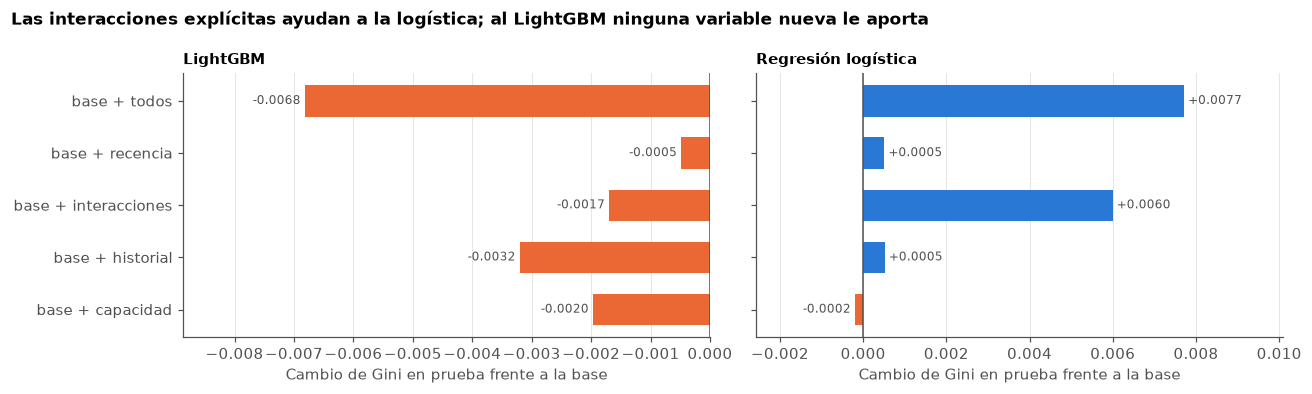

,variante,gini_prueba_lgbm,gini_prueba_logistica,delta_lgbm,delta_logistica
0,base,0.2585,0.2370,0.0000,0.0000
1,base + capacidad,0.2565,0.2368,-0.0020,-0.0002
2,base + historial,0.2553,0.2375,-0.0032,0.0005
3,base + interacciones,0.2568,0.2430,-0.0017,0.0060
4,base + recencia,0.2580,0.2375,-0.0005,0.0005
5,base + todos,0.2517,0.2447,-0.0068,0.0077


In [33]:
def hacer_logistica(columnas, C=1.0):
    cats = [c for c in columnas if c in CATEGORICAS]
    nums = [c for c in columnas if c not in cats]
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cats), ('num', StandardScaler(), nums)])
    return Pipeline([('pre', pre), ('modelo', LogisticRegression(max_iter=3000, C=C))])

filas = []
variantes = [('base', [])] + [(f'base + {g}', v) for g, v in GRUPOS_FE.items()] + [('base + todos', sum(GRUPOS_FE.values(), []))]
for nombre, extra in variantes:
    cols = BASE + extra
    m_l = ajustar_lgb(cols, m_trn)
    m_r = hacer_logistica(cols).fit(panel.loc[m_trn, cols], panel.loc[m_trn, TARGET].astype(int))
    filas.append({'variante': nombre,
                  'gini_prueba_lgbm': gini_en(m_l, cols, m_tst),
                  'gini_prueba_logistica': gini(panel.loc[m_tst, TARGET], m_r.predict_proba(panel.loc[m_tst, cols])[:, 1])})
ablacion_fe = pd.DataFrame(filas)
for c in ('gini_prueba_lgbm', 'gini_prueba_logistica'):
    ablacion_fe[f'delta_{c[12:]}'] = ablacion_fe[c] - ablacion_fe[c].iloc[0]
ablacion_fe.to_csv(ART / '07_ablacion_ingenieria_variables.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, c, titulo in ((axes[0], 'delta_lgbm', 'LightGBM'), (axes[1], 'delta_logistica', 'Regresión logística')):
    t = ablacion_fe.iloc[1:]
    colores = [AZUL if v > 0 else NARANJA for v in t[c]]
    ax.barh(t.variante, t[c], color=colores, height=0.6)
    ax.axvline(0, color=TINTA2, lw=1)
    for i, v in enumerate(t[c]):
        ax.text(v, i, f' {v:+.4f} ' , va='center', ha='left' if v >= 0 else 'right', fontsize=8, color=TINTA2)
    ax.margins(x=0.3)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('Cambio de Gini en prueba frente a la base')
    ax.grid(axis='y', visible=False)
fig.suptitle('Las interacciones explícitas ayudan a la logística; al LightGBM ninguna variable nueva le aporta', x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout()
guardar(fig, '17_ablacion_ingenieria_variables')
ablacion_fe.round(4)

**Lectura.** Para el LightGBM ningún grupo mejora el Gini de prueba: los árboles ya descubren solos las interacciones, y agregar las nueve variables juntas lo empeora en 0,007 por ruido. Para la regresión logística, las interacciones explícitas suben el Gini en 0,006, el único efecto relevante. Capacidad, recencia e historial no aportan en ninguno de los dos modelos.

**Regla de decisión.** Un grupo de variables se acepta si mejora el Gini de prueba en alguno de los dos modelos en al menos 0,002 sin empeorar el del otro en más de 0,002, y si su PSI entre desarrollo y diciembre es menor que 0,1. La segunda condición excluye el grupo de historial aunque fuera útil, porque el panel empieza en enero con todos los clientes en cero meses previos (censura por la izquierda) y en diciembre la variable toma valores que el desarrollo casi no vio.

In [34]:
psi_hist = {v: psi(panel.loc[m_dev, v], panel.loc[m_dic, v]) for v in GRUPOS_FE['historial']}
FE_ELEGIDAS = []
decisiones_fe = []
for g, vars_g in GRUPOS_FE.items():
    fila = ablacion_fe.set_index('variante').loc[f'base + {g}']
    mejora = max(fila.delta_lgbm, fila.delta_logistica) >= 0.002 and min(fila.delta_lgbm, fila.delta_logistica) >= -0.002
    psi_max = max(psi(panel.loc[m_dev, v], panel.loc[m_dic, v]) for v in vars_g)
    acepta = bool(mejora and psi_max < 0.1)
    decisiones_fe.append({'grupo': g, 'delta_lgbm': fila.delta_lgbm, 'delta_logistica': fila.delta_logistica,
                          'psi_max_diciembre': psi_max, 'aceptado': acepta})
    if acepta:
        FE_ELEGIDAS += vars_g
decisiones_fe = pd.DataFrame(decisiones_fe)
decisiones_fe.to_csv(ART / '07_decision_ingenieria_variables.csv', index=False)
print('Variables nuevas aceptadas:', FE_ELEGIDAS)
decisiones_fe.round(4)

Variables nuevas aceptadas: ['riesgo_ordinal', 'productos_x_riesgo_bajo', 'movil_y_tarjeta']


,grupo,delta_lgbm,delta_logistica,psi_max_diciembre,aceptado
0,capacidad,-0.0020,-0.0002,0.0016,False
1,historial,-0.0032,0.0005,3.6087,False
2,interacciones,-0.0017,0.0060,0.0172,True
3,recencia,-0.0005,0.0005,0.0033,False


**Lectura.** Solo se acepta el grupo de interacciones (riesgo_ordinal, productos_x_riesgo_bajo y movil_y_tarjeta): mejora la logística en 0,006 y su costo en el LightGBM (0,0017) queda dentro de la tolerancia. El historial queda fuera por partida doble: no mejora el Gini y su PSI contra diciembre es de 3,6. Las variables aceptadas pasan al embudo de selección, que decide si sobreviven.

## 8. Embudo 2: selección de variables

Se aplica la secuencia del documento metodológico (sección 3.6.1), con sus mismos umbrales:

1. Calidad de datos: se eliminan variables con más de 95 por ciento de nulos o casi constantes.
2. Importancia mínima: se eliminan variables con importancia SHAP relativa menor que 0,1 por ciento.
3. Redundancia: entre pares con correlación de Pearson mayor que 0,5 se conserva la de mayor importancia SHAP.
4. Nuevo filtro de importancia tras volver a modelar.
5. Criterio de sentido de negocio.
6. Parsimonia: se ordena por importancia y se elige el menor número de variables cuyo Gini en prueba esté a menos de 0,002 del máximo.

La importancia SHAP se calcula sobre la muestra de prueba para no premiar variables que solo sirven para memorizar el entrenamiento.

In [35]:
def importancia_shap(modelo, X):
    valores = shap.TreeExplainer(modelo).shap_values(X)
    if isinstance(valores, list):
        valores = valores[1]
    if valores.ndim == 3:
        valores = valores[:, :, 1]
    imp = pd.Series(np.abs(valores).mean(axis=0), index=X.columns)
    return imp / imp.sum()

muestra_shap = panel[m_tst].sample(5000, random_state=SEMILLA).index
pasos = []
candidatas = BASE + FE_ELEGIDAS
pasos.append(('Variables iniciales', 0, len(candidatas)))

nulos = panel.loc[m_trn, candidatas].isna().mean()
moda = panel.loc[m_trn, candidatas].apply(lambda s: s.value_counts(normalize=True).iloc[0])
quitar = [c for c in candidatas if nulos[c] > 0.95 or moda[c] > 0.99]
candidatas = [c for c in candidatas if c not in quitar]
pasos.append(('Calidad: nulos mayores a 95% o casi constantes', len(quitar), len(candidatas)))

modelo_1 = ajustar_lgb(candidatas, m_trn)
imp_1 = importancia_shap(modelo_1, panel.loc[muestra_shap, candidatas])
quitar = imp_1[imp_1 < 0.001].index.tolist()
candidatas = [c for c in candidatas if c not in quitar]
pasos.append(('Importancia SHAP relativa menor a 0,1%', len(quitar), len(candidatas)))

numericas_cand = [c for c in candidatas if c not in CATEGORICAS]
pearson = panel.loc[m_trn, numericas_cand].corr().abs()
quitar_corr = set()
for i, a in enumerate(numericas_cand):
    for b in numericas_cand[i + 1:]:
        if pearson.loc[a, b] > 0.5 and a not in quitar_corr and b not in quitar_corr:
            quitar_corr.add(a if imp_1.get(a, 0) < imp_1.get(b, 0) else b)
pares_corr = [(a, b, round(pearson.loc[a, b], 3)) for i, a in enumerate(numericas_cand) for b in numericas_cand[i + 1:] if pearson.loc[a, b] > 0.5]
candidatas = [c for c in candidatas if c not in quitar_corr]
pasos.append(('Correlación de Pearson mayor a 0,5', len(quitar_corr), len(candidatas)))
print('Pares correlacionados:', pares_corr, '\nEliminadas por correlación:', sorted(quitar_corr))

modelo_2 = ajustar_lgb(candidatas, m_trn)
imp_2 = importancia_shap(modelo_2, panel.loc[muestra_shap, candidatas]).sort_values(ascending=False)
quitar = imp_2[imp_2 < 0.001].index.tolist()
candidatas = [c for c in candidatas if c not in quitar]
pasos.append(('Importancia SHAP tras remodelar', len(quitar), len(candidatas)))

EXCLUSION_NEGOCIO = {}
candidatas = [c for c in candidatas if c not in EXCLUSION_NEGOCIO]
pasos.append(('Criterio de sentido de negocio', len(EXCLUSION_NEGOCIO), len(candidatas)))
imp_2.round(4).to_frame('importancia_shap_relativa')

Pares correlacionados: [('tiene_tarjeta_credito', 'movil_y_tarjeta', np.float64(0.573)), ('activo_movil', 'movil_y_tarjeta', np.float64(0.705)), ('riesgo_ordinal', 'productos_x_riesgo_bajo', np.float64(0.703))] 
Eliminadas por correlación: ['activo_movil', 'riesgo_ordinal', 'tiene_tarjeta_credito']


,importancia_shap_relativa
productos_x_riesgo_bajo,0.2074
banda_riesgo,0.1806
dias_ultima_transaccion,0.1557
movil_y_tarjeta,0.1034
numero_productos,0.0578
ratio_deuda_ingresos,0.0382
saldo_promedio,0.0376
antiguedad_cuenta_meses,0.0342
ingresos,0.0298
distancia_sucursal_km,0.0288


**Lectura.** Los filtros de calidad e importancia mínima no eliminan nada: no hay nulos y todas las variables superan el 0,1 por ciento de importancia. El filtro de correlación sí actúa: movil_y_tarjeta absorbe a activo_movil (0,71) y a tiene_tarjeta_credito (0,57), y productos_x_riesgo_bajo absorbe a riesgo_ordinal (0,70). Las interacciones quedan primera y cuarta en importancia. No se excluyó ninguna variable por criterio de negocio, porque todas las restantes tienen una lectura comercial razonable.

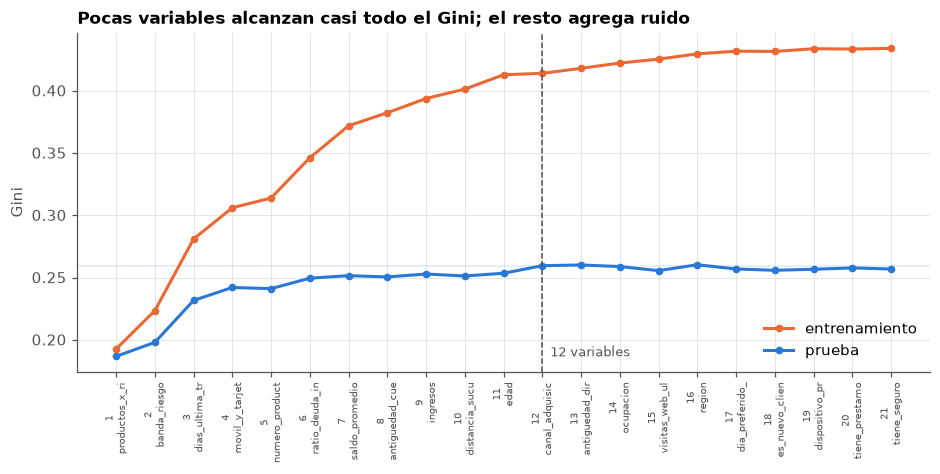

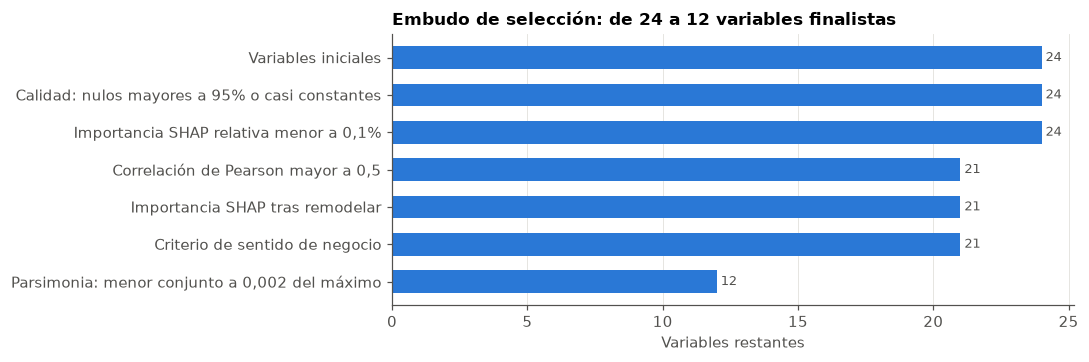

Variables finales: ['productos_x_riesgo_bajo', 'banda_riesgo', 'dias_ultima_transaccion', 'movil_y_tarjeta', 'numero_productos', 'ratio_deuda_ingresos', 'saldo_promedio', 'antiguedad_cuenta_meses', 'ingresos', 'distancia_sucursal_km', 'edad', 'canal_adquisicion']


,paso,variables_filtradas,variables_restantes
0,Variables iniciales,0,24
1,Calidad: nulos mayores a 95% o casi constantes,0,24
2,"Importancia SHAP relativa menor a 0,1%",0,24
3,"Correlación de Pearson mayor a 0,5",3,21
4,Importancia SHAP tras remodelar,0,21
5,Criterio de sentido de negocio,0,21
6,"Parsimonia: menor conjunto a 0,002 del máximo",9,12


In [36]:
ranking = [c for c in imp_2.index if c in candidatas]
curva = []
for n in range(1, len(ranking) + 1):
    cols = ranking[:n]
    m = ajustar_lgb(cols, m_trn)
    curva.append({'n_variables': n, 'variable_agregada': cols[-1], 'gini_prueba': gini_en(m, cols, m_tst),
                  'gini_entrenamiento': gini_en(m, cols, m_trn)})
curva = pd.DataFrame(curva)
mejor = curva.gini_prueba.max()
n_elegido = int(curva.loc[curva.gini_prueba >= mejor - 0.002, 'n_variables'].min())
FINALES = ranking[:n_elegido]
pasos.append(('Parsimonia: menor conjunto a 0,002 del máximo', len(ranking) - n_elegido, n_elegido))
embudo_seleccion = pd.DataFrame(pasos, columns=['paso', 'variables_filtradas', 'variables_restantes'])
embudo_seleccion.to_csv(ART / '08_embudo_seleccion.csv', index=False)
curva.to_csv(ART / '08_curva_parsimonia.csv', index=False)
with open(ART / '08_variables_finales.json', 'w') as f:
    json.dump(FINALES, f, indent=2, ensure_ascii=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(curva.n_variables, curva.gini_entrenamiento, color=NARANJA, marker='o', ms=4, label='entrenamiento')
ax.plot(curva.n_variables, curva.gini_prueba, color=AZUL, marker='o', ms=4, label='prueba')
ax.axhspan(mejor - 0.002, mejor, color=AZUL, alpha=0.12, lw=0)
ax.axvline(n_elegido, color=TINTA2, ls='--', lw=1)
ax.text(n_elegido, curva.gini_prueba.min(), f'  {n_elegido} variables', fontsize=8.5, color=TINTA2)
ax.set_xticks(curva.n_variables)
ax.set_xticklabels([f'{n}\n{v[:14]}' for n, v in zip(curva.n_variables, curva.variable_agregada)], fontsize=6.5, rotation=90)
ax.set_ylabel('Gini')
ax.legend(loc='lower right')
ax.set_title('Pocas variables alcanzan casi todo el Gini; el resto agrega ruido')
guardar(fig, '18_curva_parsimonia')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(embudo_seleccion.paso[::-1], embudo_seleccion.variables_restantes[::-1], color=AZUL, height=0.6)
for i, v in enumerate(embudo_seleccion.variables_restantes[::-1]):
    ax.text(v, i, f' {v}', va='center', fontsize=8.5, color=TINTA2)
ax.set_xlabel('Variables restantes')
ax.grid(axis='y', visible=False)
ax.set_title(f'Embudo de selección: de {embudo_seleccion.variables_restantes.iloc[0]} a {n_elegido} variables finalistas')
guardar(fig, '19_embudo_seleccion')
print('Variables finales:', FINALES)
embudo_seleccion

**Lectura.** El Gini de prueba crece rápido con las cuatro primeras variables y se aplana desde la sexta, mientras el de entrenamiento sigue subiendo: las variables adicionales solo ayudan a memorizar. La regla de parsimonia elige 12 variables, el menor conjunto a 0,002 del máximo, y descarta nueve sin poder (ocupación, región, dispositivo, préstamo, seguro, visitas web, día de pago, antigüedad de la dirección y cliente nuevo). El embudo pasa de 24 a 12 variables, en la línea del documento, que pasó de 5134 a 18.

## 9. Modelado: zoológico de modelos

Se comparan modelos de distinta naturaleza sobre las variables finalistas, todos ajustados con la muestra de entrenamiento y medidos en entrenamiento, prueba y OOT. Se incluyen dos referencias que un modelo debe superar para justificar su existencia: la regla experta del negocio (ordenar por banda de riesgo y luego por número de productos) y un modelo lineal.

* Regresión logística con codificación one hot y escalado.
* Scorecard: agrupación óptima monótona con peso de evidencia (WOE) y regresión logística, el estándar regulatorio en banca.
* Árbol de decisión, Naive Bayes, k vecinos más cercanos y máquina de soporte vectorial lineal.
* Bosque aleatorio y HistGradientBoosting de scikit learn.
* XGBoost, LightGBM y CatBoost.

Para SVM se usa la versión lineal porque la de núcleo radial escala de forma cuadrática con el número de filas. El Gini de entrenamiento se mide sobre una muestra fija de 20 mil filas para que k vecinos sea viable.

In [37]:
CATS_F = [c for c in FINALES if c in CATEGORICAS]
NUMS_F = [c for c in FINALES if c not in CATS_F]

def a_texto(X):
    X = X.copy()
    for c in X.columns:
        if c in CATEGORICAS:
            X[c] = X[c].astype(str)
    return X

def preprocesador():
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CATS_F), ('num', StandardScaler(), NUMS_F)])

PARAMS_XGB = dict(n_estimators=600, learning_rate=0.02, max_depth=4, min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
                  enable_categorical=True, tree_method='hist', n_jobs=8, random_state=SEMILLA, eval_metric='auc')
PARAMS_CAT = dict(iterations=800, learning_rate=0.03, depth=5, l2_leaf_reg=5, random_seed=SEMILLA, verbose=0, thread_count=8)
modelos = {
    'Regresión logística': Pipeline([('pre', preprocesador()), ('m', LogisticRegression(max_iter=3000))]),
    'Scorecard WOE': make_pipeline(FunctionTransformer(a_texto), BinningProcess(variable_names=FINALES, categorical_variables=CATS_F),
                                   LogisticRegression(max_iter=3000)),
    'Árbol de decisión': Pipeline([('pre', preprocesador()), ('m', DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEMILLA))]),
    'Naive Bayes': Pipeline([('pre', preprocesador()), ('m', GaussianNB())]),
    'k vecinos': Pipeline([('pre', preprocesador()), ('m', KNeighborsClassifier(n_neighbors=300, n_jobs=8))]),
    'SVM lineal': Pipeline([('pre', preprocesador()), ('m', LinearSVC(C=0.05))]),
    'Bosque aleatorio': Pipeline([('pre', preprocesador()), ('m', RandomForestClassifier(n_estimators=400, min_samples_leaf=100, max_features=0.5, n_jobs=8, random_state=SEMILLA))]),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=200,
                                                           categorical_features='from_dtype', random_state=SEMILLA),
    'XGBoost': xgb.XGBClassifier(**PARAMS_XGB),
    'LightGBM': lgb.LGBMClassifier(**PARAMS_REF),
    'CatBoost': make_pipeline(FunctionTransformer(a_texto), cb.CatBoostClassifier(**PARAMS_CAT, cat_features=CATS_F)),
}

def puntuar(modelo, X):
    return modelo.predict_proba(X)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X)

idx_train_eval = panel[m_trn].sample(20000, random_state=SEMILLA).index
evaluar_en = {'entrenamiento': idx_train_eval, 'prueba': panel[m_tst].index, 'oot': panel[m_oot].index}
resultados, predicciones_oot, predicciones_prueba = [], {}, {}

regla = lambda d: d.banda_riesgo.map({'high': 0, 'medium': 1, 'low': 2}).astype(int) * 10 + d.numero_productos
fila = {'modelo': 'Regla experta de negocio', 'segundos': 0.0}
for k, idx in evaluar_en.items():
    fila[f'gini_{k}'] = gini(panel.loc[idx, TARGET], regla(panel.loc[idx]))
fila['ks_oot'] = ks(panel.loc[m_oot, TARGET], regla(panel.loc[m_oot]))
predicciones_oot['Regla experta de negocio'] = regla(panel.loc[m_oot]).values
resultados.append(fila)

for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(panel.loc[m_trn, FINALES], panel.loc[m_trn, TARGET].astype(int))
    fila = {'modelo': nombre, 'segundos': time.time() - t0}
    for k, idx in evaluar_en.items():
        p = puntuar(modelo, panel.loc[idx, FINALES])
        fila[f'gini_{k}'] = gini(panel.loc[idx, TARGET], p)
        if k == 'oot':
            predicciones_oot[nombre] = p
            fila['ks_oot'] = ks(panel.loc[idx, TARGET], p)
        if k == 'prueba':
            predicciones_prueba[nombre] = p
    resultados.append(fila)
    print(f"{nombre:28s} prueba {fila['gini_prueba']:.4f}  oot {fila['gini_oot']:.4f}  ({fila['segundos']:.1f} s)")
zoologico = pd.DataFrame(resultados)
zoologico['brecha_entrenamiento_oot'] = zoologico.gini_entrenamiento - zoologico.gini_oot
zoologico = zoologico.sort_values('gini_oot', ascending=False).reset_index(drop=True)
zoologico.to_csv(ART / '09_zoologico_modelos.csv', index=False)
zoologico.round(4)

Regresión logística          prueba 0.2441  oot 0.2351  (0.1 s)


Scorecard WOE                prueba 0.2425  oot 0.2248  (1.1 s)


Árbol de decisión            prueba 0.2561  oot 0.2439  (0.2 s)
Naive Bayes                  prueba 0.2325  oot 0.2173  (0.1 s)


k vecinos                    prueba 0.2400  oot 0.2217  (0.0 s)
SVM lineal                   prueba 0.2434  oot 0.2336  (0.1 s)


Bosque aleatorio             prueba 0.2551  oot 0.2447  (8.9 s)


HistGradientBoosting         prueba 0.2536  oot 0.2420  (0.3 s)


XGBoost                      prueba 0.2609  oot 0.2418  (0.8 s)


LightGBM                     prueba 0.2596  oot 0.2413  (1.0 s)


CatBoost                     prueba 0.2558  oot 0.2413  (12.9 s)


,modelo,segundos,gini_entrenamiento,gini_prueba,gini_oot,ks_oot,brecha_entrenamiento_oot
0,Bosque aleatorio,8.9280,0.4954,0.2551,0.2447,0.1582,0.2507
1,Árbol de decisión,0.1986,0.2859,0.2561,0.2439,0.1498,0.0420
2,HistGradientBoosting,0.2690,0.3153,0.2536,0.2420,0.1515,0.0733
3,XGBoost,0.7744,0.3798,0.2609,0.2418,0.1532,0.1381
4,LightGBM,0.9866,0.4106,0.2596,0.2413,0.1524,0.1693
5,CatBoost,12.9059,0.3681,0.2558,0.2413,0.1504,0.1268
6,Regresión logística,0.1072,0.2584,0.2441,0.2351,0.1493,0.0233
7,SVM lineal,0.1084,0.2564,0.2434,0.2336,0.1511,0.0228
8,Scorecard WOE,1.1140,0.2603,0.2425,0.2248,0.1475,0.0355
9,k vecinos,0.0400,0.2830,0.2400,0.2217,0.1417,0.0613


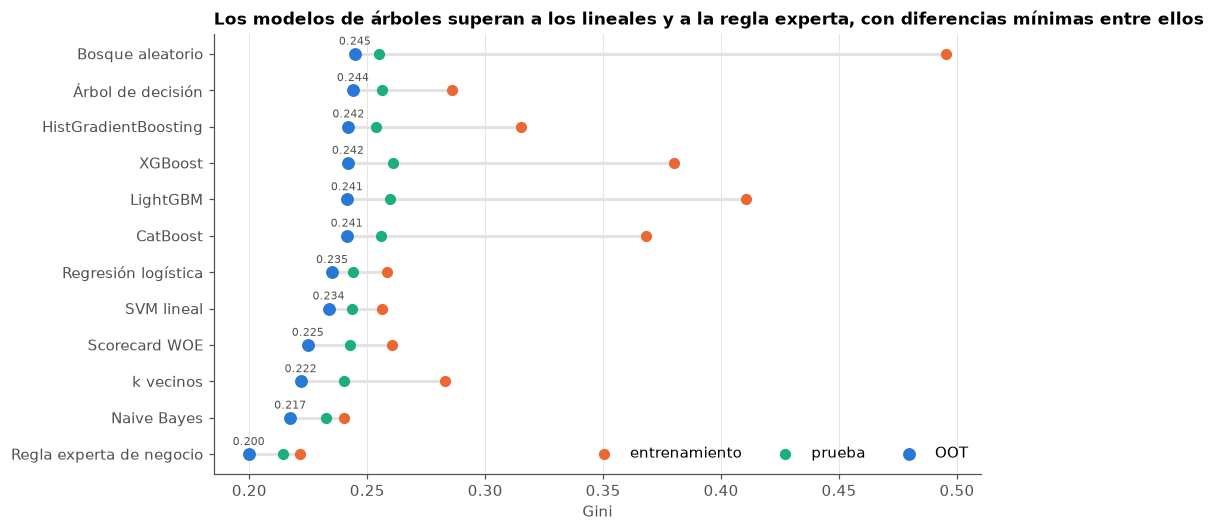

In [38]:
fig, ax = plt.subplots(figsize=(9, 5.2))
orden = zoologico.sort_values('gini_oot')
y = np.arange(len(orden))
ax.hlines(y, orden[['gini_prueba', 'gini_oot']].min(axis=1), orden.gini_entrenamiento, color=GRILLA, lw=2)
ax.scatter(orden.gini_entrenamiento, y, color=NARANJA, s=40, label='entrenamiento', zorder=3)
ax.scatter(orden.gini_prueba, y, color=AQUA, s=40, label='prueba', zorder=3)
ax.scatter(orden.gini_oot, y, color=AZUL, s=55, label='OOT', zorder=4)
for v, yy in zip(orden.gini_oot, y):
    ax.text(v, yy + 0.25, f'{v:.3f}', ha='center', fontsize=7.5, color=TINTA2)
ax.set_yticks(y)
ax.set_yticklabels(orden.modelo)
ax.set_xlabel('Gini')
ax.legend(loc='lower right', ncol=3)
ax.grid(axis='y', visible=False)
ax.set_title('Los modelos de árboles superan a los lineales y a la regla experta, con diferencias mínimas entre ellos')
guardar(fig, '20_zoologico_modelos')

**Lectura.** Todos los modelos superan a la regla experta (Gini OOT de 0,200), lo que justifica construir un modelo. Los de árboles quedan entre 0,241 y 0,245 y los lineales entre 0,225 y 0,235; la ventaja de los árboles coincide con las interacciones del análisis exploratorio. El bosque aleatorio logra el mejor Gini OOT sin ajustar (0,245), pero con una brecha de 0,25 entre entrenamiento y OOT, señal de memorización. Naive Bayes y k vecinos son los más débiles. Se elige el LightGBM como familia a ajustar: está a 0,003 del mejor, es el estándar del documento, es rápido, admite restricciones de monotonía y tiene SHAP exacto.

## 10. Ajuste bayesiano de hiperparámetros con Optuna

Se ajusta el LightGBM, como en el documento, con optimización bayesiana (muestreador TPE de Optuna). Tres decisiones de diseño evitan la fuga hacia la evaluación:

* **Solo se usa la muestra de entrenamiento**, nunca prueba ni OOT.
* **Validación temporal con ventana expansiva**: se entrena con los meses anteriores y se valida en mayo, junio, julio y agosto por separado, imitando el uso real del modelo.
* **El número de árboles es un hiperparámetro** y no se usa parada temprana sobre el pliegue de validación, que filtraría información del pliegue al modelo.

El documento busca hiperparámetros que maximicen y estabilicen el Gini. Por eso la función objetivo es el Gini promedio de los cuatro meses menos la mitad de su desviación estándar. Los rangos parten de los del documento (tasa de aprendizaje, profundidad de 3 a 6, hojas de 2 a 64, fracciones de muestreo de 0,5 a 1 y scale_pos_weight de 0,5 a 1,5) y se agregan regularización y tamaño mínimo de hoja.

In [39]:
entrenamiento = panel[m_trn]
MESES_CV = [202605, 202606, 202607, 202608]

def params_desde(trial):
    return dict(
        objective='binary', verbose=-1, n_jobs=8, random_state=SEMILLA, subsample_freq=1,
        learning_rate=trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        n_estimators=trial.suggest_int('n_estimators', 100, 1200, step=50),
        max_depth=trial.suggest_int('max_depth', 3, 6),
        num_leaves=trial.suggest_int('num_leaves', 2, 64),
        min_child_samples=trial.suggest_int('min_child_samples', 50, 1500, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        min_split_gain=trial.suggest_float('min_split_gain', 0.0, 3.0),
        scale_pos_weight=trial.suggest_float('scale_pos_weight', 0.5, 1.5))

def gini_temporal(params, columnas=None):
    columnas = FINALES if columnas is None else columnas
    ginis = []
    for mes in MESES_CV:
        a, b = entrenamiento[entrenamiento.mes < mes], entrenamiento[entrenamiento.mes == mes]
        m = lgb.LGBMClassifier(**params).fit(a[columnas], a[TARGET].astype(int))
        ginis.append(gini(b[TARGET], m.predict_proba(b[columnas])[:, 1]))
    return np.array(ginis)

def objetivo_optuna(trial):
    ginis = gini_temporal(params_desde(trial))
    trial.set_user_attr('gini_medio', float(ginis.mean()))
    trial.set_user_attr('gini_desvio', float(ginis.std()))
    return float(ginis.mean() - 0.5 * ginis.std())

ginis_ref = gini_temporal(PARAMS_REF)
print(f'Parámetros de referencia: Gini temporal {ginis_ref.mean():.4f} con desvío {ginis_ref.std():.4f}')
t0 = time.time()
estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.enqueue_trial({k: v for k, v in PARAMS_REF.items() if k in ('learning_rate', 'n_estimators', 'num_leaves', 'min_child_samples', 'subsample', 'colsample_bytree', 'reg_lambda')}
                      | {'max_depth': 6, 'reg_alpha': 1e-3, 'min_split_gain': 0.0, 'scale_pos_weight': 1.0})
estudio.optimize(objetivo_optuna, n_trials=N_TRIALS)
print(f'{N_TRIALS} pruebas en {(time.time() - t0) / 60:.1f} minutos')
PARAMS_OPT = dict(objective='binary', verbose=-1, n_jobs=8, random_state=SEMILLA, subsample_freq=1, **estudio.best_params)
historial = estudio.trials_dataframe()
historial.to_csv(ART / '10_historial_optuna.csv', index=False)
with open(ART / '10_mejores_hiperparametros.json', 'w') as f:
    json.dump(PARAMS_OPT, f, indent=2)
print('Mejor objetivo:', round(estudio.best_value, 4), '| Gini medio:', round(estudio.best_trial.user_attrs['gini_medio'], 4))
PARAMS_OPT

Parámetros de referencia: Gini temporal 0.2575 con desvío 0.0146


40 pruebas en 1.6 minutos
Mejor objetivo: 0.261 | Gini medio: 0.2691


{'objective': 'binary',
 'verbose': -1,
 'n_jobs': 8,
 'random_state': 42,
 'subsample_freq': 1,
 'learning_rate': 0.010003615761209218,
 'n_estimators': 500,
 'max_depth': 3,
 'num_leaves': 18,
 'min_child_samples': 510,
 'subsample': 0.6380387141740861,
 'colsample_bytree': 0.997310577371386,
 'reg_alpha': 0.7800745609817367,
 'reg_lambda': 3.374836684211265,
 'min_split_gain': 0.3277739092445509,
 'scale_pos_weight': 0.611153200272058}

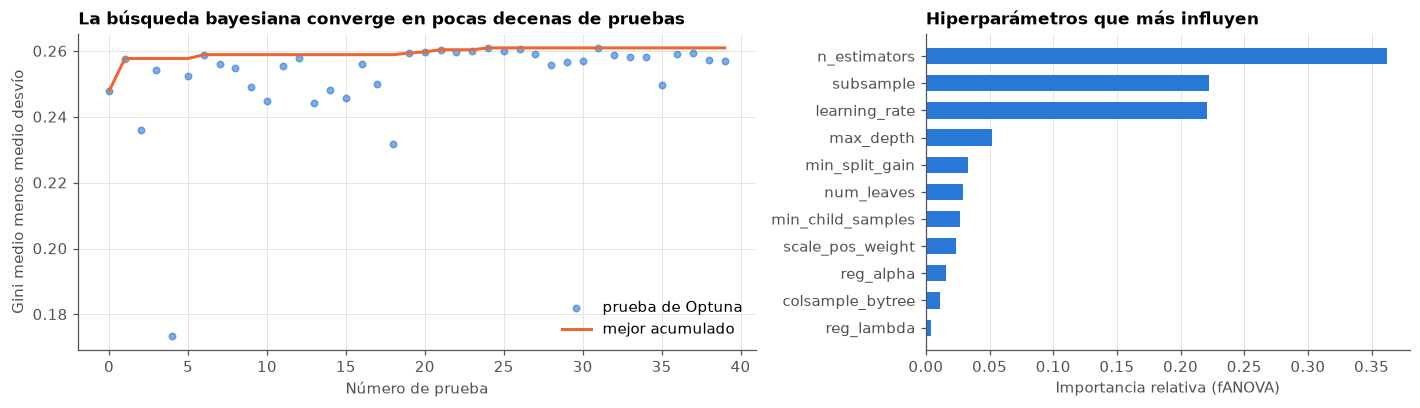

In [40]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
a1.scatter(historial.number, historial.value, color=AZUL, s=18, alpha=0.6, label='prueba de Optuna')
a1.plot(historial.number, historial.value.cummax(), color=NARANJA, label='mejor acumulado')
a1.set_xlabel('Número de prueba')
a1.set_ylabel('Gini medio menos medio desvío')
a1.legend(loc='lower right')
a1.set_title('La búsqueda bayesiana converge en pocas decenas de pruebas')
importancias_hp = pd.Series(optuna.importance.get_param_importances(estudio)).sort_values()
a2.barh(importancias_hp.index, importancias_hp.values, color=AZUL, height=0.6)
a2.set_xlabel('Importancia relativa (fANOVA)')
a2.grid(axis='y', visible=False)
a2.set_title('Hiperparámetros que más influyen')
fig.tight_layout()
guardar(fig, '21_optuna_historial_importancia')

**Lectura.** La búsqueda mejora el objetivo de 0,248 (parámetros de referencia, primera prueba) a 0,261, con un Gini temporal medio de 0,269. Optuna prefiere un modelo muy regularizado: profundidad 3, 500 árboles, tasa de aprendizaje de 0,01 y al menos 510 filas por hoja, en coherencia con la prueba de memorización. El número de árboles, el submuestreo y la tasa de aprendizaje son los hiperparámetros que más influyen.

## 11. Ablaciones

Una ablación cambia un solo componente del modelo ajustado y mide el efecto, para saber qué decisiones aportan realmente. Todas se evalúan en prueba y OOT con el LightGBM ajustado por Optuna, salvo que se indique lo contrario. Se reporta también el puntaje de Brier, porque algunas variantes (pesos de clase, sobremuestreo) no cambian el orden pero sí deforman las probabilidades.

Ablaciones realizadas:

1. Conjunto de variables: base completa, base con dias_ultima_interaccion, base con todas las variables nuevas y finalistas.
2. Hiperparámetros: referencia frente a Optuna.
3. Tratamiento del desbalance: ninguno, peso de clase balanceado y sobremuestreo SMOTENC.
4. Restricciones de monotonía según el sentido de negocio.
5. Ventana de entrenamiento: últimos cuatro meses frente a los ocho meses de desarrollo.
6. Promedio de semillas.
7. Ensamble de LightGBM, CatBoost y XGBoost.

In [41]:
ablaciones = []
def registrar(ablacion, variante, p_prueba, p_oot):
    ablaciones.append({'ablacion': ablacion, 'variante': variante,
                       'gini_prueba': gini(panel.loc[m_tst, TARGET], p_prueba), 'gini_oot': gini(panel.loc[m_oot, TARGET], p_oot),
                       'brier_oot': brier_score_loss(panel.loc[m_oot, TARGET], np.clip(p_oot, 0, 1)),
                       'prob_media_oot': float(np.mean(p_oot))})

def ajustar_y_registrar(ablacion, variante, columnas, params, mascara=None, datos_fit=None):
    datos_fit = panel.loc[m_trn if mascara is None else mascara] if datos_fit is None else datos_fit
    m = lgb.LGBMClassifier(**params).fit(datos_fit[columnas], datos_fit[TARGET].astype(int))
    p_t, p_o = predecir(m, columnas, m_tst), predecir(m, columnas, m_oot)
    registrar(ablacion, variante, p_t, p_o)
    return m, p_t, p_o

for variante, cols in (('base completa', BASE), ('base con dias_ultima_interaccion', BASE + [SOSPECHOSA]),
                       ('base con todas las variables nuevas', BASE + sum(GRUPOS_FE.values(), [])), ('finalistas', FINALES)):
    ajustar_y_registrar('1. Variables', variante, cols, PARAMS_OPT)

ajustar_y_registrar('2. Hiperparámetros', 'referencia', FINALES, PARAMS_REF)
modelo_opt, p_prueba_opt, p_oot_opt = ajustar_y_registrar('2. Hiperparámetros', 'Optuna', FINALES, PARAMS_OPT)

ajustar_y_registrar('3. Desbalance', 'ninguno', FINALES, dict(PARAMS_OPT, scale_pos_weight=1.0))
peso = (panel.loc[m_trn, TARGET] == 0).sum() / (panel.loc[m_trn, TARGET] == 1).sum()
ajustar_y_registrar('3. Desbalance', f'peso balanceado ({peso:.1f})', FINALES, dict(PARAMS_OPT, scale_pos_weight=peso))
X_s = panel.loc[m_trn, FINALES].copy()
for c in CATS_F:
    X_s[c] = X_s[c].cat.codes
smote = SMOTENC(categorical_features=[FINALES.index(c) for c in CATS_F], sampling_strategy=0.5, random_state=SEMILLA) if CATS_F else None
from imblearn.over_sampling import SMOTE
smote = smote or SMOTE(sampling_strategy=0.5, random_state=SEMILLA)
X_res, y_res = smote.fit_resample(X_s, panel.loc[m_trn, TARGET].astype(int))
for c in CATS_F:
    X_res[c] = pd.Categorical.from_codes(X_res[c].astype(int), dtype=TIPOS_CAT[c])
ajustar_y_registrar('3. Desbalance', 'SMOTENC al 50%', FINALES, dict(PARAMS_OPT, scale_pos_weight=1.0), datos_fit=X_res.assign(objetivo=y_res.values))

signos = {c: int(np.sign(stats.spearmanr(panel.loc[m_trn, c], panel.loc[m_trn, TARGET]).statistic)) for c in NUMS_F}
signos = {c: (s if abs(stats.spearmanr(panel.loc[m_trn, c], panel.loc[m_trn, TARGET]).statistic) > 0.01 else 0) for c, s in signos.items()}
restricciones = [signos.get(c, 0) for c in FINALES]
ajustar_y_registrar('4. Monotonía', 'sin restricciones', FINALES, PARAMS_OPT)
modelo_mono, _, _ = ajustar_y_registrar('4. Monotonía', 'con restricciones de negocio', FINALES, dict(PARAMS_OPT, monotone_constraints=restricciones))

ajustar_y_registrar('5. Ventana', 'últimos 4 meses', FINALES, PARAMS_OPT, mascara=m_trn & (panel.mes >= 202605))
ajustar_y_registrar('5. Ventana', '8 meses de desarrollo', FINALES, PARAMS_OPT)

p_t_sem, p_o_sem = [], []
for s in range(5):
    m = lgb.LGBMClassifier(**dict(PARAMS_OPT, random_state=SEMILLA + s)).fit(panel.loc[m_trn, FINALES], panel.loc[m_trn, TARGET].astype(int))
    p_t_sem.append(predecir(m, FINALES, m_tst))
    p_o_sem.append(predecir(m, FINALES, m_oot))
registrar('6. Semillas', '1 semilla', p_t_sem[0], p_o_sem[0])
registrar('6. Semillas', 'promedio de 5 semillas', np.mean(p_t_sem, axis=0), np.mean(p_o_sem, axis=0))

registrar('7. Ensamble', 'LightGBM Optuna', p_prueba_opt, p_oot_opt)
registrar('7. Ensamble', 'promedio LightGBM, CatBoost y XGBoost',
          np.mean([p_prueba_opt, predicciones_prueba['CatBoost'], predicciones_prueba['XGBoost']], axis=0),
          np.mean([p_oot_opt, predicciones_oot['CatBoost'], predicciones_oot['XGBoost']], axis=0))
tabla_ablaciones = pd.DataFrame(ablaciones)
tabla_ablaciones.to_csv(ART / '11_ablaciones.csv', index=False)
print('Restricciones de monotonía:', dict(zip(FINALES, restricciones)))
tabla_ablaciones.round(4)

Restricciones de monotonía: {'productos_x_riesgo_bajo': 1, 'banda_riesgo': 0, 'dias_ultima_transaccion': -1, 'movil_y_tarjeta': 1, 'numero_productos': 1, 'ratio_deuda_ingresos': -1, 'saldo_promedio': 1, 'antiguedad_cuenta_meses': 1, 'ingresos': 0, 'distancia_sucursal_km': 0, 'edad': 0, 'canal_adquisicion': 0}


,ablacion,variante,gini_prueba,gini_oot,brier_oot,prob_media_oot
0,1. Variables,base completa,0.2573,0.2475,0.1268,0.0933
1,1. Variables,base con dias_ultima_interaccion,0.2567,0.2472,0.1268,0.0933
2,1. Variables,base con todas las variables nuevas,0.2575,0.2494,0.1265,0.0937
3,1. Variables,finalistas,0.2595,0.2496,0.1266,0.0928
4,2. Hiperparámetros,referencia,0.2596,0.2413,0.1233,0.1397
5,2. Hiperparámetros,Optuna,0.2595,0.2496,0.1266,0.0928
6,3. Desbalance,ninguno,0.2594,0.2488,0.1230,0.1410
7,3. Desbalance,peso balanceado (5.6),0.2615,0.2490,0.2195,0.4546
8,3. Desbalance,SMOTENC al 50%,0.2144,0.1968,0.1398,0.2553
9,4. Monotonía,sin restricciones,0.2595,0.2496,0.1266,0.0928


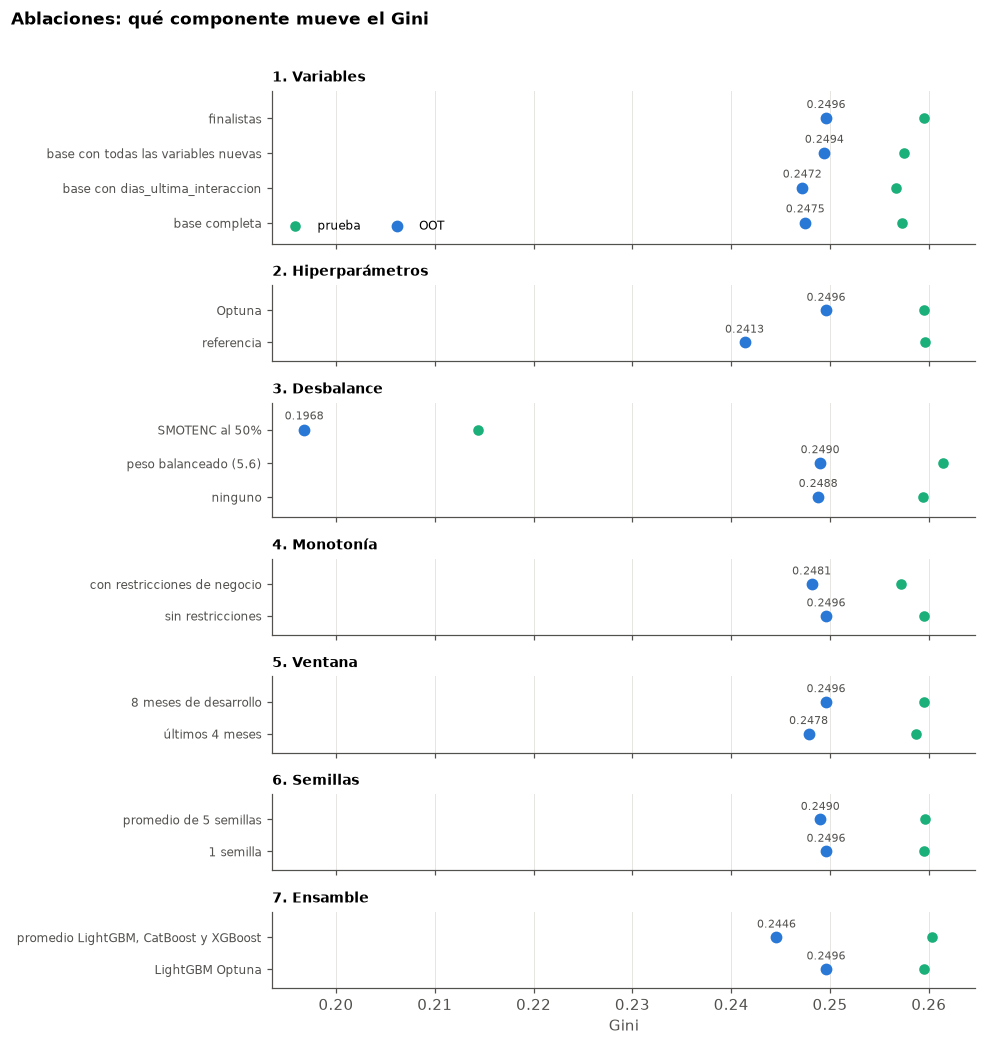

In [42]:
grupos_abl = tabla_ablaciones.ablacion.unique()
fig, axes = plt.subplots(len(grupos_abl), 1, figsize=(9, 0.42 * len(tabla_ablaciones) + 2.5), sharex=True,
                         gridspec_kw={'height_ratios': [tabla_ablaciones.ablacion.eq(g).sum() for g in grupos_abl]})
for ax, g in zip(axes, grupos_abl):
    t = tabla_ablaciones[tabla_ablaciones.ablacion == g]
    yy = np.arange(len(t))
    ax.scatter(t.gini_prueba, yy, color=AQUA, s=35, label='prueba', zorder=3)
    ax.scatter(t.gini_oot, yy, color=AZUL, s=45, label='OOT', zorder=3)
    for v, y0 in zip(t.gini_oot, yy):
        ax.text(v, y0 + 0.3, f'{v:.4f}', ha='center', fontsize=7, color=TINTA2)
    ax.set_yticks(yy)
    ax.set_yticklabels(t.variante, fontsize=8)
    ax.set_ylim(-0.6, len(t) - 0.2)
    ax.set_title(g, fontsize=9, loc='left')
    ax.grid(axis='y', visible=False)
axes[0].legend(loc='lower left', ncol=2, fontsize=8)
axes[-1].set_xlabel('Gini')
fig.suptitle('Ablaciones: qué componente mueve el Gini', x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.97])
guardar(fig, '22_ablaciones')

**Lectura.** Lecturas por ablación:

1. Las 12 finalistas (0,2496 en OOT) superan a la base completa de 21 variables (0,2475); agregar dias_ultima_interaccion no mejora (0,2472).
2. Optuna sube el Gini OOT de 0,2413 a 0,2496 frente a los parámetros de referencia.
3. Ponderar la clase positiva casi no cambia el Gini, pero destruye la calibración: el Brier pasa de 0,123 a 0,220 y la probabilidad media llega a 45 por ciento frente a una tasa real de 15. SMOTENC baja el Gini a 0,197 porque inventa clientes sintéticos en un problema de señal débil. Con una prevalencia de 15 por ciento y una métrica de orden, el desbalance no requiere tratamiento.
4. Las restricciones de monotonía cuestan 0,0023 de Gini en prueba.
5. Entrenar con los 8 meses supera a usar solo los últimos 4, como concluye el documento: más historia capta mejor los perfiles.
6. Promediar 5 semillas deja el Gini prácticamente igual.
7. El ensamble con CatBoost y XGBoost no supera al LightGBM en OOT (0,2446).

**Elección del modelo final.** La regla, fijada antes de ver los resultados, es elegir la variante más simple salvo que una más compleja mejore el Gini de prueba en al menos 0,003, y confirmar que la OOT no contradice la decisión. Los parámetros se toman de Optuna y el promedio de semillas se incorpora si no empeora prueba, porque reduce la varianza de la predicción sin costo de interpretabilidad.

In [43]:
abl = tabla_ablaciones.set_index(['ablacion', 'variante'])
gana_ensamble = (abl.loc[('7. Ensamble', 'promedio LightGBM, CatBoost y XGBoost'), 'gini_prueba']
                 - abl.loc[('7. Ensamble', 'LightGBM Optuna'), 'gini_prueba']) >= 0.003
gana_mono = (abl.loc[('4. Monotonía', 'con restricciones de negocio'), 'gini_prueba']
             >= abl.loc[('4. Monotonía', 'sin restricciones'), 'gini_prueba'] - 0.001)
usa_semillas = (abl.loc[('6. Semillas', 'promedio de 5 semillas'), 'gini_prueba']
                >= abl.loc[('6. Semillas', '1 semilla'), 'gini_prueba'] - 0.0005)
PARAMS_FINAL = dict(PARAMS_OPT, monotone_constraints=restricciones) if gana_mono else dict(PARAMS_OPT)
SEMILLAS_FINAL = [SEMILLA + s for s in range(5)] if usa_semillas else [SEMILLA]
ELECCION = {'modelo': 'Ensamble LightGBM, CatBoost y XGBoost' if gana_ensamble else 'LightGBM Optuna',
            'restricciones_monotonia': bool(gana_mono), 'semillas': SEMILLAS_FINAL, 'variables': FINALES}
ELECCION

{'modelo': 'LightGBM Optuna',
 'restricciones_monotonia': False,
 'semillas': [42, 43, 44, 45, 46],
 'variables': ['productos_x_riesgo_bajo',
  'banda_riesgo',
  'dias_ultima_transaccion',
  'movil_y_tarjeta',
  'numero_productos',
  'ratio_deuda_ingresos',
  'saldo_promedio',
  'antiguedad_cuenta_meses',
  'ingresos',
  'distancia_sucursal_km',
  'edad',
  'canal_adquisicion']}

**Lectura.** Se elige el LightGBM ajustado por Optuna, sin restricciones de monotonía y con promedio de 5 semillas. El ensamble mejora la prueba en solo 0,0008, por debajo del umbral de 0,003, y empeora la OOT. La monotonía cuesta 0,0023 en prueba, más que la tolerancia de 0,001; además, la validación de sentido de negocio de la sección 12 muestra que el modelo ya respeta los signos esperados sin forzarlos. El promedio de semillas no empeora la prueba y reduce la varianza de la predicción.

In [44]:
def entrenar_configuracion(mascara):
    d = panel.loc[mascara]
    y = d[TARGET].astype(int)
    modelos_cfg = [lgb.LGBMClassifier(**dict(PARAMS_FINAL, random_state=s)).fit(d[FINALES], y) for s in SEMILLAS_FINAL]
    if gana_ensamble:
        modelos_cfg.append(make_pipeline(FunctionTransformer(a_texto), cb.CatBoostClassifier(**PARAMS_CAT, cat_features=CATS_F)).fit(d[FINALES], y))
        modelos_cfg.append(xgb.XGBClassifier(**PARAMS_XGB).fit(d[FINALES], y))
    return modelos_cfg

def predecir_configuracion(modelos_cfg, mascara):
    X = panel.loc[mascara, FINALES]
    n = len(SEMILLAS_FINAL)
    p_lgb = np.mean([m.predict_proba(X)[:, 1] for m in modelos_cfg[:n]], axis=0)
    if gana_ensamble:
        return np.mean([p_lgb] + [m.predict_proba(X)[:, 1] for m in modelos_cfg[n:]], axis=0)
    return p_lgb

modelos_dev = entrenar_configuracion(m_trn)
p_trn = predecir_configuracion(modelos_dev, m_trn)
p_tst = predecir_configuracion(modelos_dev, m_tst)
p_oot = predecir_configuracion(modelos_dev, m_oot)
p_dic_dev = predecir_configuracion(modelos_dev, m_dic)
y_trn, y_tst, y_oot = (panel.loc[mk, TARGET].astype(int).values for mk in (m_trn, m_tst, m_oot))

## 12. Explicabilidad con SHAP

Como en la sección 3.7.4 del documento, se usan valores SHAP para la explicabilidad global y local. Un valor SHAP positivo aumenta el logaritmo de la razón de probabilidades de convertir respecto del promedio del modelo; uno negativo la reduce. Se calculan sobre una muestra de 4 mil filas de OOT con el primer LightGBM del modelo de desarrollo.

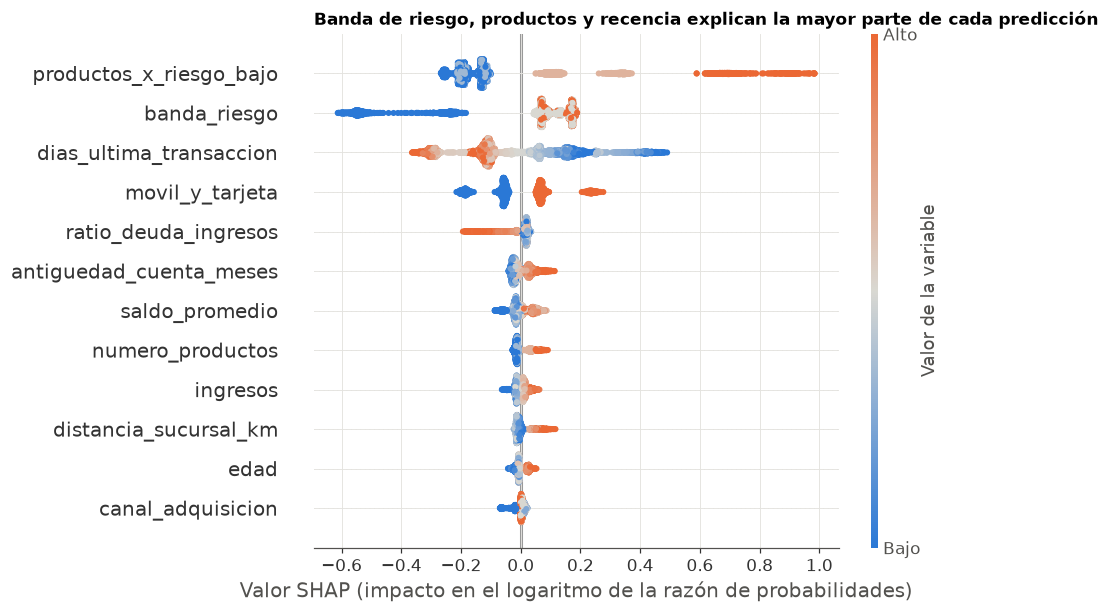

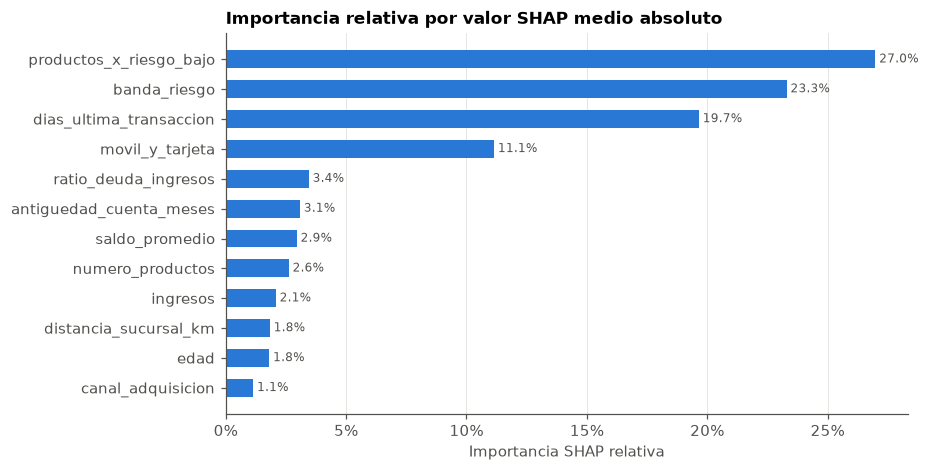

In [45]:
lgb_dev = modelos_dev[0]
idx_shap = panel[m_oot].sample(4000, random_state=SEMILLA).index
X_shap = panel.loc[idx_shap, FINALES]
valores_shap = shap.TreeExplainer(lgb_dev).shap_values(X_shap)
if isinstance(valores_shap, list):
    valores_shap = valores_shap[1]
if valores_shap.ndim == 3:
    valores_shap = valores_shap[:, :, 1]
X_plot = X_shap.copy()
for c in CATS_F:
    X_plot[c] = X_plot[c].cat.codes
importancia_final = pd.Series(np.abs(valores_shap).mean(axis=0), index=FINALES)
importancia_final = (importancia_final / importancia_final.sum()).sort_values(ascending=False)
importancia_final.to_csv(ART / '12_importancia_shap_relativa.csv', header=['importancia_relativa'])

shap.summary_plot(valores_shap, X_plot, show=False, max_display=len(FINALES), plot_size=(9, 5.5),
                  cmap=mpl.colors.LinearSegmentedColormap.from_list('shap', [AZUL, '#d9d8d2', NARANJA]))
fig = plt.gcf()
fig.axes[0].set_title('Banda de riesgo, productos y recencia explican la mayor parte de cada predicción', loc='left', fontweight='bold')
fig.axes[0].set_xlabel('Valor SHAP (impacto en el logaritmo de la razón de probabilidades)')
fig.axes[-1].set_ylabel('Valor de la variable')
fig.axes[-1].set_yticklabels(['Bajo', 'Alto'])
guardar(fig, '23_shap_beeswarm')

fig, ax = plt.subplots(figsize=(8, 4.5))
orden = importancia_final.sort_values()
ax.barh(orden.index, orden.values, color=AZUL, height=0.6)
for i, v in enumerate(orden.values):
    ax.text(v, i, f' {v:.1%}', va='center', fontsize=8, color=TINTA2)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel('Importancia SHAP relativa')
ax.grid(axis='y', visible=False)
ax.set_title('Importancia relativa por valor SHAP medio absoluto')
guardar(fig, '24_shap_importancia_relativa')

**Lectura.** Productos en riesgo bajo (27 por ciento), banda de riesgo (23) y días desde la última transacción (20) explican el 70 por ciento de la importancia; con movil_y_tarjeta (11) se llega al 81 por ciento. Las direcciones son las esperadas: más productos en riesgo bajo, riesgo bajo, transacción reciente y la combinación de móvil y tarjeta aumentan la propensión, y un ratio de deuda alto la reduce. Las variables demográficas (edad, ingresos, distancia, canal) tienen efectos pequeños, cada una con menos del 3 por ciento.

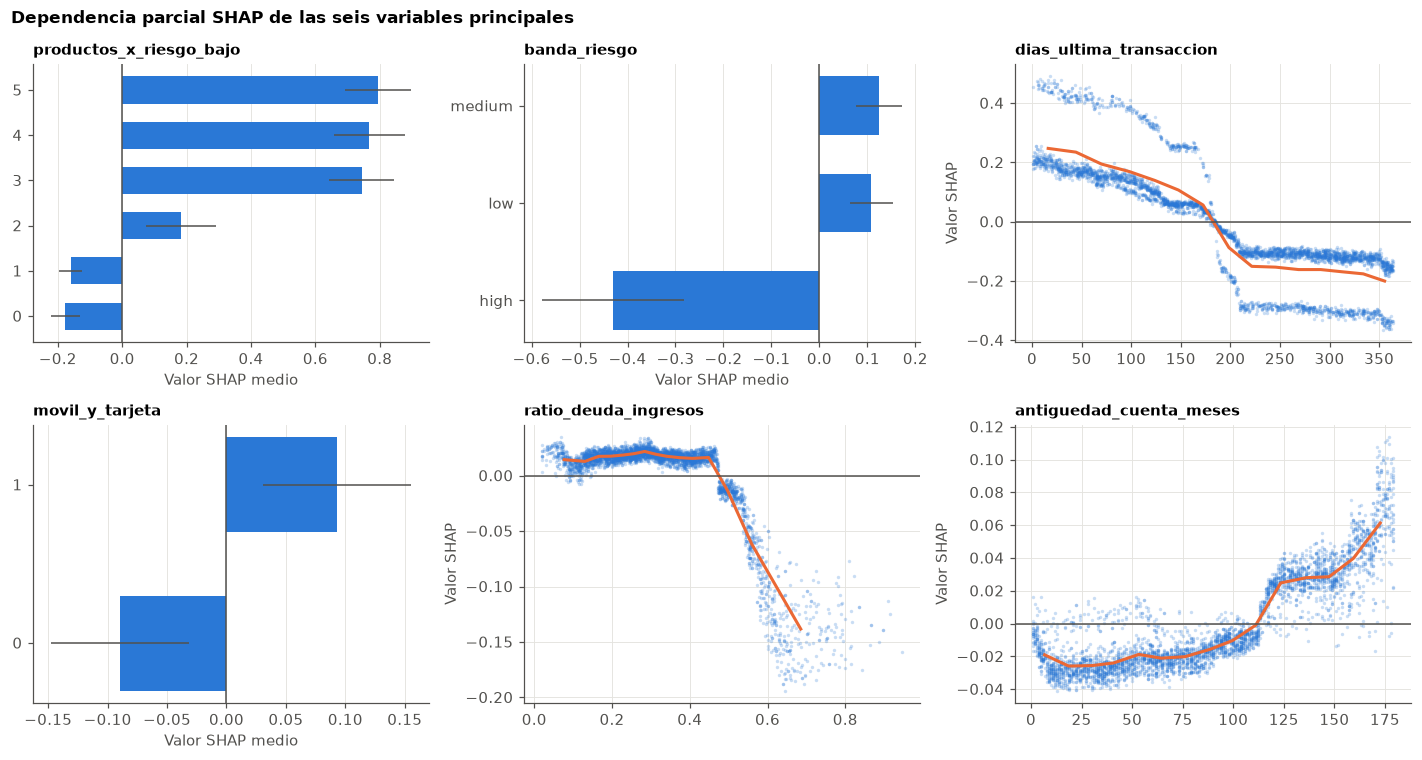

,variable,efecto_esperado,efecto_observado,coherente
0,productos_x_riesgo_bajo,positivo,positivo (rho 0.63),True
1,banda_riesgo,low mayor que medium mayor que high,low mayor que medium mayor que high,True
2,dias_ultima_transaccion,negativo,negativo (rho -0.89),True
3,movil_y_tarjeta,positivo,positivo (rho 0.86),True
4,numero_productos,positivo,positivo (rho 0.82),True
5,ratio_deuda_ingresos,negativo,negativo (rho -0.46),True
6,saldo_promedio,positivo,positivo (rho 0.80),True
7,antiguedad_cuenta_meses,positivo,positivo (rho 0.84),True
8,ingresos,positivo,positivo (rho 0.94),True
9,distancia_sucursal_km,sin expectativa,negativo (rho -0.17),None


In [46]:
top = importancia_final.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, top):
    j = FINALES.index(c)
    if c in CATEGORICAS or X_shap[c].nunique() <= 6:
        g = pd.DataFrame({'v': X_shap[c].astype(str), 's': valores_shap[:, j]}).groupby('v').s.agg(['mean', 'std'])
        g = g.sort_values('mean')
        ax.barh(g.index, g['mean'], xerr=g['std'], color=AZUL, height=0.6, error_kw={'ecolor': TINTA2, 'lw': 1})
        ax.axvline(0, color=TINTA2, lw=1)
        ax.set_xlabel('Valor SHAP medio')
        ax.grid(axis='y', visible=False)
    else:
        ax.scatter(X_shap[c], valores_shap[:, j], s=5, alpha=0.25, color=AZUL, linewidths=0)
        bins = pd.qcut(X_shap[c], 15, duplicates='drop')
        medias = pd.DataFrame({'x': X_shap[c], 's': valores_shap[:, j]}).groupby(bins, observed=True).mean()
        ax.plot(medias.x, medias.s, color=NARANJA, lw=2)
        ax.axhline(0, color=TINTA2, lw=1)
        ax.set_ylabel('Valor SHAP')
    ax.set_title(c, fontsize=10)
fig.suptitle('Dependencia parcial SHAP de las seis variables principales', x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout()
guardar(fig, '25_shap_dependencia')

ESPERADO = {'dias_ultima_transaccion': -1, 'numero_productos': 1, 'ratio_deuda_ingresos': -1, 'saldo_promedio': 1, 'ingresos': 1,
            'antiguedad_cuenta_meses': 1, 'activo_movil': 1, 'tiene_tarjeta_credito': 1, 'deuda_estimada': -1,
            'productos_x_riesgo_bajo': 1, 'movil_y_tarjeta': 1, 'riesgo_ordinal': 1, 'recencia_90': 1, 'log_dias_ultima_transaccion': -1,
            'saldo_sobre_ingresos': 1}
filas = []
for c in FINALES:
    j = FINALES.index(c)
    if c in CATEGORICAS:
        # La banda de riesgo comparte su efecto con la interacción productos_x_riesgo_bajo; se evalúa el efecto conjunto.
        aporte = valores_shap[:, j] + (valores_shap[:, FINALES.index('productos_x_riesgo_bajo')] if c == 'banda_riesgo' and 'productos_x_riesgo_bajo' in FINALES else 0)
        medias = pd.Series(aporte).groupby(X_shap[c].astype(str).values).mean()
        observado = ' mayor que '.join(medias.sort_values(ascending=False).index)
        esperado = 'low mayor que medium mayor que high' if c == 'banda_riesgo' else 'sin expectativa'
        coherente = (observado == esperado) if c == 'banda_riesgo' else None
    else:
        rho = stats.spearmanr(X_shap[c], valores_shap[:, j]).statistic
        observado = f'{"positivo" if rho > 0 else "negativo"} (rho {rho:.2f})'
        esp = ESPERADO.get(c)
        esperado = {1: 'positivo', -1: 'negativo', None: 'sin expectativa'}[esp]
        coherente = None if esp is None else bool(np.sign(rho) == esp)
    filas.append({'variable': c, 'efecto_esperado': esperado, 'efecto_observado': observado, 'coherente': coherente})
sentido_negocio = pd.DataFrame(filas)
sentido_negocio.to_csv(ART / '12_validacion_sentido_negocio.csv', index=False)
sentido_negocio

**Lectura.** Las dependencias tienen formas claras y explicables. El efecto de los días desde la última transacción cae de forma marcada alrededor de los 180 días: medio año sin transaccionar es el umbral en que el cliente se enfría. El ratio de deuda no influye hasta cerca de 0,47 y desde ahí reduce la propensión. En riesgo bajo, el salto grande ocurre al pasar de dos a tres productos. La tabla de sentido de negocio confirma que todas las variables con expectativa previa tienen el signo esperado. En la banda de riesgo se evalúa el efecto conjunto con productos_x_riesgo_bajo, porque esa interacción absorbe parte de la ventaja del riesgo bajo.

## 13. Validación

Se calculan los estadísticos de la sección 3.8 del documento: Gini, AUC y KS en entrenamiento, prueba y OOT; la curva ROC; la curva KS; las tablas de eficiencia por deciles (sección 3.9.1) con verificación de ordenamiento; y el desempeño temporal mes a mes (sección 3.9.2).

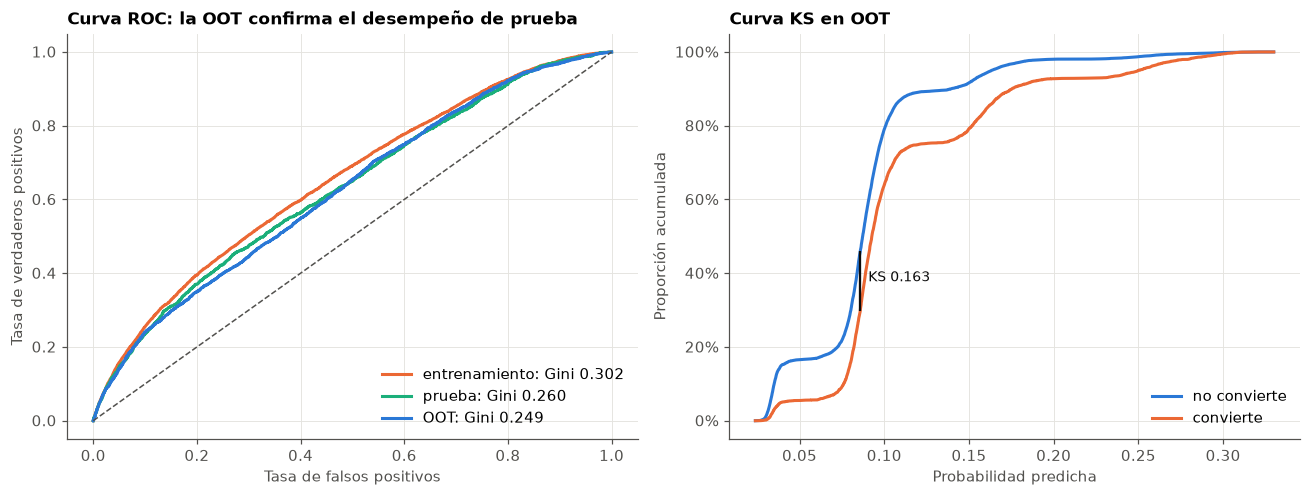

,gini,auc,ks,tasa_real,prob_media,filas
entrenamiento,0.3019,0.6510,0.2043,0.1513,0.1002,64135.0
prueba,0.2596,0.6298,0.1814,0.1488,0.1010,16165.0
oot,0.2490,0.6245,0.1626,0.1497,0.0928,29800.0


In [47]:
metricas = pd.DataFrame({
    nombre: {'gini': gini(y, p), 'auc': roc_auc_score(y, p), 'ks': ks(y, p), 'tasa_real': y.mean(), 'prob_media': p.mean(), 'filas': len(y)}
    for nombre, y, p in (('entrenamiento', y_trn, p_trn), ('prueba', y_tst, p_tst), ('oot', y_oot, p_oot))}).T
metricas.to_csv(ART / '13_metricas_finales.csv')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
for (nombre, y, p), color in zip((('entrenamiento', y_trn, p_trn), ('prueba', y_tst, p_tst), ('OOT', y_oot, p_oot)), (NARANJA, AQUA, AZUL)):
    fpr, tpr, _ = roc_curve(y, p)
    a1.plot(fpr, tpr, color=color, lw=2, label=f'{nombre}: Gini {gini(y, p):.3f}')
a1.plot([0, 1], [0, 1], color=TINTA2, ls='--', lw=1)
a1.set_xlabel('Tasa de falsos positivos')
a1.set_ylabel('Tasa de verdaderos positivos')
a1.legend(loc='lower right')
a1.set_title('Curva ROC: la OOT confirma el desempeño de prueba')
orden_p = np.sort(p_oot)
fa1 = np.searchsorted(np.sort(p_oot[y_oot == 1]), orden_p, side='right') / (y_oot == 1).sum()
fa0 = np.searchsorted(np.sort(p_oot[y_oot == 0]), orden_p, side='right') / (y_oot == 0).sum()
i_ks = np.argmax(fa0 - fa1)
a2.plot(orden_p, fa0, color=AZUL, label='no convierte')
a2.plot(orden_p, fa1, color=NARANJA, label='convierte')
a2.vlines(orden_p[i_ks], fa1[i_ks], fa0[i_ks], color=TINTA, lw=1.5)
a2.text(orden_p[i_ks], (fa0[i_ks] + fa1[i_ks]) / 2, f'  KS {fa0[i_ks] - fa1[i_ks]:.3f}', fontsize=9, color=TINTA)
a2.set_xlabel('Probabilidad predicha')
a2.set_ylabel('Proporción acumulada')
a2.yaxis.set_major_formatter(PCT)
a2.legend(loc='lower right')
a2.set_title('Curva KS en OOT')
fig.tight_layout()
guardar(fig, '26_curva_roc_y_ks')
metricas.round(4)

**Lectura.** El Gini es de 0,302 en entrenamiento, 0,260 en prueba y 0,249 en OOT, con un AUC de 0,625 y un KS de 0,163 en OOT. La caída de prueba a OOT es de solo 0,011, así que el modelo generaliza a meses futuros. Para referencia, el documento de cobranzas reporta un Gini de 0,52 en un problema con información de pagos y buró; aquí las variables son fijas y la señal, más débil.

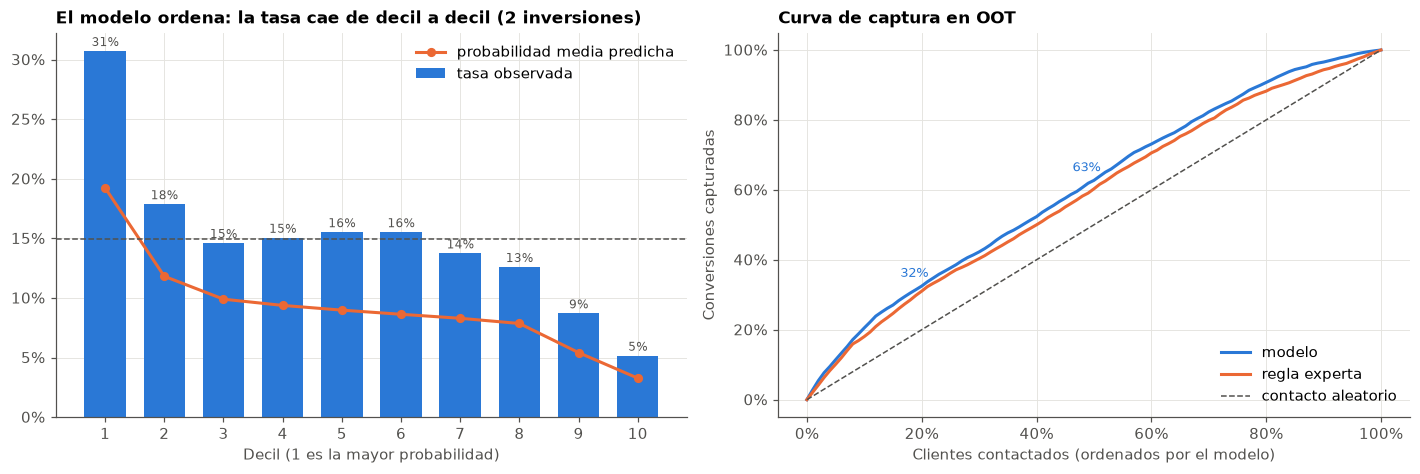

,porcentaje_contactado,captura_modelo,captura_regla,captura_aleatoria,conversiones_extra_vs_aleatorio_por_cada_1000
0,0.1,0.205,0.180,0.1,15.772
1,0.2,0.325,0.310,0.2,18.691
2,0.3,0.423,0.403,0.3,18.356
3,0.5,0.627,0.603,0.5,19.027


,clientes,conversiones,tasa_observada,prob_media,prob_min,prob_max,captura_acumulada,tasa_acumulada,lift
decil,,,,,,,,,
1,2980,916.0,0.3074,0.1924,0.1509,0.3299,0.2054,0.3074,2.0538
2,2980,533.0,0.1789,0.1182,0.1027,0.1509,0.3249,0.2431,1.1951
3,2980,436.0,0.1463,0.0990,0.0960,0.1027,0.4226,0.2109,0.9776
4,2980,449.0,0.1507,0.0938,0.0917,0.0960,0.5233,0.1958,1.0067
5,2980,463.0,0.1554,0.0898,0.0881,0.0917,0.6271,0.1877,1.0381
6,2980,463.0,0.1554,0.0863,0.0847,0.0881,0.7309,0.1823,1.0381
7,2980,410.0,0.1376,0.0830,0.0811,0.0846,0.8229,0.1759,0.9193
8,2980,376.0,0.1262,0.0786,0.0751,0.0811,0.9072,0.1697,0.8430
9,2980,260.0,0.0872,0.0542,0.0356,0.0751,0.9655,0.1606,0.5830


In [48]:
eficiencia_oot = tabla_eficiencia(y_oot, p_oot)
eficiencia_prueba = tabla_eficiencia(y_tst, p_tst)
eficiencia_oot.to_csv(ART / '13_tabla_eficiencia_oot.csv')
eficiencia_prueba.to_csv(ART / '13_tabla_eficiencia_prueba.csv')
inversiones = int((np.diff(eficiencia_oot.tasa_observada.values) > 0).sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
a1.bar(eficiencia_oot.index, eficiencia_oot.tasa_observada, color=AZUL, width=0.7, label='tasa observada')
a1.plot(eficiencia_oot.index, eficiencia_oot.prob_media, color=NARANJA, marker='o', ms=5, label='probabilidad media predicha')
a1.axhline(y_oot.mean(), color=TINTA2, ls='--', lw=1)
for d, v in zip(eficiencia_oot.index, eficiencia_oot.tasa_observada):
    a1.text(d, v + 0.004, f'{v:.0%}', ha='center', fontsize=8, color=TINTA2)
a1.set_xticks(eficiencia_oot.index)
a1.set_xlabel('Decil (1 es la mayor probabilidad)')
a1.yaxis.set_major_formatter(PCT)
a1.legend(loc='upper right')
a1.set_title(f'El modelo ordena: la tasa cae de decil a decil ({inversiones} inversiones)')

pct = np.linspace(0, 1, 101)
def captura(y, p):
    orden_idx = np.argsort(-np.asarray(p), kind='stable')
    acumulado = np.cumsum(np.asarray(y)[orden_idx]) / np.sum(y)
    return np.interp(pct, np.arange(1, len(y) + 1) / len(y), acumulado)
cap_modelo = captura(y_oot, p_oot)
cap_regla = captura(y_oot, predicciones_oot['Regla experta de negocio'] + rng.uniform(0, 0.01, len(y_oot)))
a2.plot(pct, cap_modelo, color=AZUL, label='modelo')
a2.plot(pct, cap_regla, color=NARANJA, label='regla experta')
a2.plot(pct, pct, color=TINTA2, ls='--', lw=1, label='contacto aleatorio')
for q in (0.2, 0.5):
    a2.annotate(f'{cap_modelo[int(q * 100)]:.0%}', (q, cap_modelo[int(q * 100)]), textcoords='offset points', xytext=(-14, 6), fontsize=8.5, color=AZUL)
a2.xaxis.set_major_formatter(PCT)
a2.yaxis.set_major_formatter(PCT)
a2.set_xlabel('Clientes contactados (ordenados por el modelo)')
a2.set_ylabel('Conversiones capturadas')
a2.legend(loc='lower right')
a2.set_title('Curva de captura en OOT')
fig.tight_layout()
guardar(fig, '27_eficiencia_deciles_y_captura')
capacidad = pd.DataFrame({'porcentaje_contactado': [0.1, 0.2, 0.3, 0.5],
                          'captura_modelo': [cap_modelo[i] for i in (10, 20, 30, 50)],
                          'captura_regla': [cap_regla[i] for i in (10, 20, 30, 50)],
                          'captura_aleatoria': [0.1, 0.2, 0.3, 0.5]})
capacidad['conversiones_extra_vs_aleatorio_por_cada_1000'] = (capacidad.captura_modelo - capacidad.captura_aleatoria) * y_oot.mean() * 1000
capacidad.to_csv(ART / '13_captura_por_capacidad.csv', index=False)
display(capacidad.round(3))
eficiencia_oot.round(4)

**Lectura.** El decil 1 convierte 30,7 por ciento, el doble del promedio (lift de 2,05), y el decil 10 solo 5,2 por ciento. Entre los deciles 3 y 6 la tasa es casi plana, alrededor del 15 por ciento, con pequeñas inversiones: el modelo separa bien los extremos y poco el centro, algo típico de una señal débil. En la curva de captura, contactar al 20 por ciento con mayor score captura el 32,5 por ciento de las conversiones (31,0 con la regla experta y 20 al azar), y contactar a la mitad captura el 62,7 por ciento. Por cada mil clientes de la cartera, contactar al 20 por ciento elegido por el modelo genera unas 19 conversiones más que contactar al mismo número de clientes al azar.

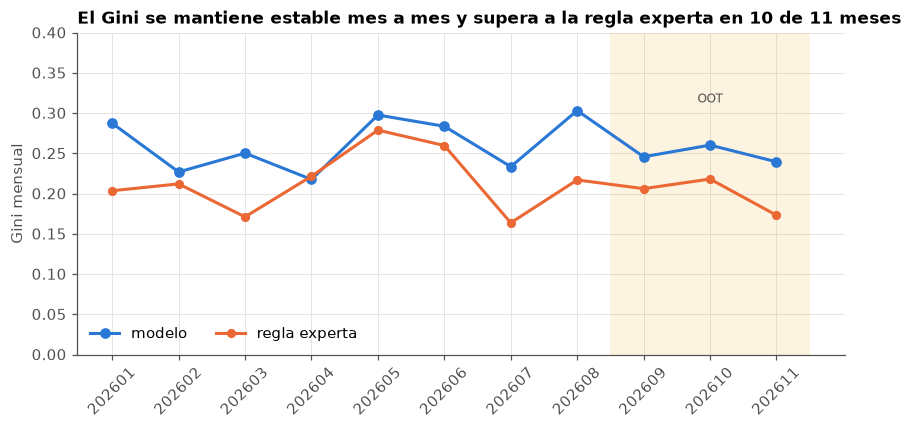

PSI del score: {'prueba vs OOT': 0.0385, 'prueba vs diciembre': 0.0479}


,mes,muestra,gini,ks,filas,gini_regla
0,202601,prueba,0.2875,0.2338,2086,0.2037
1,202602,prueba,0.2270,0.1645,1976,0.2122
2,202603,prueba,0.2504,0.1930,2053,0.1712
3,202604,prueba,0.2177,0.1527,1927,0.2217
4,202605,prueba,0.2978,0.2277,2014,0.2790
5,202606,prueba,0.2838,0.2070,2110,0.2599
6,202607,prueba,0.2336,0.1705,1968,0.1638
7,202608,prueba,0.3033,0.2131,2031,0.2171
8,202609,OOT,0.2459,0.1650,9900,0.2062
9,202610,OOT,0.2604,0.1737,10400,0.2182


In [49]:
filas = []
for mes in sorted(panel.loc[es_train, 'mes'].unique()):
    mk = (m_tst | m_oot) & (panel.mes == mes)
    p = predecir_configuracion(modelos_dev, mk)
    y = panel.loc[mk, TARGET].astype(int)
    filas.append({'mes': mes, 'muestra': 'OOT' if mes >= 202609 else 'prueba', 'gini': gini(y, p), 'ks': ks(y, p), 'filas': len(y),
                  'gini_regla': gini(y, regla(panel.loc[mk]))})
temporal = pd.DataFrame(filas)
temporal.to_csv(ART / '13_desempeno_temporal.csv', index=False)
psi_score = {'prueba vs OOT': psi(p_tst, p_oot), 'prueba vs diciembre': psi(p_tst, p_dic_dev)}

fig, ax = plt.subplots(figsize=(9, 3.8))
xx = np.arange(len(temporal))
ax.plot(xx, temporal.gini, color=AZUL, marker='o', ms=6, label='modelo')
ax.plot(xx, temporal.gini_regla, color=NARANJA, marker='o', ms=5, label='regla experta')
ax.axvspan(7.5, 10.5, color=AMARILLO, alpha=0.12, lw=0)
ax.text(9, temporal.gini.max() + 0.01, 'OOT', ha='center', fontsize=8, color=TINTA2)
ax.set_xticks(xx)
ax.set_xticklabels(temporal.mes.astype(str), rotation=45)
ax.set_ylim(0, max(0.4, temporal.gini.max() + 0.05))
ax.set_ylabel('Gini mensual')
ax.legend(loc='lower left', ncol=2)
meses_gana = int((temporal.gini > temporal.gini_regla).sum())
ax.set_title(f'El Gini se mantiene estable mes a mes y supera a la regla experta en {meses_gana} de {len(temporal)} meses')
guardar(fig, '28_desempeno_temporal')
print('PSI del score:', {k: round(v, 4) for k, v in psi_score.items()})
temporal.round(4)

**Lectura.** El Gini mensual va de 0,218 a 0,303 en los meses de prueba, que tienen unas 2000 filas cada uno, y de 0,240 a 0,260 en la OOT, sin tendencia a la baja: el modelo no se degrada con el tiempo. Supera a la regla experta en 10 de 11 meses; la excepción es abril, por 0,004. El PSI del score es de 0,039 entre prueba y OOT y de 0,048 entre prueba y diciembre, ambos estables.

## 14. Calibración, score de 0 a 1000, niveles y prioridad

El documento calibra el score con regresión isotónica y valida la calibración por deciles. Aquí se comparan tres opciones, todas ajustadas con las predicciones de la muestra de prueba y evaluadas en OOT:

* Sin calibrar: la probabilidad del LightGBM.
* Platt: una regresión logística sobre el logit de la probabilidad. Es estrictamente monótona y conserva el orden, por lo tanto el Gini.
* Isotónica: la del documento. Es monótona pero escalonada, de modo que crea empates que pueden reducir ligeramente el Gini.

La métrica de calibración es el puntaje de Brier y el error de calibración esperado (ECE) por deciles.

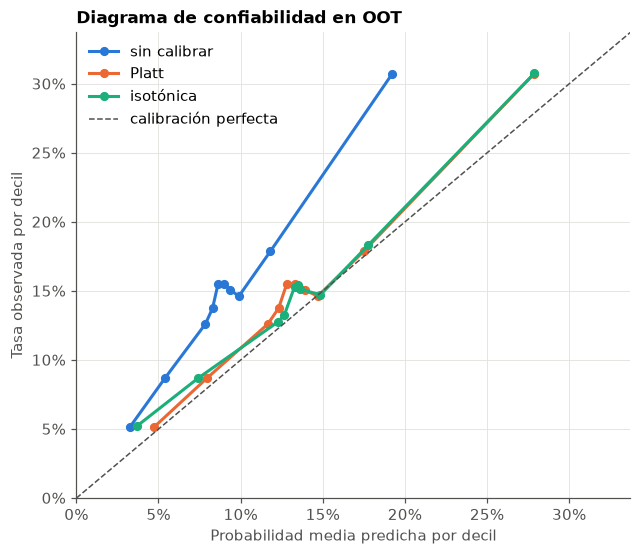

Método de calibración elegido: Platt


,metodo,gini_oot,brier_oot,ece_oot,prob_media_oot,valores_distintos
0,sin calibrar,0.24901,0.12665,0.05687,0.09280,12521
1,Platt,0.24901,0.12305,0.01293,0.13688,12521
2,isotónica,0.25172,0.12326,0.01295,0.13698,114


In [50]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def ece(y, p, n=10):
    t = tabla_eficiencia(y, p, n)
    return float(np.sum(t.clientes / t.clientes.sum() * np.abs(t.tasa_observada - t.prob_media)))

platt = LogisticRegression(C=1e6).fit(logit(p_tst), y_tst)
isotonica = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(p_tst, y_tst)
calibradores = {'sin calibrar': lambda p: p, 'Platt': lambda p: platt.predict_proba(logit(p))[:, 1], 'isotónica': lambda p: isotonica.predict(p)}
filas = []
for nombre, f in calibradores.items():
    pc = f(p_oot)
    filas.append({'metodo': nombre, 'gini_oot': gini(y_oot, pc), 'brier_oot': brier_score_loss(y_oot, pc), 'ece_oot': ece(y_oot, pc),
                  'prob_media_oot': pc.mean(), 'valores_distintos': len(np.unique(pc))})
tabla_calibracion = pd.DataFrame(filas)
gini_crudo = tabla_calibracion.gini_oot.iloc[0]
aptos = tabla_calibracion[tabla_calibracion.gini_oot >= gini_crudo - 0.0005]
METODO_CAL = aptos.sort_values('brier_oot').metodo.iloc[0]
calibrar = calibradores[METODO_CAL]
tabla_calibracion.to_csv(ART / '14_comparacion_calibradores.csv', index=False)
joblib.dump({'platt': platt, 'isotonica': isotonica, 'metodo_elegido': METODO_CAL}, ART / '14_calibradores.joblib')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (nombre, f), color in zip(calibradores.items(), (AZUL, NARANJA, AQUA)):
    t = tabla_eficiencia(y_oot, f(p_oot))
    ax.plot(t.prob_media, t.tasa_observada, color=color, marker='o', ms=5, label=nombre)
lim = max(eficiencia_oot.tasa_observada.max(), eficiencia_oot.prob_media.max()) + 0.03
ax.plot([0, lim], [0, lim], color=TINTA2, ls='--', lw=1, label='calibración perfecta')
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel('Probabilidad media predicha por decil')
ax.set_ylabel('Tasa observada por decil')
ax.legend(loc='upper left')
ax.set_title('Diagrama de confiabilidad en OOT')
guardar(fig, '29_calibracion_confiabilidad')
print('Método de calibración elegido:', METODO_CAL)
tabla_calibracion.round(5)

In [51]:
p_oot_cal = calibrar(p_oot)
validacion_cal = tabla_eficiencia(y_oot, p_oot_cal)[['clientes', 'prob_media', 'tasa_observada']]
validacion_cal['delta'] = validacion_cal.prob_media - validacion_cal.tasa_observada
validacion_cal.to_csv(ART / '14_validacion_calibracion_deciles.csv')
validacion_cal.round(4)

,clientes,prob_media,tasa_observada,delta
decil,,,,
1,2980,0.2787,0.3074,-0.0287
2,2980,0.1751,0.1789,-0.0038
3,2980,0.1470,0.1463,0.0007
4,2980,0.1393,0.1507,-0.0114
5,2980,0.1334,0.1554,-0.0220
6,2980,0.1282,0.1554,-0.0272
7,2980,0.1232,0.1376,-0.0144
8,2980,0.1166,0.1262,-0.0095
9,2980,0.0798,0.0872,-0.0074


**Lectura.** El LightGBM sin calibrar subestima la probabilidad (media de 9,3 por ciento frente a una tasa real de 15) porque Optuna eligió un scale_pos_weight de 0,61. Platt corrige el nivel: el ECE baja de 0,057 a 0,013 y el Brier de 0,1267 a 0,1231, sin cambiar el orden ni el Gini. La isotónica del documento calibra igual de bien, pero reduce las predicciones a 114 valores distintos y crea empates; aquí sube el Gini OOT en 0,003, una variación del orden del ruido que no compensa perder la garantía de orden estricto. Se elige Platt. Por deciles, la diferencia entre probabilidad y tasa observada es menor que 1,5 puntos en 7 de 10 deciles, con subestimación en el decil 1 (2,9 puntos) y en los deciles 5 y 6 (2,2 y 2,7 puntos).

### 14.1 Score de 0 a 1000, niveles de propensión y score de prioridad

Se replican las salidas de negocio del documento:

* **Score de 0 a 1000**: escalado MinMax de la probabilidad calibrada con los valores mínimo y máximo de la población de entrenamiento. Un score más alto indica mayor propensión.
* **Niveles**: cinco grupos por pares de deciles, de muy alto (deciles 1 y 2) a muy bajo (deciles 9 y 10). Los cortes se fijan con la muestra de prueba y se aplican sin cambios a OOT y diciembre.
* **Score de prioridad**: el documento pondera la probabilidad de pago por la deuda. En un problema comercial el equivalente es el valor potencial del cliente, que aproximamos con el saldo promedio: prioridad igual a probabilidad por el logaritmo de uno más el saldo. Así se priorizan clientes con alta propensión y alto valor.

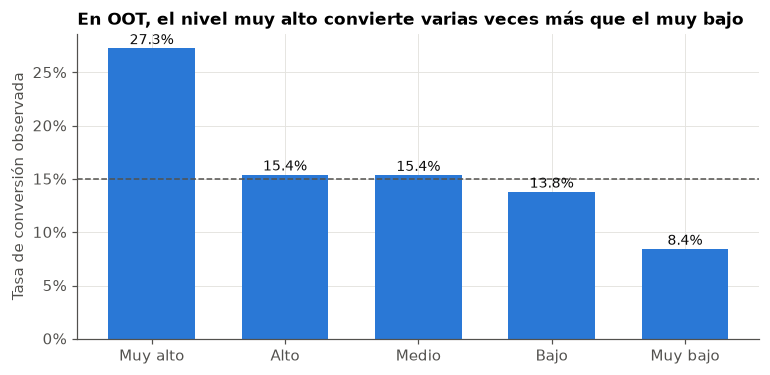

,nivel,prob_desde,prob_hasta
0,Muy bajo,0.0000,0.1180
1,Bajo,0.1180,0.1296
2,Medio,0.1296,0.1405
3,Alto,0.1405,0.1643
4,Muy alto,0.1643,1.0000


,clientes,tasa_observada,prob_media,score_min,score_max,saldo_medio
nivel,,,,,,
Muy alto,4380,0.2726,0.2520,307.2289,1000.0000,27439.3400
Alto,5474,0.1540,0.1491,250.3870,307.1871,28912.0746
Medio,5722,0.1536,0.1348,224.3099,250.3865,27253.3144
Bajo,6439,0.1379,0.1240,196.6560,224.2965,24554.0879
Muy bajo,7785,0.0843,0.0757,0.0000,196.6248,23844.6083


In [52]:
p_trn_cal, p_tst_cal = calibrar(p_trn), calibrar(p_tst)
MIN_SCORE, MAX_SCORE = float(p_trn_cal.min()), float(p_trn_cal.max())
def score_1000(p):
    return np.clip((p - MIN_SCORE) / (MAX_SCORE - MIN_SCORE) * 1000, 0, 1000)

NOMBRES_NIVEL = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']
CORTES_NIVEL = np.quantile(p_tst_cal, [0.2, 0.4, 0.6, 0.8]).tolist()
def nivel(p):
    return pd.Categorical(np.array(NOMBRES_NIVEL)[np.searchsorted(CORTES_NIVEL, p, side='right')], categories=NOMBRES_NIVEL[::-1], ordered=True)

oot_neg = panel.loc[m_oot, ['id_cliente', 'mes', TARGET, 'saldo_promedio']].assign(probabilidad=p_oot_cal, score=score_1000(p_oot_cal), nivel=nivel(p_oot_cal))
oot_neg['prioridad_bruta'] = oot_neg.probabilidad * np.log1p(oot_neg.saldo_promedio)
pri_tst = p_tst_cal * np.log1p(panel.loc[m_tst, 'saldo_promedio'].values)
MIN_PRI, MAX_PRI = float(pri_tst.min()), float(pri_tst.max())
oot_neg['score_prioridad'] = np.clip((oot_neg.prioridad_bruta - MIN_PRI) / (MAX_PRI - MIN_PRI) * 1000, 0, 1000)
niveles_oot = oot_neg.groupby('nivel', observed=True).agg(clientes=(TARGET, 'size'), tasa_observada=(TARGET, 'mean'),
                                                          prob_media=('probabilidad', 'mean'), score_min=('score', 'min'),
                                                          score_max=('score', 'max'), saldo_medio=('saldo_promedio', 'mean'))
rangos = pd.DataFrame({'nivel': NOMBRES_NIVEL, 'prob_desde': [0] + CORTES_NIVEL, 'prob_hasta': CORTES_NIVEL + [1]})
niveles_oot.to_csv(ART / '14_niveles_oot.csv')
rangos.to_csv(ART / '14_rangos_niveles.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(niveles_oot.index.astype(str), niveles_oot.tasa_observada, color=[AZUL] * len(niveles_oot), width=0.65)
for i, (v, n) in enumerate(zip(niveles_oot.tasa_observada, niveles_oot.clientes)):
    ax.text(i, v + 0.004, f'{v:.1%}', ha='center', fontsize=9, color=TINTA)
ax.axhline(y_oot.mean(), color=TINTA2, ls='--', lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel('Tasa de conversión observada')
ax.set_title('En OOT, el nivel muy alto convierte varias veces más que el muy bajo')
guardar(fig, '30_tasa_por_nivel_oot')
display(rangos.round(4))
niveles_oot.round(4)

**Lectura.** Los niveles ordenan de forma monótona, con un empate entre alto y medio: muy alto convierte 27,3 por ciento; alto, 15,4; medio, 15,4; bajo, 13,8; y muy bajo, 8,4. El nivel muy alto convierte 3,2 veces más que el muy bajo. Para la gestión, los niveles extremos concentran la información y los tres intermedios se comportan como el promedio.

## 15. Entrenamiento final y envío

El modelo final usa la configuración elegida y se reentrena con todos los meses etiquetados, de enero a noviembre, para aprovechar la información más reciente. Así lo hace el documento al implementar: la OOT sirve para validar y luego se incorpora. Los hiperparámetros, incluido el número de árboles, no cambian. Se verifica que el orden de diciembre del modelo final sea consistente con el del modelo de desarrollo.

In [53]:
t0 = time.time()
modelos_finales = entrenar_configuracion(m_todo)
p_dic_crudo = predecir_configuracion(modelos_finales, m_dic)
p_dic = calibrar(p_dic_crudo)
print(f'Modelo final entrenado en {time.time() - t0:.1f} s con {int(m_todo.sum())} filas')
consistencia = {'spearman_dev_vs_final_diciembre': float(stats.spearmanr(p_dic_dev, p_dic_crudo).statistic),
                'prob_media_diciembre': float(p_dic.mean()), 'tasa_historica': float(tasa_global),
                'psi_score_oot_vs_diciembre': psi(calibrar(p_oot), p_dic)}
consistencia

Modelo final entrenado en 5.1 s con 110100 filas


{'spearman_dev_vs_final_diciembre': 0.9744655940727647,
 'prob_media_diciembre': 0.1368294033495257,
 'tasa_historica': 0.15047229791099,
 'psi_score_oot_vs_diciembre': 0.04137982410366749}

In [54]:
pred_dic = pd.DataFrame({'id_cliente': panel.loc[m_dic, 'id_cliente'].values, 'prediccion': p_dic})
submission = te_raw[['id_cliente']].merge(pred_dic, on='id_cliente', how='left', validate='one_to_one')
assert len(submission) == len(te_raw) == len(ss_raw)
assert list(submission.columns) == list(ss_raw.columns) == ['id_cliente', 'prediccion']
assert (submission.id_cliente.values == ss_raw.id_cliente.values).all()
assert submission.prediccion.notna().all() and submission.prediccion.between(0, 1).all()
submission.to_csv(ENT / 'submission.csv', index=False)

priorizacion = panel.loc[m_dic, ['id_cliente', 'saldo_promedio', 'banda_riesgo', 'numero_productos']].assign(
    probabilidad=p_dic, score=score_1000(p_dic), nivel=nivel(p_dic))
priorizacion['score_prioridad'] = np.clip((priorizacion.probabilidad * np.log1p(priorizacion.saldo_promedio) - MIN_PRI) / (MAX_PRI - MIN_PRI) * 1000, 0, 1000)
priorizacion = priorizacion.sort_values('score_prioridad', ascending=False)
priorizacion.to_csv(ENT / 'priorizacion_diciembre.csv', index=False)
resumen_dic = priorizacion.groupby('nivel', observed=True).agg(clientes=('id_cliente', 'size'), prob_media=('probabilidad', 'mean'),
                                                              conversiones_esperadas=('probabilidad', 'sum'))
print(f'Envío guardado: {len(submission)} filas, predicción entre {submission.prediccion.min():.4f} y {submission.prediccion.max():.4f}')
display(submission.head())
resumen_dic.round(3)

Envío guardado: 9900 filas, predicción entre 0.0313 y 0.4510


,id_cliente,prediccion
0,2,0.133144
1,3,0.056806
2,7,0.129179
3,10,0.056791
4,11,0.141399


,clientes,prob_media,conversiones_esperadas
nivel,,,
Muy alto,1387,0.254,352.716
Alto,2002,0.149,297.460
Medio,2174,0.135,293.263
Bajo,1943,0.124,241.786
Muy bajo,2394,0.071,169.386


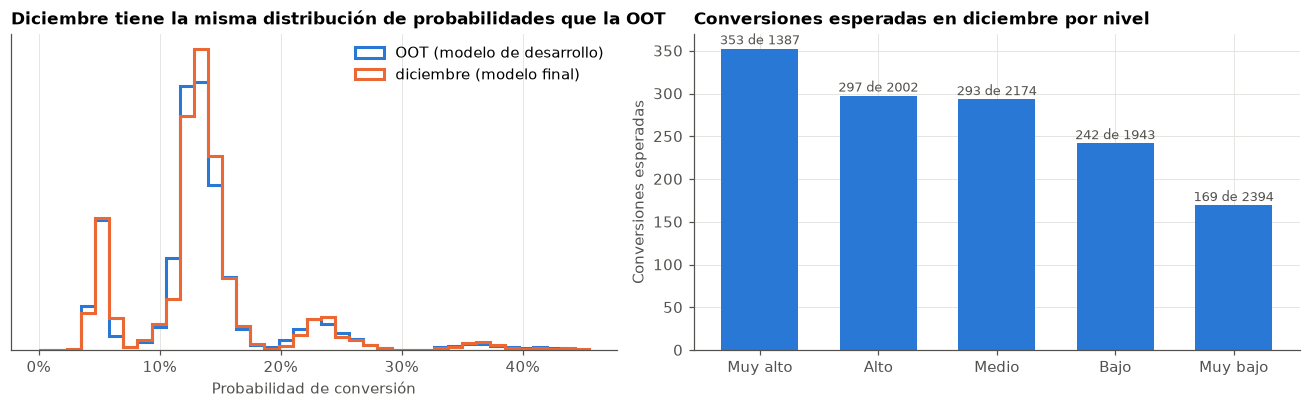

In [55]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, max(p_dic.max(), calibrar(p_oot).max()), 40)
a1.hist(calibrar(p_oot), bins=bins, density=True, histtype='step', color=AZUL, lw=2, label='OOT (modelo de desarrollo)')
a1.hist(p_dic, bins=bins, density=True, histtype='step', color=NARANJA, lw=2, label='diciembre (modelo final)')
a1.xaxis.set_major_formatter(PCT)
a1.set_yticks([])
a1.legend(loc='upper right')
a1.set_xlabel('Probabilidad de conversión')
a1.set_title('Diciembre tiene la misma distribución de probabilidades que la OOT')
a2.bar(resumen_dic.index.astype(str), resumen_dic.conversiones_esperadas, color=AZUL, width=0.65)
for i, (v, n) in enumerate(zip(resumen_dic.conversiones_esperadas, resumen_dic.clientes)):
    a2.text(i, v + 5, f'{v:.0f} de {n}', ha='center', fontsize=8.5, color=TINTA2)
a2.set_ylabel('Conversiones esperadas')
a2.set_title('Conversiones esperadas en diciembre por nivel')
fig.tight_layout()
guardar(fig, '31_diciembre_distribucion_y_niveles')

**Lectura.** El modelo final, reentrenado con enero a noviembre, ordena diciembre casi igual que el de desarrollo (correlación de Spearman de 0,97) y produce una distribución de probabilidades similar a la de OOT (PSI de 0,041). La probabilidad media de diciembre es 13,7 por ciento, algo debajo de la tasa histórica de 15,0, así que el modelo es levemente conservador en nivel, sin efecto sobre el Gini. Se esperan unas 1355 conversiones en diciembre, y el nivel muy alto concentra 353 de ellas en solo 1387 clientes.

## 16. Artefactos, supuestos y siguientes pasos

In [56]:
for s, m in zip(SEMILLAS_FINAL, modelos_finales):
    m.booster_.save_model(str(ART / f'15_modelo_final_lgbm_semilla_{s}.txt'))
joblib.dump(modelos_finales, ART / '15_modelos_finales.joblib')
joblib.dump(modelos_dev, ART / '15_modelos_desarrollo.joblib')
resumen_final = {
    'problema': 'Propensión a la primera conversión mensual (familia marketing, supervivencia discreta)',
    'variables_finales': FINALES,
    'variables_excluidas_por_fuga_o_deriva': ['id_cliente', 'mes', SOSPECHOSA, 'meses_previos_panel', 'cliente_conocido'],
    'eleccion_modelo': ELECCION,
    'hiperparametros': {k: v for k, v in PARAMS_FINAL.items()},
    'metricas': metricas.round(4).to_dict(orient='index'),
    'gini_oot_regla_experta': float(zoologico.set_index('modelo').loc['Regla experta de negocio', 'gini_oot']),
    'calibracion': METODO_CAL,
    'cortes_niveles': dict(zip(NOMBRES_NIVEL[1:], CORTES_NIVEL)),
    'escalado_score': {'min': MIN_SCORE, 'max': MAX_SCORE},
    'consistencia_diciembre': consistencia,
    'psi_score': psi_score,
    'envio': str(ENT / 'submission.csv'),
}
with open(ART / '16_resumen_final.json', 'w') as f:
    json.dump(resumen_final, f, indent=2, ensure_ascii=False, default=str)
sorted(p.name for p in ART.iterdir())

['00_versiones.csv',
 '03_calidad_columnas.csv',
 '04_embudo_poblacion.csv',
 '04_ventanas_muestras.csv',
 '05_frecuencias_categoricas.csv',
 '05_pruebas_estadisticas_iv.csv',
 '05_psi_variables.csv',
 '05_tabla_descriptiva.csv',
 '06_auditoria_univariante.csv',
 '06_deriva_interaccion.csv',
 '06_esquemas_validacion.csv',
 '06_resumen_pruebas_fuga.csv',
 '06_validacion_adversarial.csv',
 '06_variables_futuro.csv',
 '07_ablacion_ingenieria_variables.csv',
 '07_decision_ingenieria_variables.csv',
 '07_registro_hipotesis.csv',
 '08_curva_parsimonia.csv',
 '08_embudo_seleccion.csv',
 '08_variables_finales.json',
 '09_zoologico_modelos.csv',
 '10_historial_optuna.csv',
 '10_mejores_hiperparametros.json',
 '11_ablaciones.csv',
 '12_importancia_shap_relativa.csv',
 '12_validacion_sentido_negocio.csv',
 '13_captura_por_capacidad.csv',
 '13_desempeno_temporal.csv',
 '13_metricas_finales.csv',
 '13_tabla_eficiencia_oot.csv',
 '13_tabla_eficiencia_prueba.csv',
 '14_calibradores.joblib',
 '14_comp

### Supuestos

1. La conversión es la primera contratación o activación de un producto u oferta comercial, porque el reto no nombra el producto. Por eso el problema se encuadra como propensión comercial y no como riesgo de crédito.
2. Todas las variables están disponibles al inicio del mes de observación. El diccionario no indica su fecha de corte; si alguna se midiera al cierre del mes, habría que desfasarla un mes, como hace el documento al calcular variables al día 27.
3. dias_ultima_interaccion se reemplaza con valores sin relación con el target; se interpreta como un artefacto del proceso de generación o de carga del dato. Si el banco confirmara que la variable de diciembre es correcta, podría reevaluarse con una ventana más reciente.
4. Diciembre se comporta como los meses anteriores. Diciembre suele traer campañas comerciales; el documento detectó un aumento de la tasa en diciembre de 2024. Si existiera una campaña, la probabilidad calibrada subestimaría el nivel, aunque el orden, que es lo que mide el Gini, se mantendría.
5. El saldo promedio es una aproximación razonable del valor potencial del cliente para el score de prioridad, a falta de un dato de margen o rentabilidad.

### Siguientes pasos para la etapa final del Datafest

1. Confirmar con el banco la definición del evento, el producto ofrecido y la fecha de corte de cada variable, y cerrar la población objetivo con filtros de negocio (clientes contactables, sin oferta vigente, sin exclusiones regulatorias).
2. Agregar variables de comportamiento con evolución temporal (transacciones, saldos y uso de canales mes a mes), que son las que más aportaron en el documento y las que faltan aquí; con variables fijas el techo de Gini es bajo.
3. Pasar de propensión a efecto incremental con un grupo de control: contactar a quien convierte solo por ser contactado, no a quien iba a convertir igual.
4. Convertir el score en una decisión con optimización: elegir a quién contactar y por qué canal para maximizar las conversiones esperadas sujeto a la capacidad del centro de contacto y al presupuesto, con programación entera (OR Tools o PuLP con HiGHS).
5. Monitorear en producción el PSI del score y de cada variable, el Gini mensual y la calibración por deciles, y recalibrar o reentrenar cuando el PSI supere 0,1 o el Gini caiga más de cinco puntos.